# Restaurant Growth Potential Modeling & Strategic Classification System

## Project Overview

This project aims to analyze restaurant business performance and identify
their potential for sustainable growth.

The system evaluates restaurants based on business scale, growth factor,
average order value, operating costs, profitability, delivery channels,
and geographic reach.

The objective is to classify restaurants into meaningful strategic
categories and support data-driven business decisions.

## Objectives

1. Analyze restaurant business performance.
2. Identify revenue and profitability patterns.
3. Evaluate delivery channel performance.
4. Understand operational costs and growth factors.
5. Develop business-related KPIs.
6. Calculate a preliminary Growth Potential Index.
7. Prepare data for machine learning and strategic classification.

## Project Workflow

Dataset Collection
        ↓
Data Loading
        ↓
Data Understanding
        ↓
Data Cleaning
        ↓
Exploratory Data Analysis
        ↓
Business Performance Analysis
        ↓
KPI Engineering
        ↓
Growth Potential Index
        ↓
Preliminary Strategic Classification
        ↓
Export Processed Dataset

## 2. Import Required Libraries

This section imports Python libraries required for data manipulation,
statistical analysis, and visualization.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

from IPython.display import display

warnings.filterwarnings('ignore')

# Visualization settings
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Dataset Loading

The restaurant dataset contains business information such as restaurant
details, cuisine type, monthly orders, revenue, operating costs,
delivery channels, and profitability.

In [6]:
# Dataset path
file_path = os.path.join(
    "Dataset",
    "SkyCity Auckland Restaurants & Bars.csv"
)

# Load dataset
df = pd.read_csv(file_path)

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [7]:
print("Dataset Preview")

display(df.head())

Dataset Preview


,CuisineType,RestaurantID,RestaurantName,Segment,Subregion,GrowthFactor,AOV,MonthlyOrders,InStoreOrders,InStoreRevenue,...,DeliveryCostPerOrder,SD_DeliveryTotalCost,InStoreNetProfit,UberEatsNetProfit,DoorDashNetProfit,SelfDeliveryNetProfit,InStoreShare,UE_share,DD_share,SD_share
0,Burgers,25731,Urban Burgers House,Cafe,North Shore,1.03,43.97,668,197,8662.09,...,3.25,458.25,3682.14,1352.45,752.78,2177.19,0.42,0.45,0.25,0.3
1,Burgers,25123,Urban Burgers Diner,QSR,South Auckland,1.05,40.45,1388,259,10476.55,...,4.72,1600.08,3605.72,1318.61,731.99,3119.38,0.23,0.45,0.25,0.3
2,Burgers,25177,King Burgers Eatery,Cafe,West Auckland,1.04,40.03,1717,524,20975.72,...,3.25,1163.50,7810.95,1555.90,863.42,4172.99,0.44,0.45,0.25,0.3
3,Burgers,25540,Classic Burgers Tavern,QSR,North Shore,1.03,36.28,1083,216,7836.48,...,0.89,231.40,2546.02,-72.25,-40.20,2833.26,0.25,0.45,0.25,0.3
4,Burgers,25258,Lucky Burgers Bistro,Cafe,South Auckland,1.05,34.34,1230,261,8962.74,...,2.66,774.06,3093.09,226.17,125.53,2674.56,0.27,0.45,0.25,0.3


In [8]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 1696
Number of Columns: 30


## 4. Dataset Understanding

This section examines the structure of the dataset, column names,
data types, and basic information.

In [10]:
print("Dataset Columns:\n")

for col in df.columns:
    print(col)

Dataset Columns:

CuisineType
RestaurantID
RestaurantName
Segment
Subregion
GrowthFactor
AOV
MonthlyOrders
InStoreOrders
InStoreRevenue
UberEatsOrders
DoorDashOrders
SelfDeliveryOrders
UberEatsRevenue
DoorDashRevenue
SelfDeliveryRevenue
COGSRate
OPEXRate
CommissionRate
DeliveryRadiusKM
DeliveryCostPerOrder
SD_DeliveryTotalCost
InStoreNetProfit
UberEatsNetProfit
DoorDashNetProfit
SelfDeliveryNetProfit
InStoreShare
UE_share
DD_share
SD_share


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1696 entries, 0 to 1695
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   CuisineType            1696 non-null   object 
 1   RestaurantID           1696 non-null   int64  
 2   RestaurantName         1696 non-null   object 
 3   Segment                1696 non-null   object 
 4   Subregion              1696 non-null   object 
 5   GrowthFactor           1696 non-null   float64
 6   AOV                    1696 non-null   float64
 7   MonthlyOrders          1696 non-null   int64  
 8   InStoreOrders          1696 non-null   int64  
 9   InStoreRevenue         1696 non-null   float64
 10  UberEatsOrders         1696 non-null   int64  
 11  DoorDashOrders         1696 non-null   int64  
 12  SelfDeliveryOrders     1696 non-null   int64  
 13  UberEatsRevenue        1696 non-null   float64
 14  DoorDashRevenue        1696 non-null   float64
 15  Self

In [12]:
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CuisineType,1696,8,Burgers,375,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RestaurantID,1696.0,NaN,NaN,NaN,25848.5,489.737345,25001.0,25424.75,25848.5,26272.25,26696.0
RestaurantName,1696,256,Lotus Eatery,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,1696,4,QSR,543,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Subregion,1696,4,West Auckland,462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GrowthFactor,1696.0,NaN,NaN,NaN,1.028255,0.0227,0.99,1.03,1.04,1.05,1.05
AOV,1696.0,NaN,NaN,NaN,38.516887,4.459408,29.79,34.7875,38.34,42.495,47.23
MonthlyOrders,1696.0,NaN,NaN,NaN,1190.527123,422.334848,441.0,827.0,1182.0,1525.0,2337.0
InStoreOrders,1696.0,NaN,NaN,NaN,218.980542,149.758619,13.0,101.0,178.0,307.0,819.0
InStoreRevenue,1696.0,NaN,NaN,NaN,8422.39273,5851.233352,412.36,3904.3425,6791.43,11550.755,35356.23


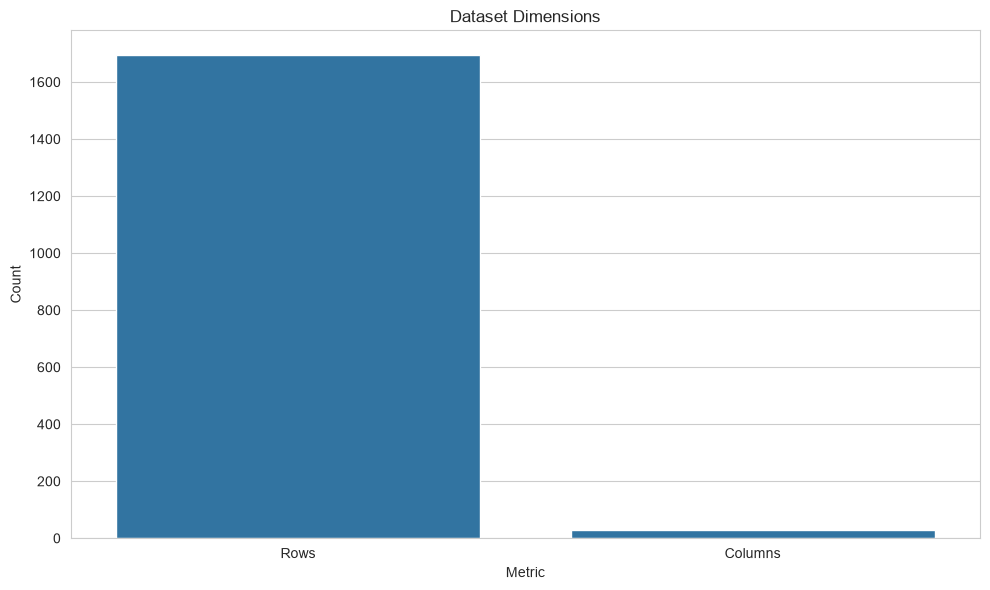

In [13]:
dataset_summary = pd.DataFrame({
    'Metric': ['Rows', 'Columns'],
    'Count': [df.shape[0], df.shape[1]]
})

sns.barplot(
    data=dataset_summary,
    x='Metric',
    y='Count'
)

plt.title('Dataset Dimensions')
plt.tight_layout()
plt.show()

## 5. Data Quality Analysis

This section checks missing values, duplicate records, and invalid
values to understand the quality of the dataset.

In [15]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    'Column': missing_values.index,
    'Missing Values': missing_values.values,
    'Missing Percentage': (
        missing_values.values / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by='Missing Values',
    ascending=False
)

display(missing_summary)

,Column,Missing Values,Missing Percentage
0,CuisineType,0,0.0
1,RestaurantID,0,0.0
28,DD_share,0,0.0
27,UE_share,0,0.0
26,InStoreShare,0,0.0
25,SelfDeliveryNetProfit,0,0.0
24,DoorDashNetProfit,0,0.0
23,UberEatsNetProfit,0,0.0
22,InStoreNetProfit,0,0.0
21,SD_DeliveryTotalCost,0,0.0


In [16]:
missing_data = missing_summary[
    missing_summary['Missing Values'] > 0
]

if not missing_data.empty:

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=missing_data,
        x='Missing Percentage',
        y='Column'
    )

    plt.title('Missing Values by Column')
    plt.xlabel('Missing Values (%)')
    plt.ylabel('Columns')
    plt.tight_layout()
    plt.show()

else:
    print("No missing values found.")

No missing values found.


In [17]:
print("Duplicate Rows:", df.duplicated().sum())

if 'RestaurantID' in df.columns:
    print(
        "Duplicate Restaurant IDs:",
        df['RestaurantID'].duplicated().sum()
    )

Duplicate Rows: 0
Duplicate Restaurant IDs: 0


In [18]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns

print("Infinite values by column:\n")

for col in numeric_columns:
    count = np.isinf(df[col]).sum()

    if count > 0:
        print(col, ":", count)

Infinite values by column:



In [19]:
df.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Infinite values replaced with missing values.")

Infinite values replaced with missing values.


## 6. Data Cleaning and Preprocessing

This section prepares the dataset for analysis by handling missing
values, correcting data types, and checking important business columns.

In [21]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    include='object'
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['RestaurantID', 'GrowthFactor', 'AOV', 'MonthlyOrders', 'InStoreOrders', 'InStoreRevenue', 'UberEatsOrders', 'DoorDashOrders', 'SelfDeliveryOrders', 'UberEatsRevenue', 'DoorDashRevenue', 'SelfDeliveryRevenue', 'COGSRate', 'OPEXRate', 'CommissionRate', 'DeliveryRadiusKM', 'DeliveryCostPerOrder', 'SD_DeliveryTotalCost', 'InStoreNetProfit', 'UberEatsNetProfit', 'DoorDashNetProfit', 'SelfDeliveryNetProfit', 'InStoreShare', 'UE_share', 'DD_share', 'SD_share']

Categorical Columns:
['CuisineType', 'RestaurantName', 'Segment', 'Subregion']


In [22]:
for col in numerical_columns:

    df[col] = pd.to_numeric(
        df[col],
        errors='coerce'
    )

    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

print("Numerical missing values handled.")

Numerical missing values handled.


In [23]:
categorical_columns = df.select_dtypes(
    include='object'
).columns.tolist()

for col in categorical_columns:

    if df[col].isnull().any():

        mode_value = df[col].mode()

        if not mode_value.empty:
            df[col] = df[col].fillna(mode_value.iloc[0])
        else:
            df[col] = df[col].fillna('Unknown')

print("Categorical missing values handled.")

Categorical missing values handled.


In [24]:
print("Remaining Missing Values:")
print(df.isnull().sum().sum())

print("\nCleaned Dataset Shape:")
print(df.shape)

display(df.head())

Remaining Missing Values:
0

Cleaned Dataset Shape:
(1696, 30)


,CuisineType,RestaurantID,RestaurantName,Segment,Subregion,GrowthFactor,AOV,MonthlyOrders,InStoreOrders,InStoreRevenue,...,DeliveryCostPerOrder,SD_DeliveryTotalCost,InStoreNetProfit,UberEatsNetProfit,DoorDashNetProfit,SelfDeliveryNetProfit,InStoreShare,UE_share,DD_share,SD_share
0,Burgers,25731,Urban Burgers House,Cafe,North Shore,1.03,43.97,668,197,8662.09,...,3.25,458.25,3682.14,1352.45,752.78,2177.19,0.42,0.45,0.25,0.3
1,Burgers,25123,Urban Burgers Diner,QSR,South Auckland,1.05,40.45,1388,259,10476.55,...,4.72,1600.08,3605.72,1318.61,731.99,3119.38,0.23,0.45,0.25,0.3
2,Burgers,25177,King Burgers Eatery,Cafe,West Auckland,1.04,40.03,1717,524,20975.72,...,3.25,1163.50,7810.95,1555.90,863.42,4172.99,0.44,0.45,0.25,0.3
3,Burgers,25540,Classic Burgers Tavern,QSR,North Shore,1.03,36.28,1083,216,7836.48,...,0.89,231.40,2546.02,-72.25,-40.20,2833.26,0.25,0.45,0.25,0.3
4,Burgers,25258,Lucky Burgers Bistro,Cafe,South Auckland,1.05,34.34,1230,261,8962.74,...,2.66,774.06,3093.09,226.17,125.53,2674.56,0.27,0.45,0.25,0.3


## 7. Categorical Data Analysis

This section analyzes restaurant categories such as cuisine type,
business segment, and subregion to understand the distribution
of restaurants across different business groups.

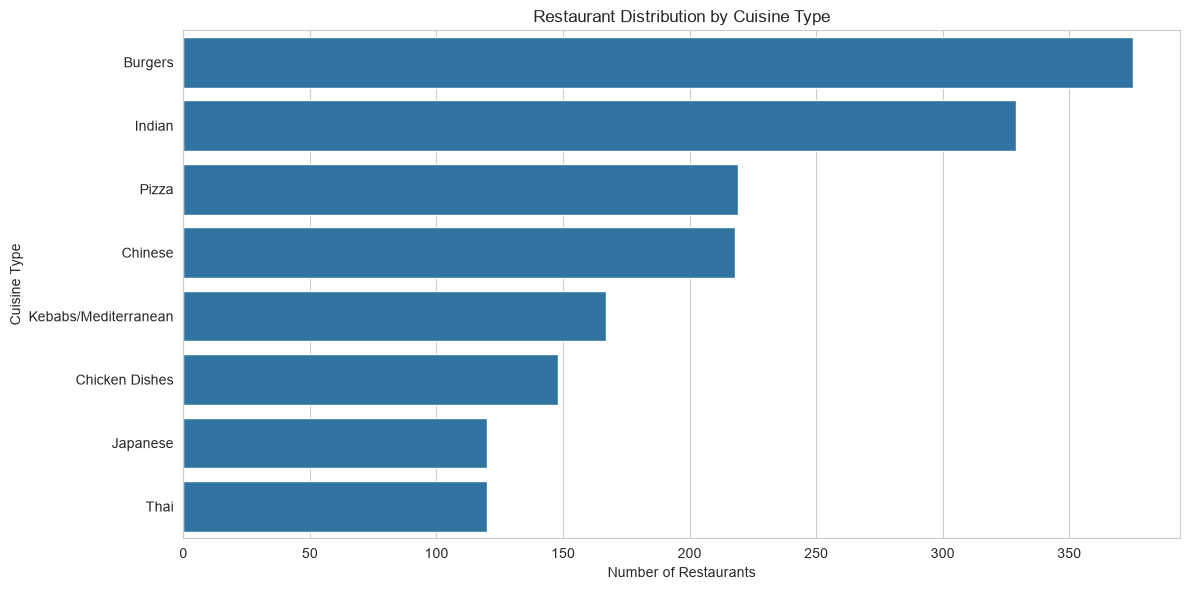

CuisineType
Burgers                 375
Indian                  329
Pizza                   219
Chinese                 218
Kebabs/Mediterranean    167
Chicken Dishes          148
Japanese                120
Thai                    120
Name: count, dtype: int64

In [26]:
if 'CuisineType' in df.columns:

    cuisine_counts = df['CuisineType'].value_counts()

    plt.figure(figsize=(12, 6))

    sns.barplot(
        x=cuisine_counts.values,
        y=cuisine_counts.index
    )

    plt.title('Restaurant Distribution by Cuisine Type')
    plt.xlabel('Number of Restaurants')
    plt.ylabel('Cuisine Type')
    plt.tight_layout()
    plt.show()

    display(cuisine_counts)

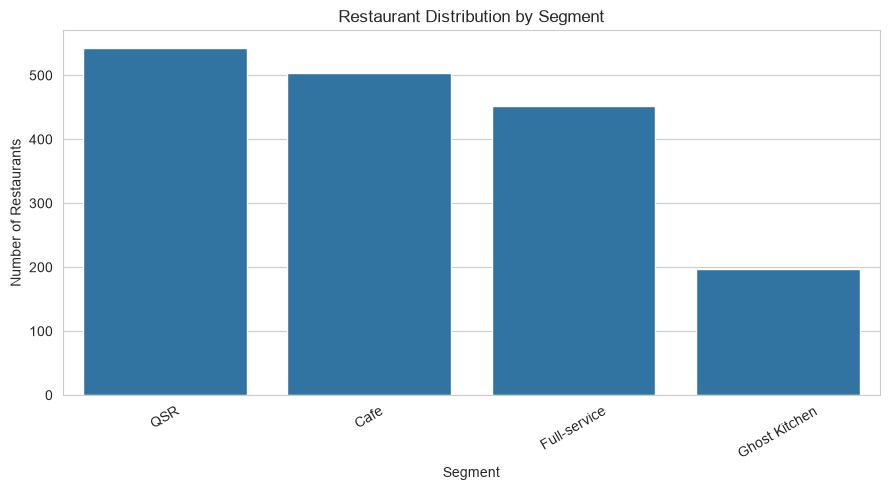

In [27]:
if 'Segment' in df.columns:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x='Segment',
        order=df['Segment'].value_counts().index
    )

    plt.title('Restaurant Distribution by Segment')
    plt.xlabel('Segment')
    plt.ylabel('Number of Restaurants')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

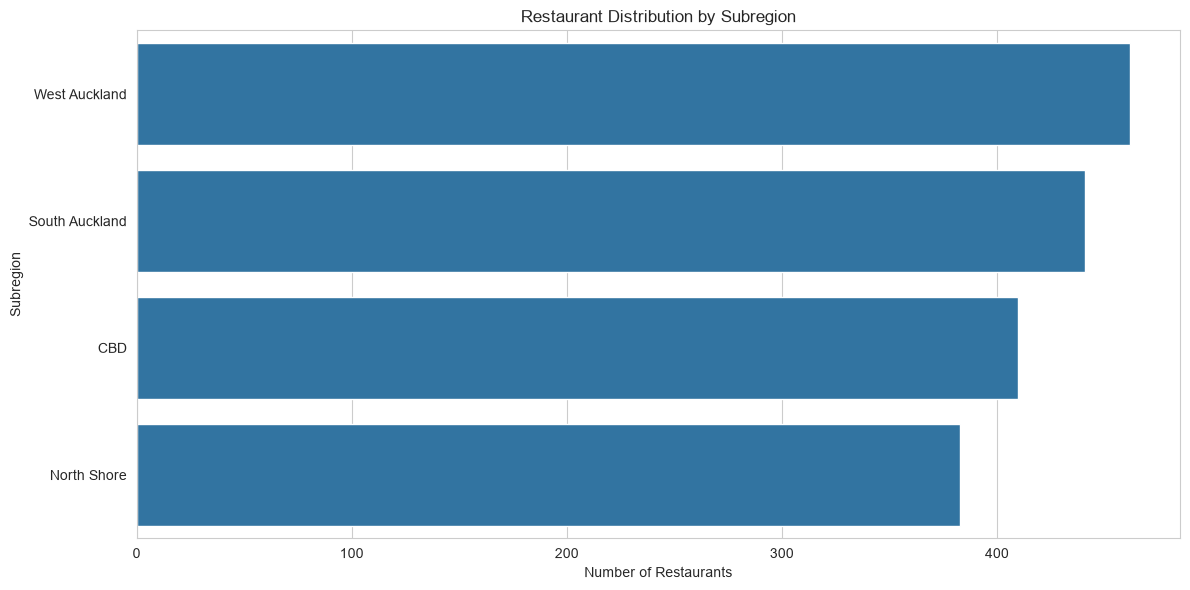

In [28]:
if 'Subregion' in df.columns:

    subregion_counts = df['Subregion'].value_counts()

    plt.figure(figsize=(12, 6))

    sns.barplot(
        x=subregion_counts.values,
        y=subregion_counts.index
    )

    plt.title('Restaurant Distribution by Subregion')
    plt.xlabel('Number of Restaurants')
    plt.ylabel('Subregion')
    plt.tight_layout()
    plt.show()

Segment,Cafe,Full-service,Ghost Kitchen,QSR
CuisineType,,,,
Burgers,116,99,46,114
Chicken Dishes,38,50,14,46
Chinese,75,54,26,63
Indian,89,83,44,113
Japanese,40,26,12,42
Kebabs/Mediterranean,50,47,16,54
Pizza,61,65,23,70
Thai,35,28,16,41


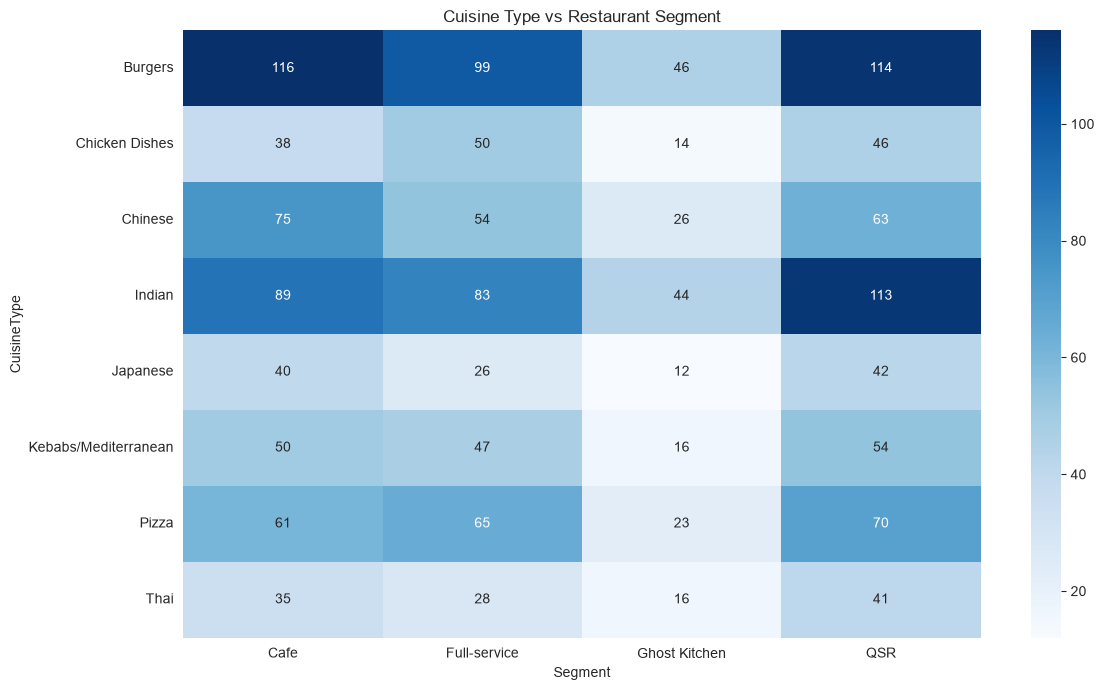

In [29]:
if 'CuisineType' in df.columns and 'Segment' in df.columns:

    cuisine_segment = pd.crosstab(
        df['CuisineType'],
        df['Segment']
    )

    display(cuisine_segment)

    plt.figure(figsize=(12, 7))

    sns.heatmap(
        cuisine_segment,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.title('Cuisine Type vs Restaurant Segment')
    plt.tight_layout()
    plt.show()

## 8. Numerical Data Analysis

This section examines numerical variables such as growth factor,
average order value, monthly orders, revenue, operating costs,
and delivery expenses.

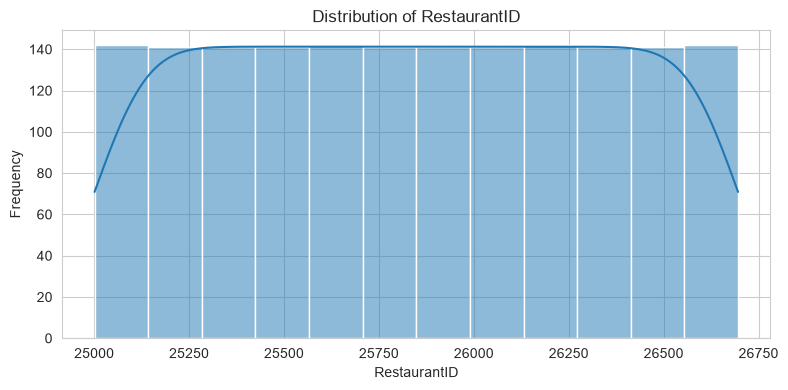

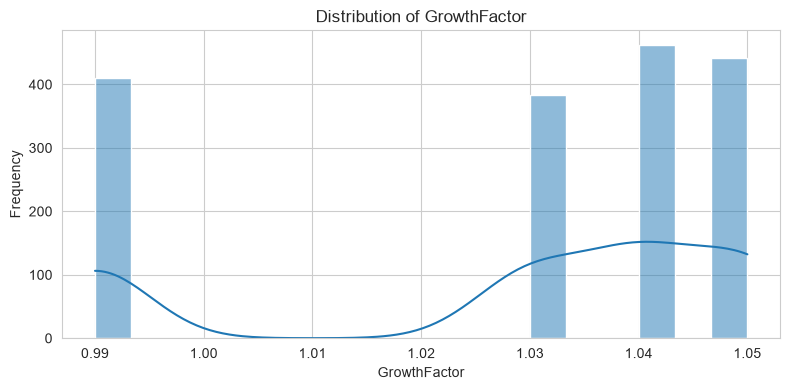

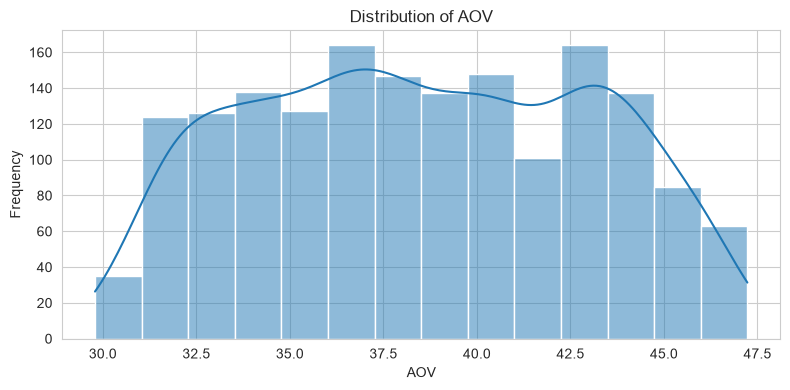

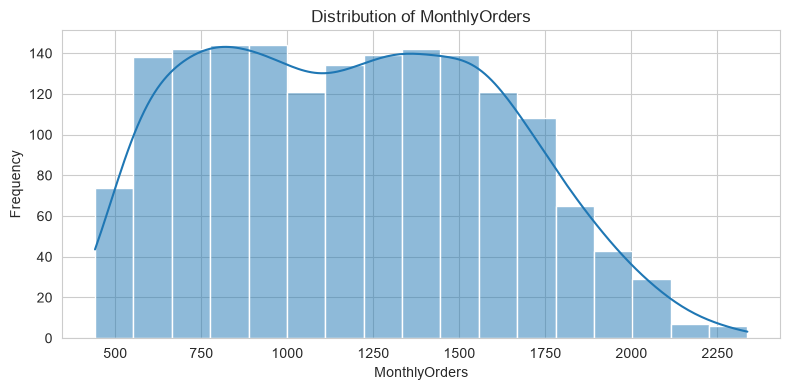

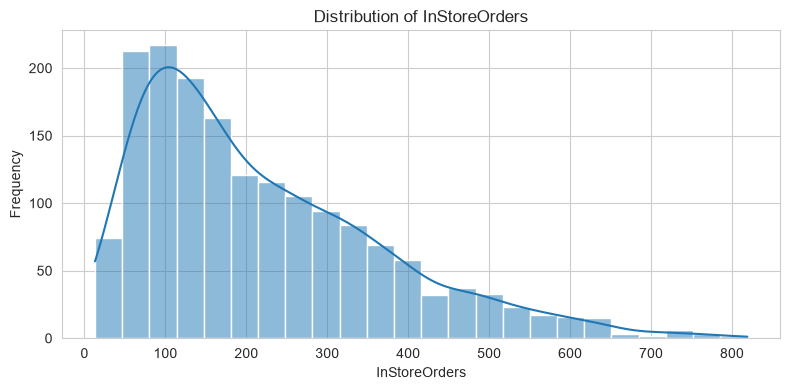

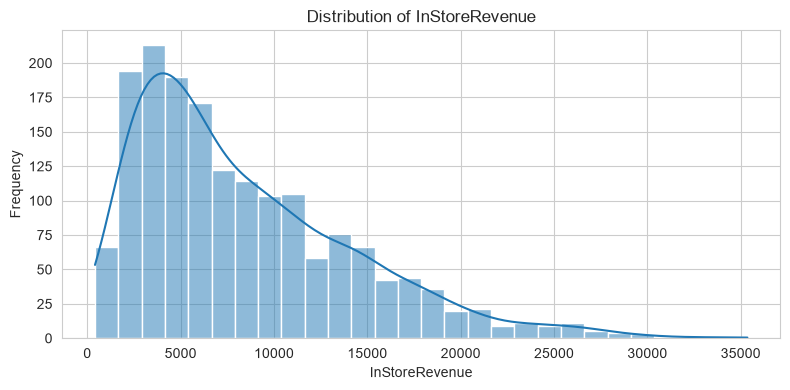

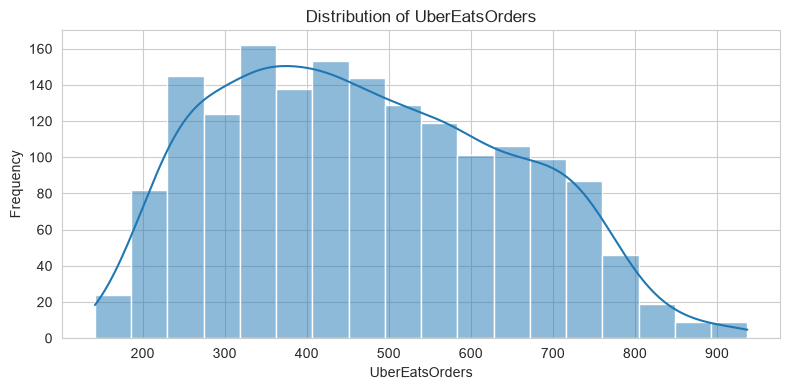

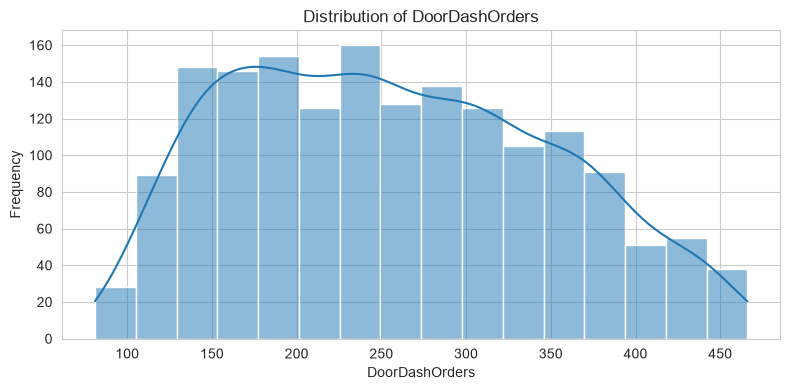

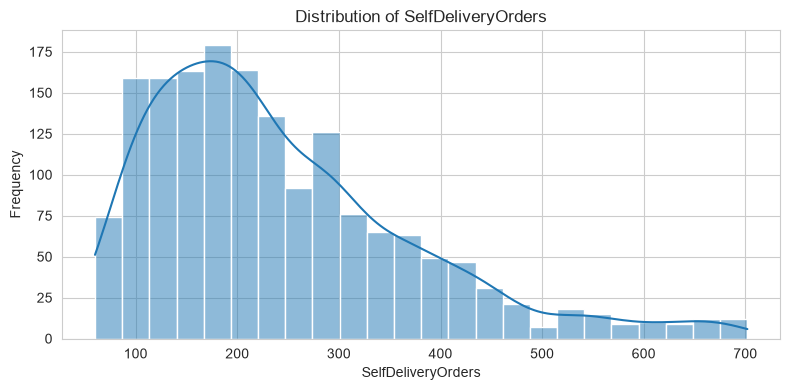

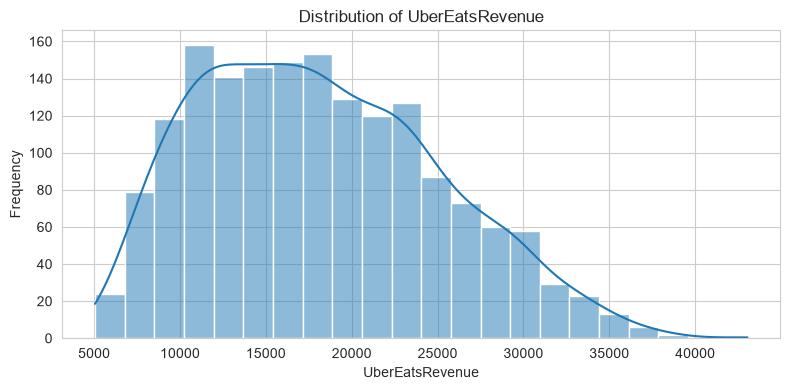

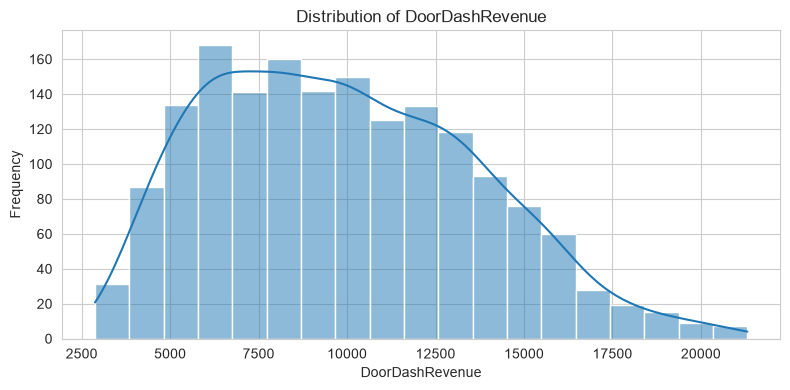

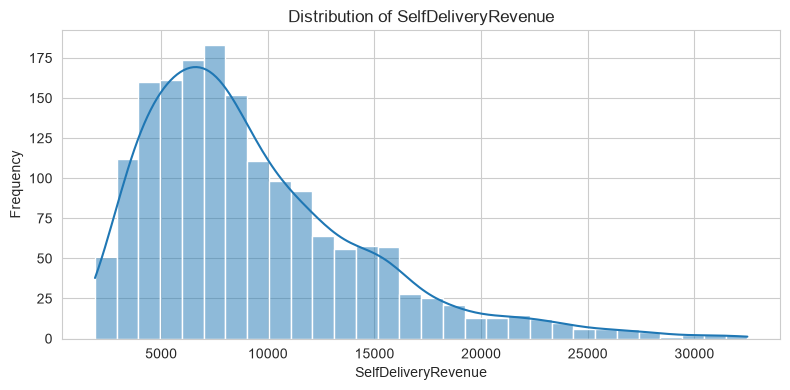

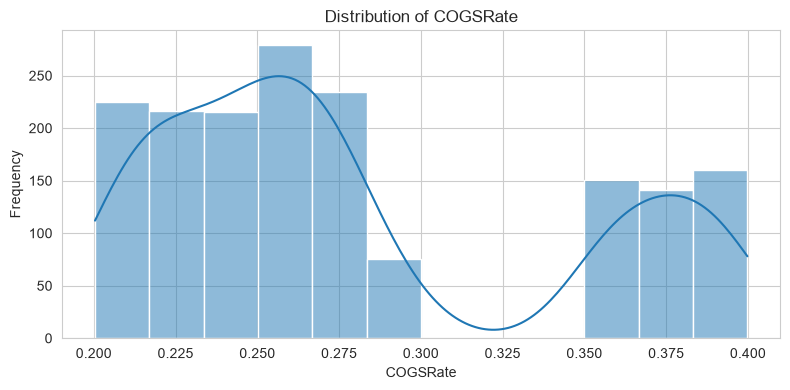

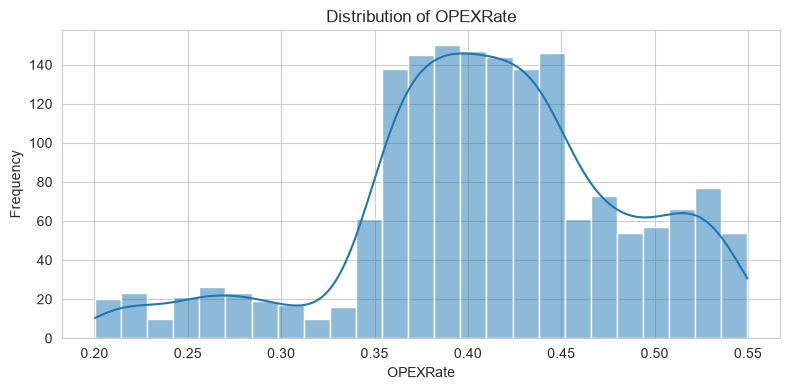

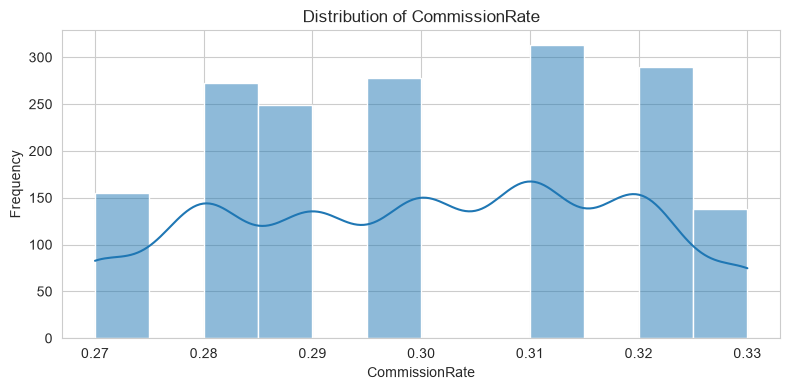

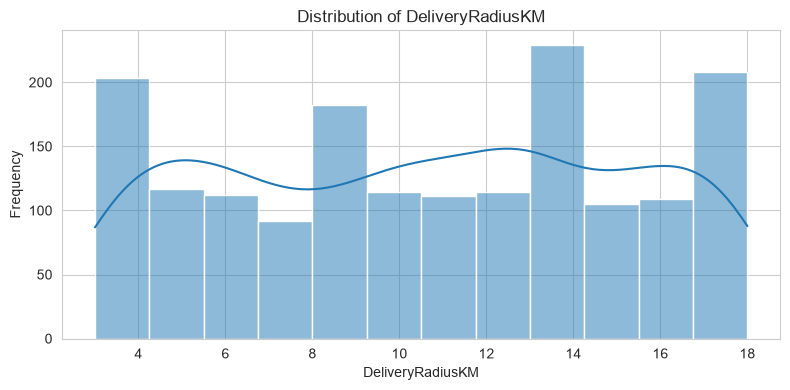

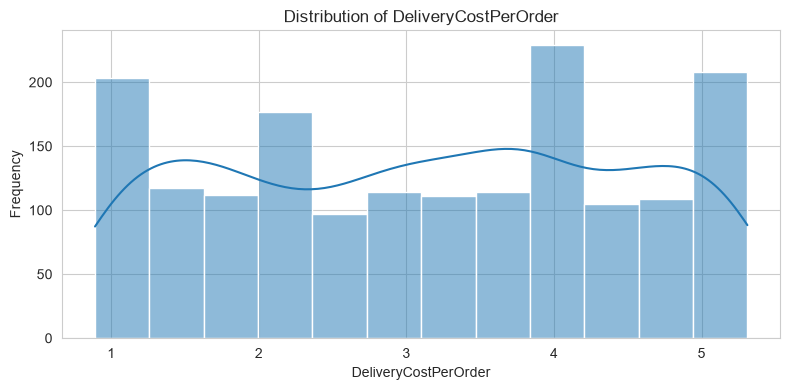

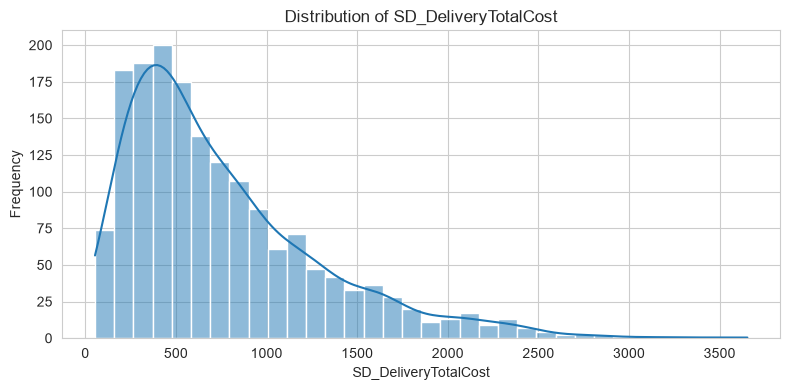

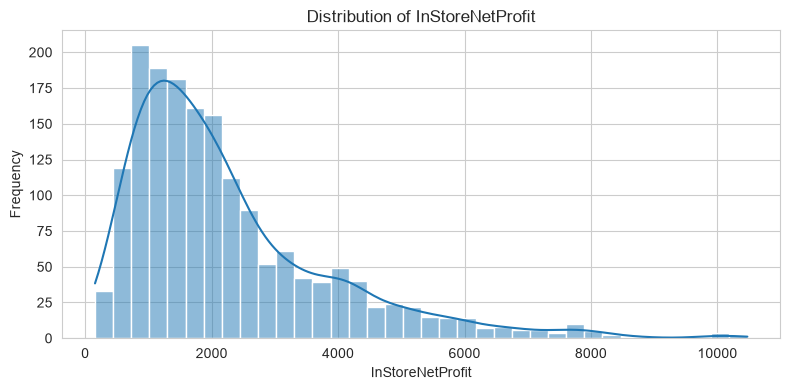

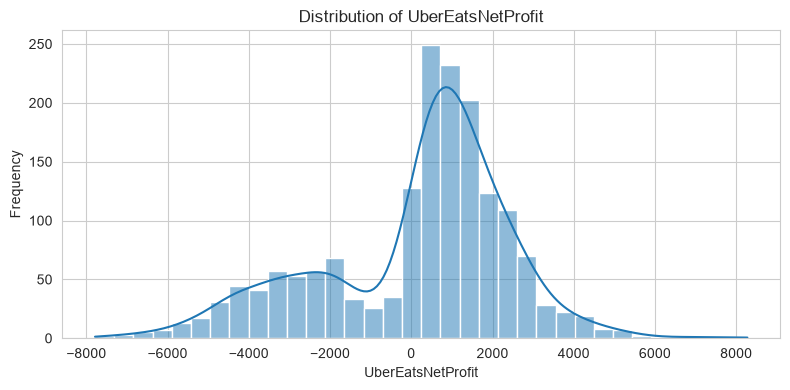

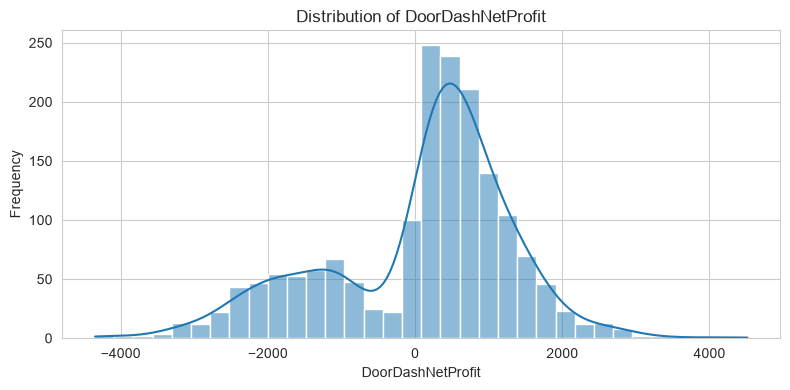

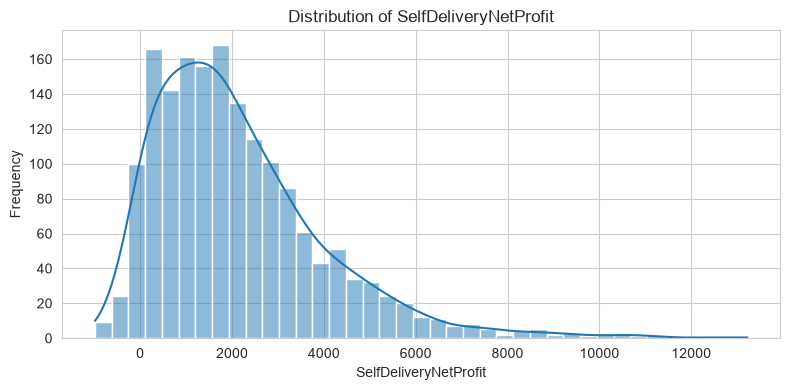

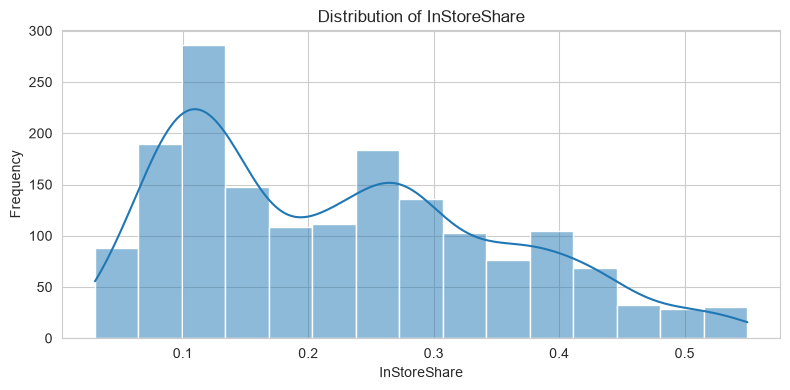

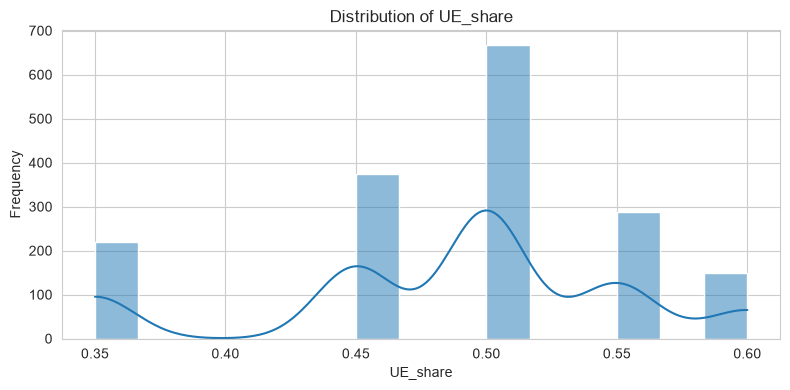

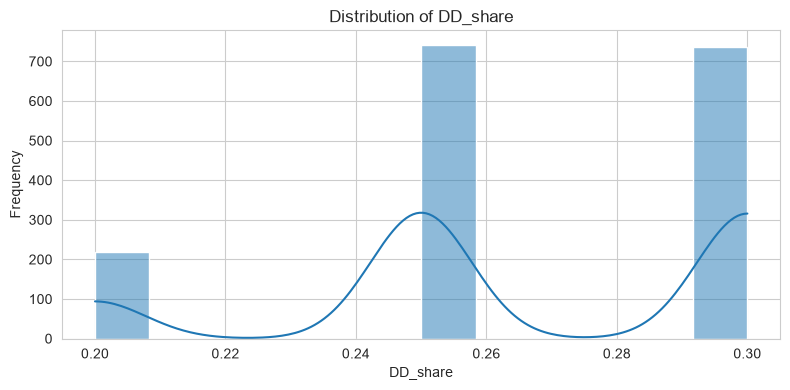

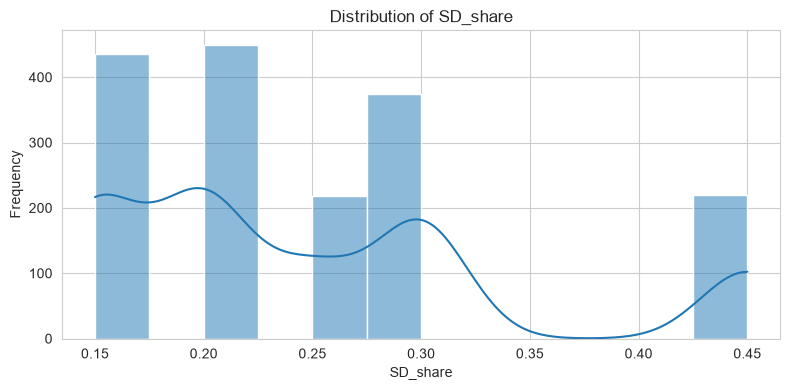

In [31]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

for col in numerical_columns:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        df[col],
        kde=True
    )

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

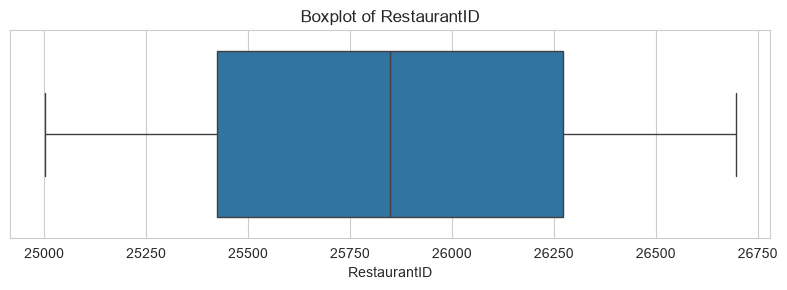

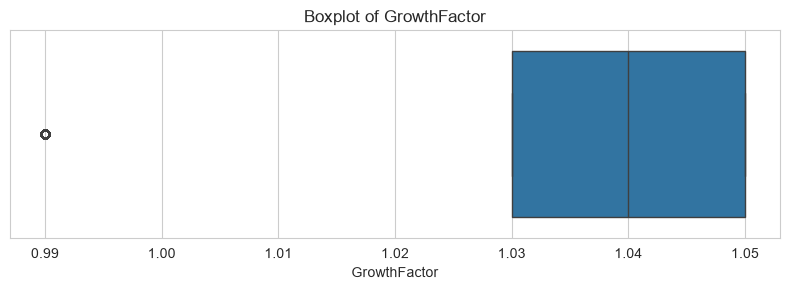

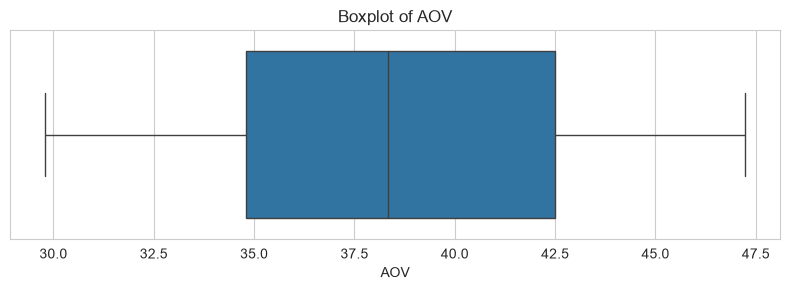

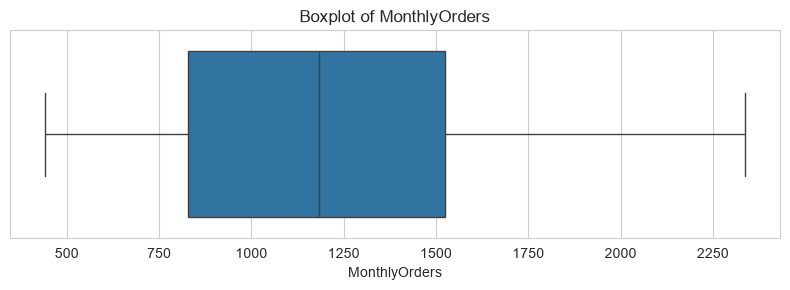

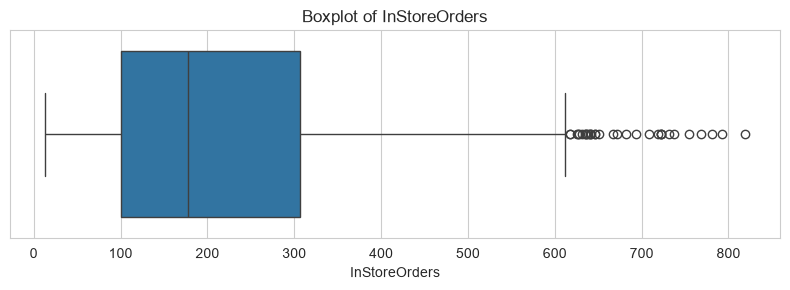

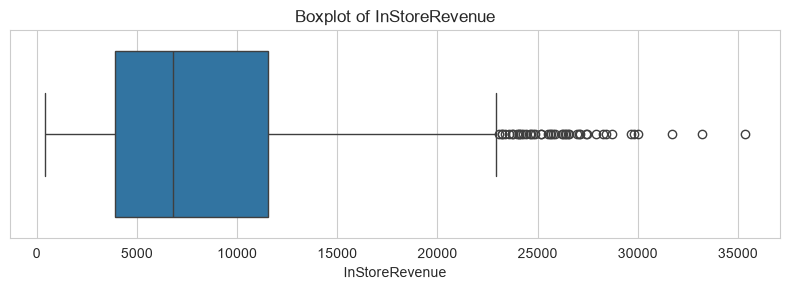

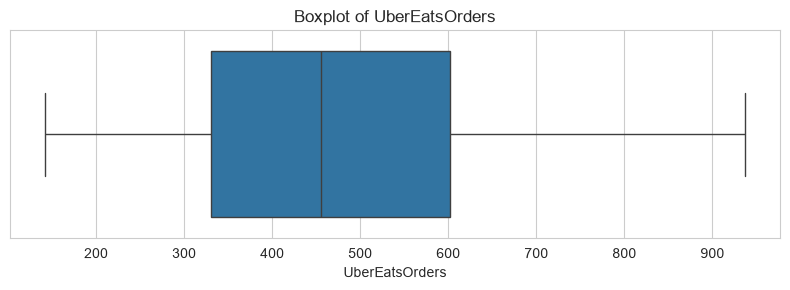

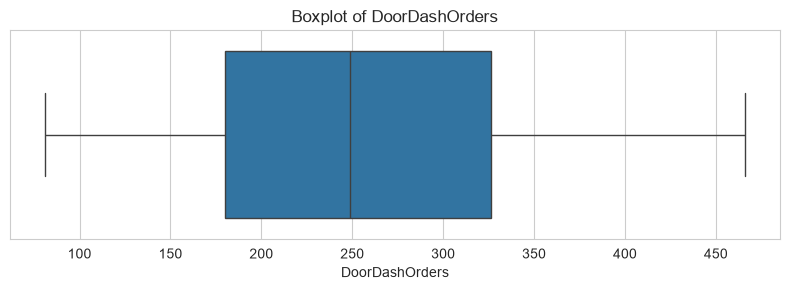

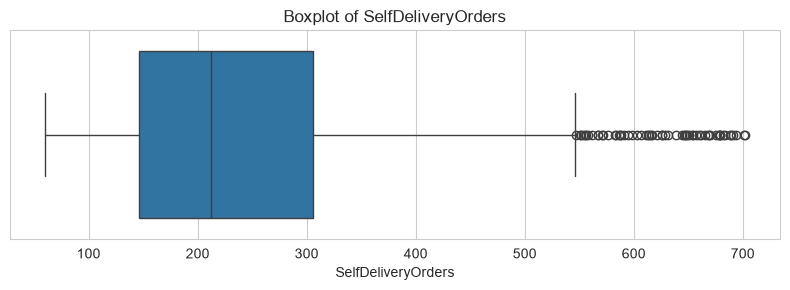

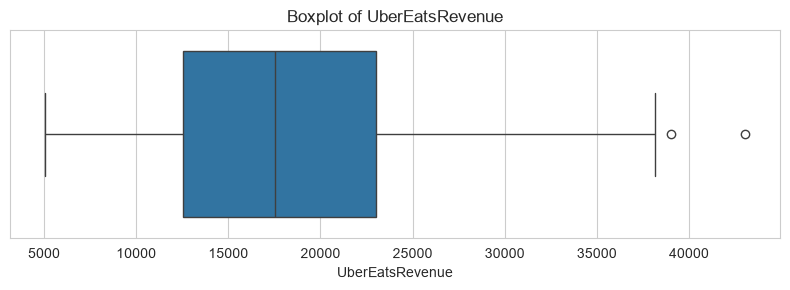

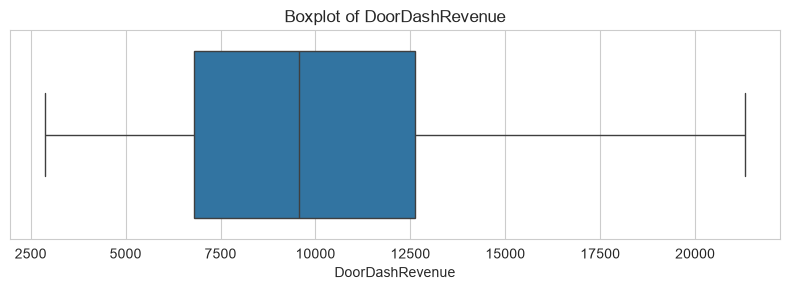

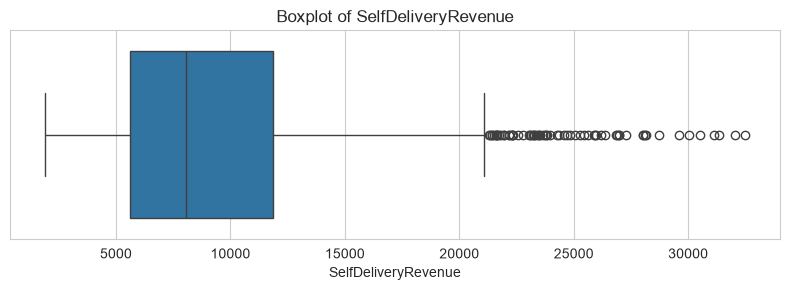

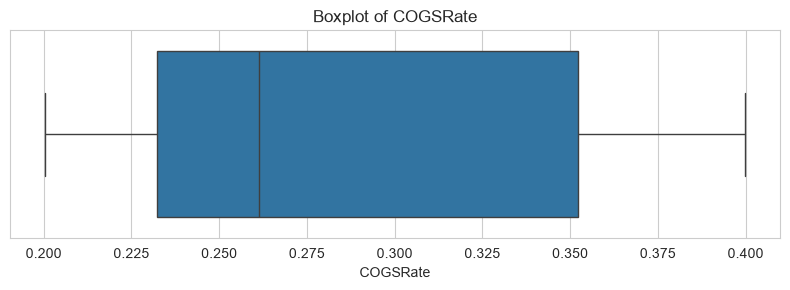

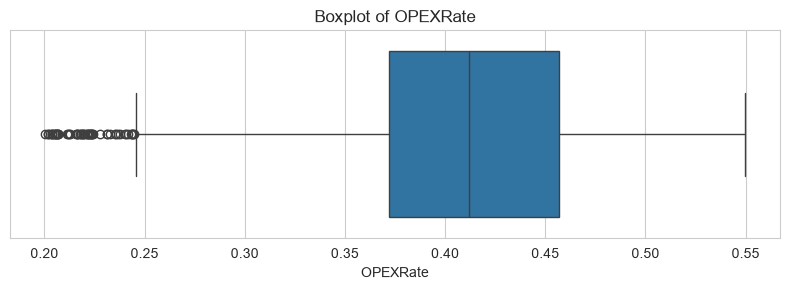

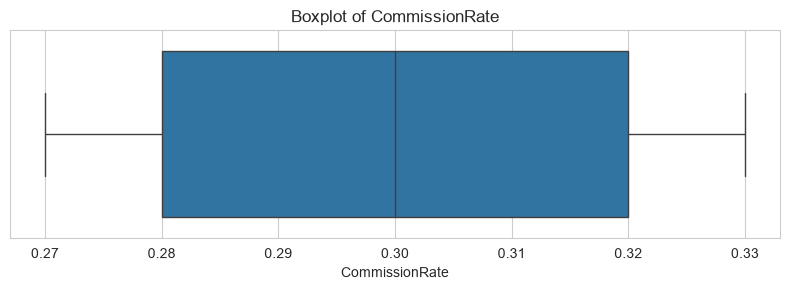

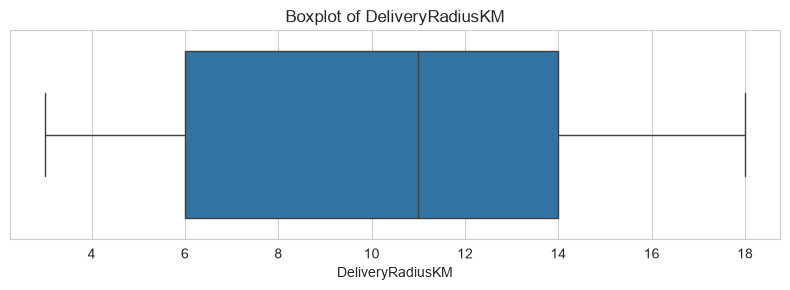

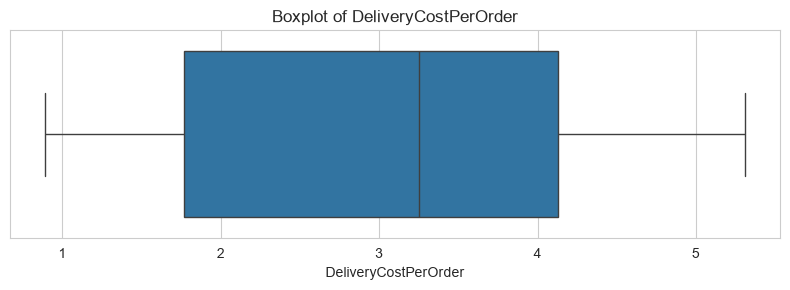

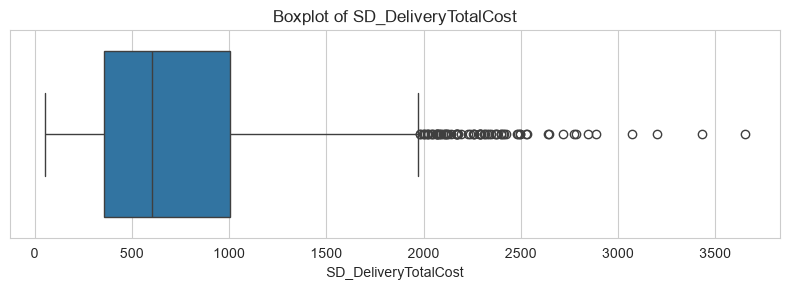

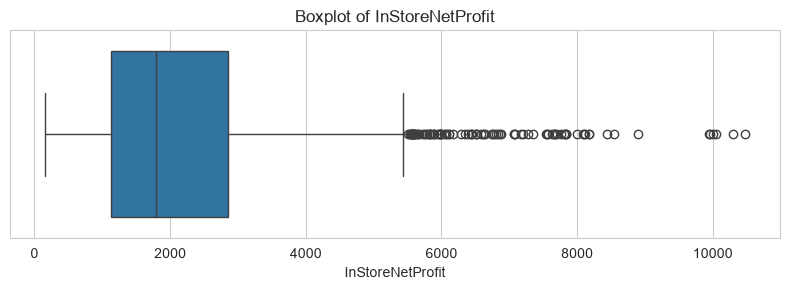

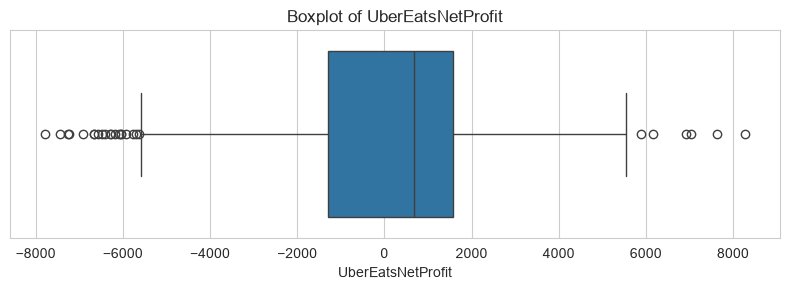

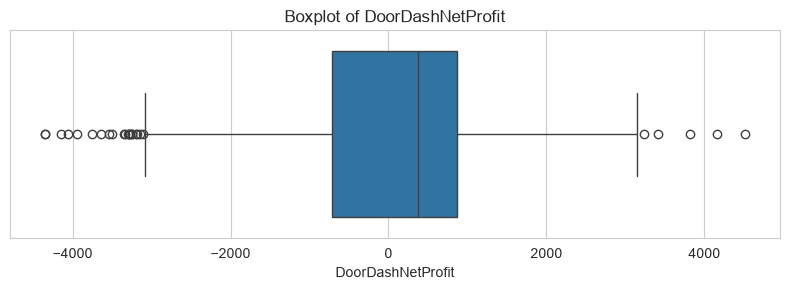

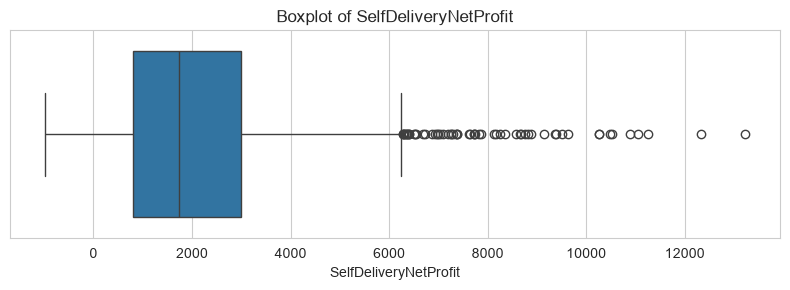

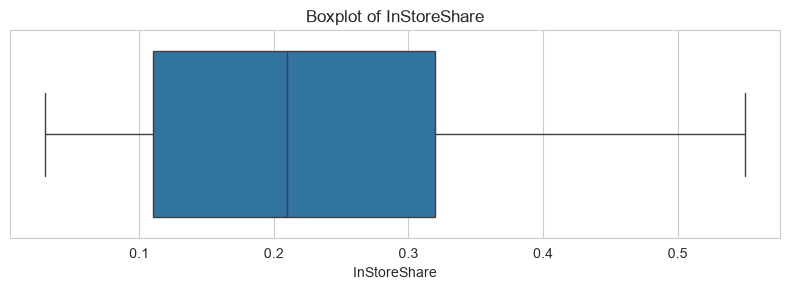

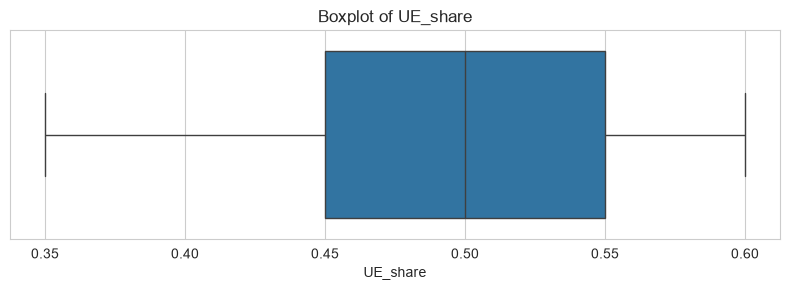

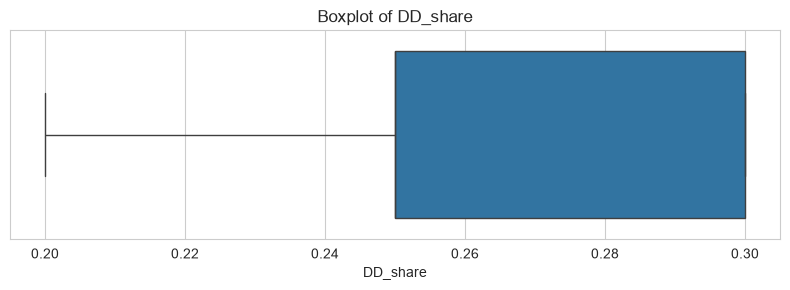

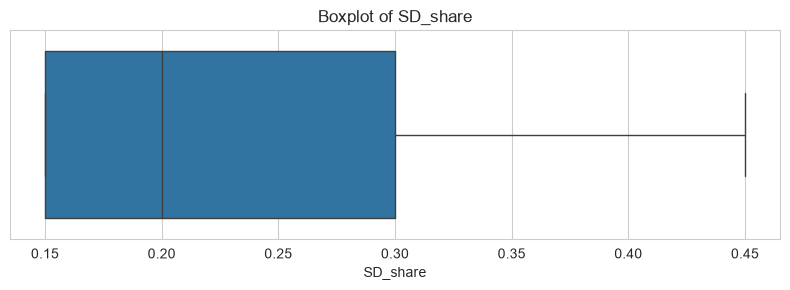

In [32]:
for col in numerical_columns:

    plt.figure(figsize=(8, 3))

    sns.boxplot(x=df[col])

    plt.title(f'Boxplot of {col}')
    plt.tight_layout()
    plt.show()

In [33]:
skewness = df[numerical_columns].skew().sort_values(
    ascending=False
)

display(
    skewness.to_frame(name='Skewness')
)

,Skewness
InStoreNetProfit,1.645656
SelfDeliveryNetProfit,1.492219
SD_DeliveryTotalCost,1.387257
SelfDeliveryRevenue,1.301389
SelfDeliveryOrders,1.161952
InStoreRevenue,1.136530
InStoreOrders,1.063820
SD_share,0.976599
COGSRate,0.698871
InStoreShare,0.519725


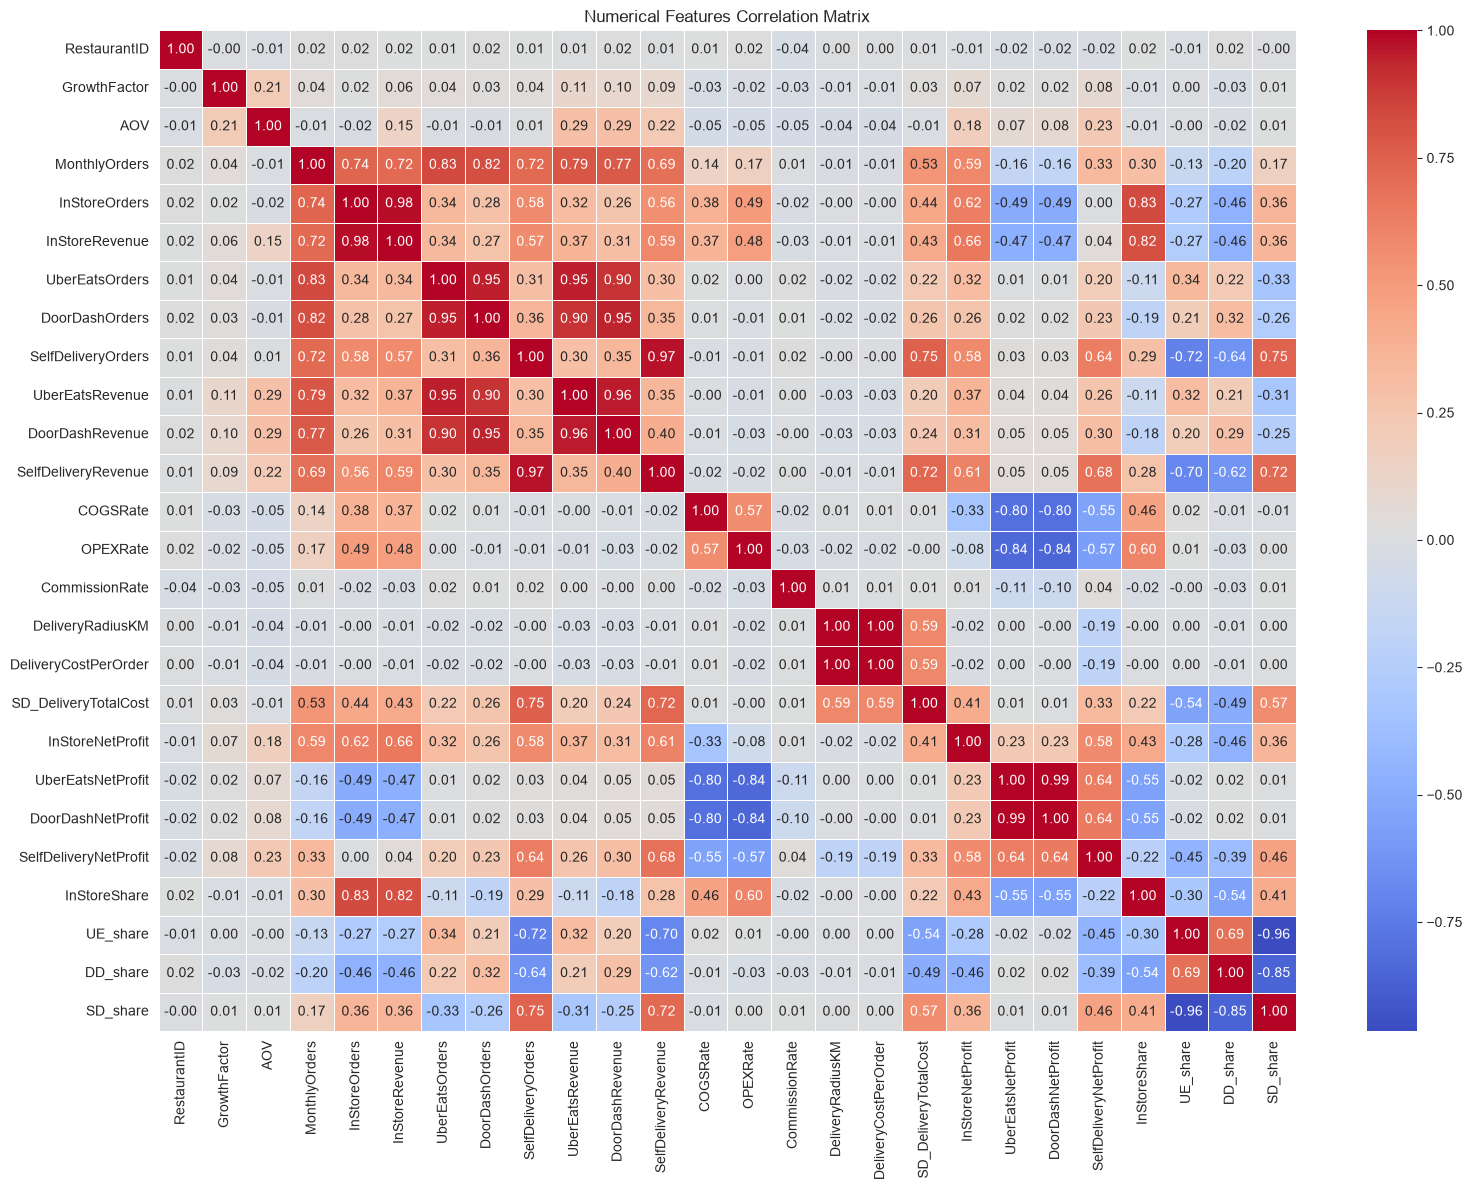

In [34]:
correlation_matrix = df[numerical_columns].corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    annot=True,
    fmt='.2f',
    linewidths=0.5
)

plt.title('Numerical Features Correlation Matrix')
plt.tight_layout()
plt.show()

## 9. Restaurant Growth and Demand Analysis

This section studies monthly orders and growth factors to understand
restaurant demand and potential business expansion.

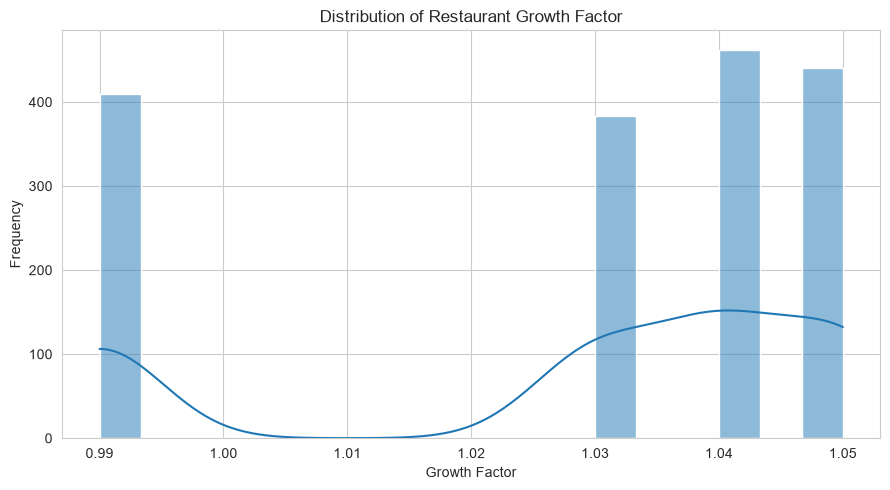

In [36]:
if 'GrowthFactor' in df.columns:

    plt.figure(figsize=(9, 5))

    sns.histplot(
        df['GrowthFactor'],
        kde=True
    )

    plt.title('Distribution of Restaurant Growth Factor')
    plt.xlabel('Growth Factor')
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

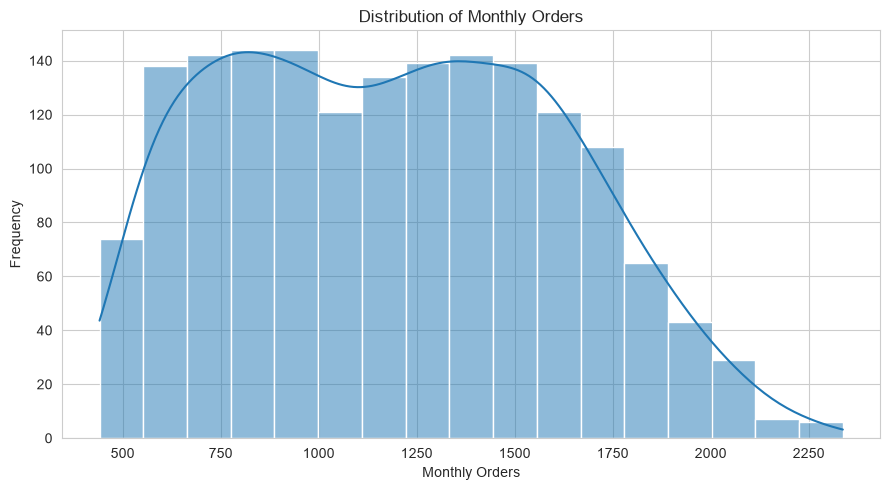

In [37]:
if 'MonthlyOrders' in df.columns:

    plt.figure(figsize=(9, 5))

    sns.histplot(
        df['MonthlyOrders'],
        kde=True
    )

    plt.title('Distribution of Monthly Orders')
    plt.xlabel('Monthly Orders')
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

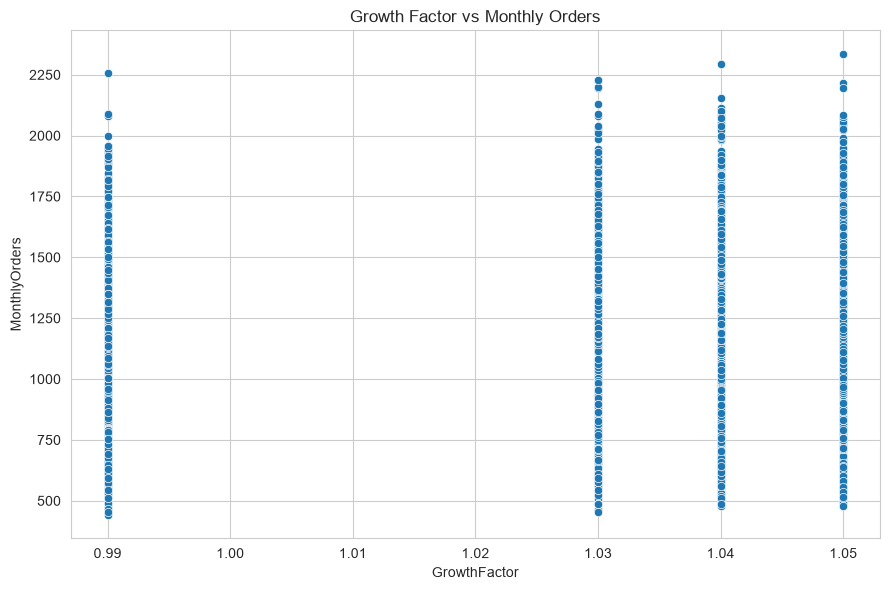

In [38]:
if {'GrowthFactor', 'MonthlyOrders'}.issubset(df.columns):

    plt.figure(figsize=(9, 6))

    sns.scatterplot(
        data=df,
        x='GrowthFactor',
        y='MonthlyOrders'
    )

    plt.title('Growth Factor vs Monthly Orders')
    plt.tight_layout()
    plt.show()

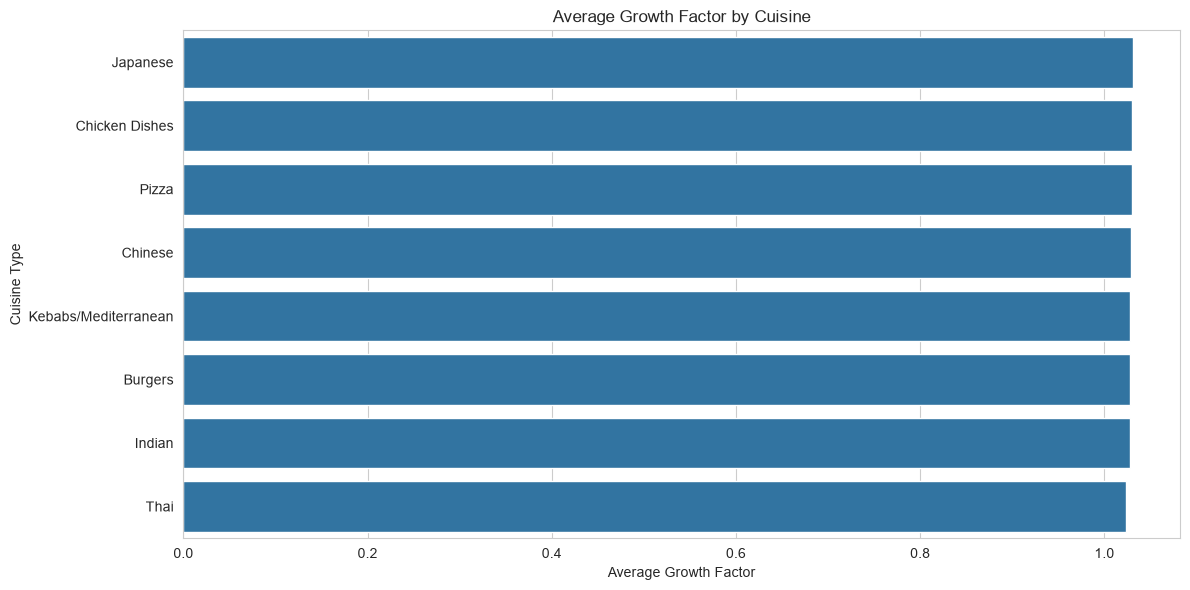

In [39]:
if {'CuisineType', 'GrowthFactor'}.issubset(df.columns):

    cuisine_growth = (
        df.groupby('CuisineType')['GrowthFactor']
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(12, 6))

    sns.barplot(
        x=cuisine_growth.values,
        y=cuisine_growth.index
    )

    plt.title('Average Growth Factor by Cuisine')
    plt.xlabel('Average Growth Factor')
    plt.ylabel('Cuisine Type')
    plt.tight_layout()
    plt.show()

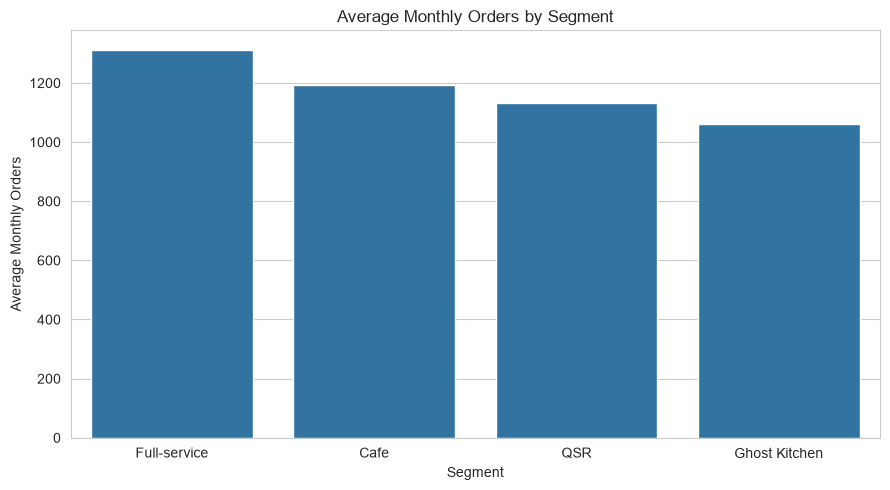

In [40]:
if {'Segment', 'MonthlyOrders'}.issubset(df.columns):

    segment_orders = (
        df.groupby('Segment')['MonthlyOrders']
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(9, 5))

    sns.barplot(
        x=segment_orders.index,
        y=segment_orders.values
    )

    plt.title('Average Monthly Orders by Segment')
    plt.xlabel('Segment')
    plt.ylabel('Average Monthly Orders')
    plt.tight_layout()
    plt.show()

## 10. Revenue and Sales Channel Analysis

This section evaluates revenue generated through in-store sales,
Uber Eats, DoorDash, and self-delivery.

The objective is to identify important revenue channels and
understand restaurant channel performance.

In [42]:
revenue_columns = [
    'InStoreRevenue',
    'UberEatsRevenue',
    'DoorDashRevenue',
    'SelfDeliveryRevenue'
]

available_revenue = [
    col for col in revenue_columns
    if col in df.columns
]

df['TotalRevenue'] = df[available_revenue].sum(axis=1)

print("Total Revenue:", df['TotalRevenue'].sum())

Total Revenue: 77739306.8


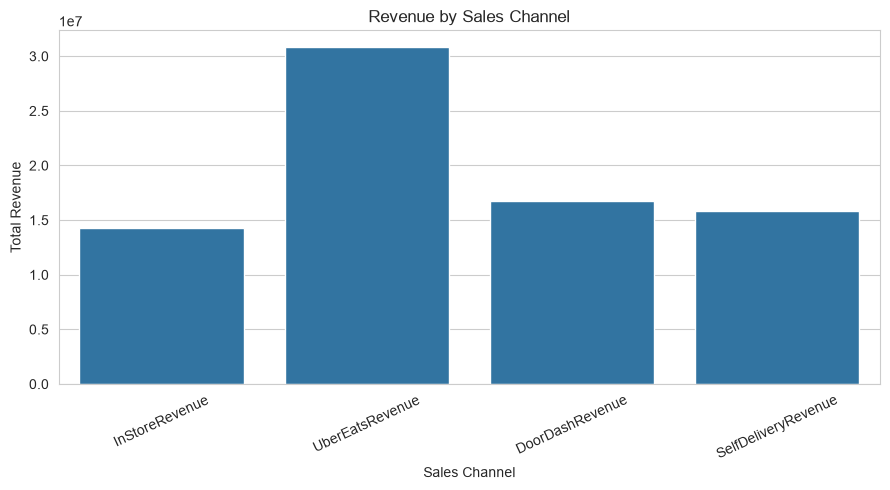

InStoreRevenue         14284378.07
UberEatsRevenue        30816371.49
DoorDashRevenue        16789380.95
SelfDeliveryRevenue    15849176.29
dtype: float64

In [43]:
channel_revenue = df[available_revenue].sum()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=channel_revenue.index,
    y=channel_revenue.values
)

plt.title('Revenue by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Total Revenue')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

display(channel_revenue)

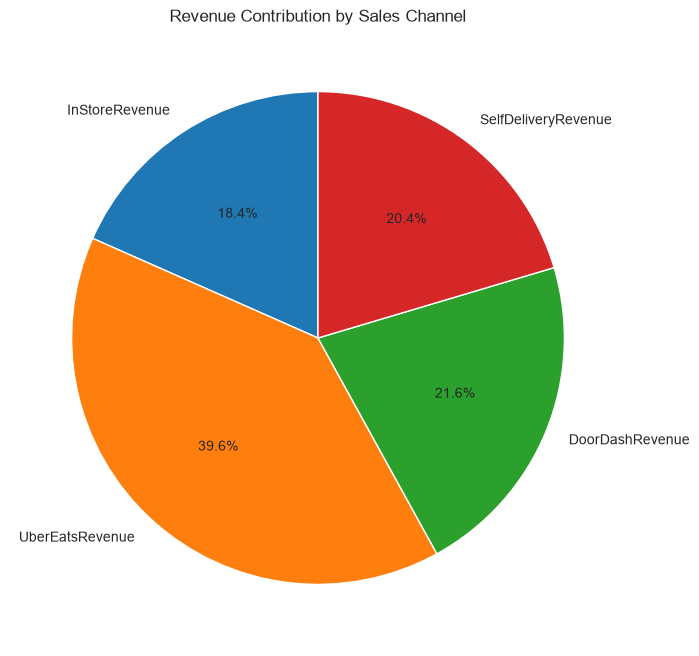

InStoreRevenue         18.374718
UberEatsRevenue        39.640656
DoorDashRevenue        21.597029
SelfDeliveryRevenue    20.387597
dtype: float64

In [44]:
channel_percentage = (
    channel_revenue / channel_revenue.sum()
) * 100

plt.figure(figsize=(8, 8))

plt.pie(
    channel_percentage.values,
    labels=channel_percentage.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Revenue Contribution by Sales Channel')
plt.show()

display(channel_percentage)

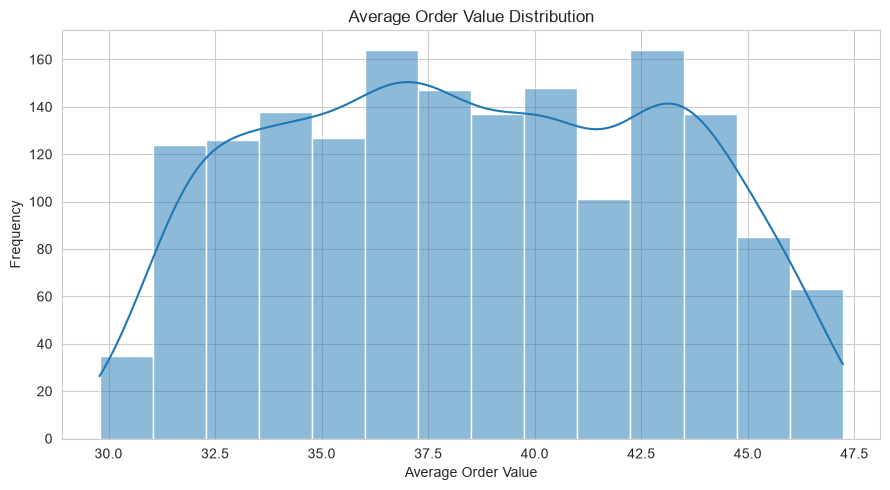

In [45]:
if 'AOV' in df.columns:

    plt.figure(figsize=(9, 5))

    sns.histplot(
        df['AOV'],
        kde=True
    )

    plt.title('Average Order Value Distribution')
    plt.xlabel('Average Order Value')
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

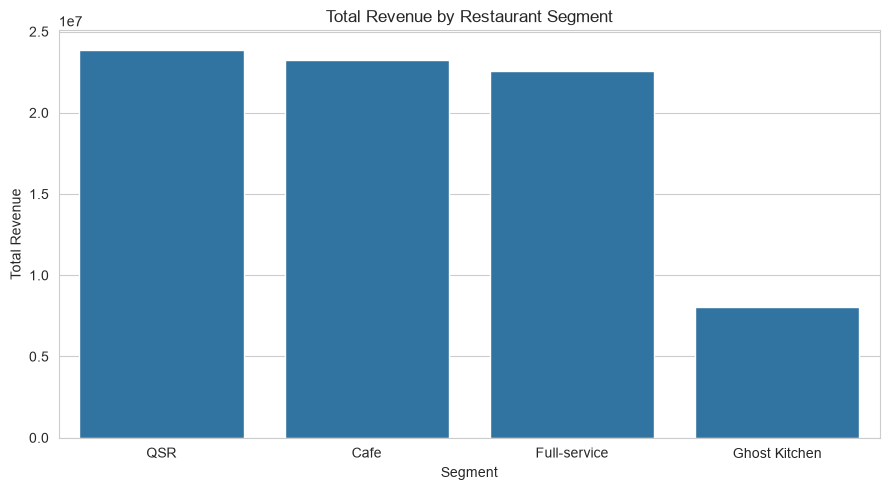

In [46]:
if 'Segment' in df.columns:

    segment_revenue = (
        df.groupby('Segment')['TotalRevenue']
        .sum()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(9, 5))

    sns.barplot(
        x=segment_revenue.index,
        y=segment_revenue.values
    )

    plt.title('Total Revenue by Restaurant Segment')
    plt.xlabel('Segment')
    plt.ylabel('Total Revenue')
    plt.tight_layout()
    plt.show()

## 11. Cost and Profitability Analysis

This section evaluates the cost structure and profitability of restaurants.

It considers cost of goods sold, operating expenses, commission rates,
and net profit generated by different sales channels.

In [48]:
profit_columns = [
    'InStoreNetProfit',
    'UberEatsNetProfit',
    'DoorDashNetProfit',
    'SelfDeliveryNetProfit'
]

available_profit = [
    col for col in profit_columns
    if col in df.columns
]

df['TotalNetProfit'] = df[available_profit].sum(axis=1)

print("Total Net Profit:", df['TotalNetProfit'].sum())

Total Net Profit: 7866306.130000001


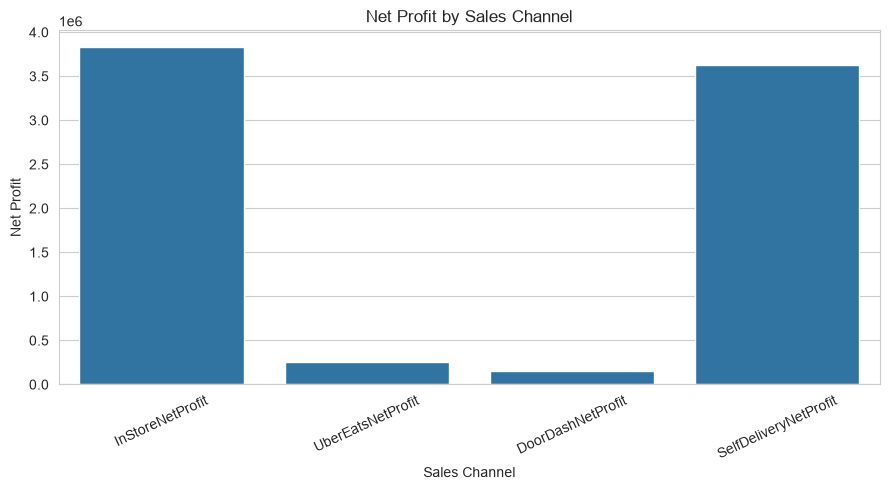

InStoreNetProfit         3828417.36
UberEatsNetProfit         258488.08
DoorDashNetProfit         151122.25
SelfDeliveryNetProfit    3628278.44
dtype: float64

In [49]:
channel_profit = df[available_profit].sum()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=channel_profit.index,
    y=channel_profit.values
)

plt.title('Net Profit by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Net Profit')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

display(channel_profit)

,count,mean,std,min,25%,50%,75%,max
COGSRate,1696.0,0.280149,0.061760,0.200369,0.232270,0.261271,0.352189,0.399826
OPEXRate,1696.0,0.411650,0.073420,0.200301,0.372182,0.411785,0.456814,0.549688
CommissionRate,1696.0,0.300277,0.017931,0.270000,0.280000,0.300000,0.320000,0.330000


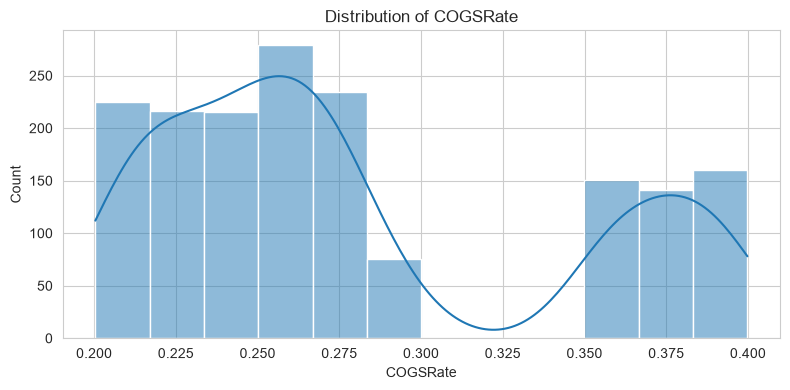

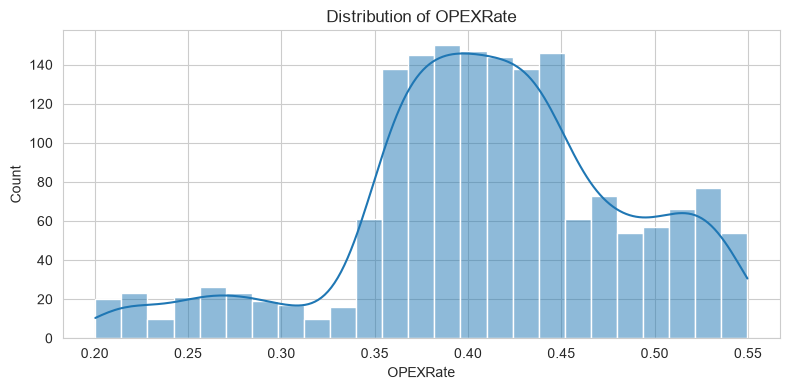

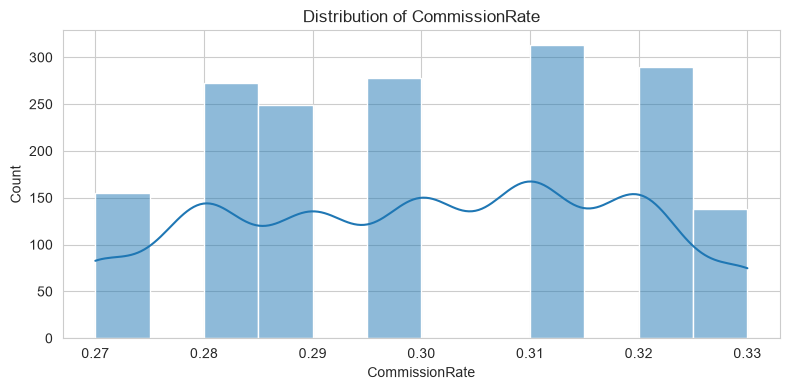

In [50]:
cost_columns = [
    'COGSRate',
    'OPEXRate',
    'CommissionRate'
]

available_costs = [
    col for col in cost_columns
    if col in df.columns
]

display(df[available_costs].describe().T)

for col in available_costs:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        df[col],
        kde=True
    )

    plt.title(f'Distribution of {col}')
    plt.tight_layout()
    plt.show()

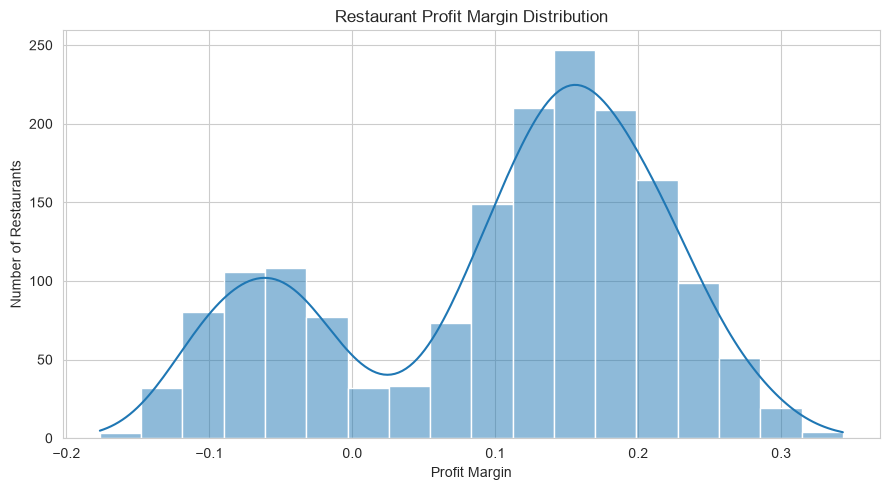

In [51]:
df['ProfitMargin'] = np.where(
    df['TotalRevenue'] > 0,
    df['TotalNetProfit'] / df['TotalRevenue'],
    np.nan
)

plt.figure(figsize=(9, 5))

sns.histplot(
    df['ProfitMargin'].dropna(),
    kde=True
)

plt.title('Restaurant Profit Margin Distribution')
plt.xlabel('Profit Margin')
plt.ylabel('Number of Restaurants')
plt.tight_layout()
plt.show()

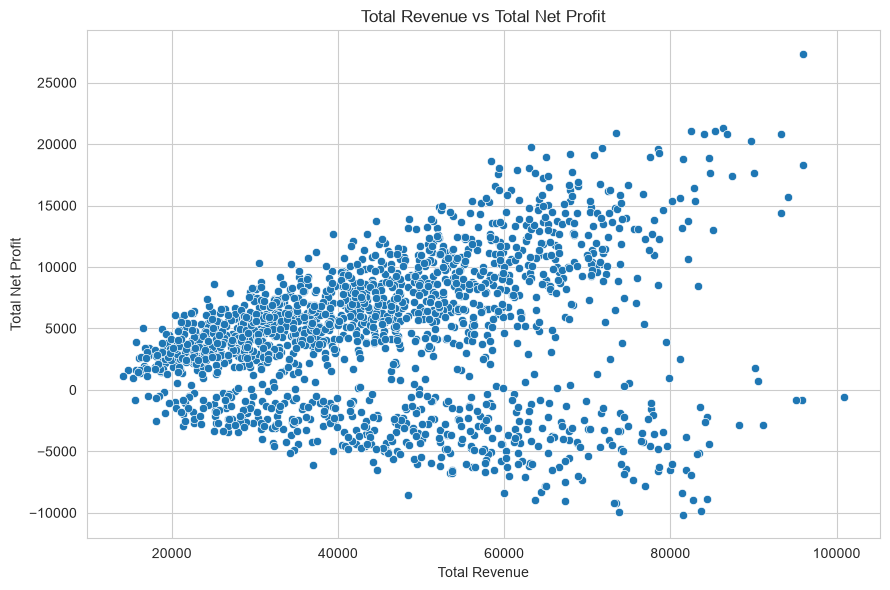

In [52]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='TotalRevenue',
    y='TotalNetProfit'
)

plt.title('Total Revenue vs Total Net Profit')
plt.xlabel('Total Revenue')
plt.ylabel('Total Net Profit')
plt.tight_layout()
plt.show()

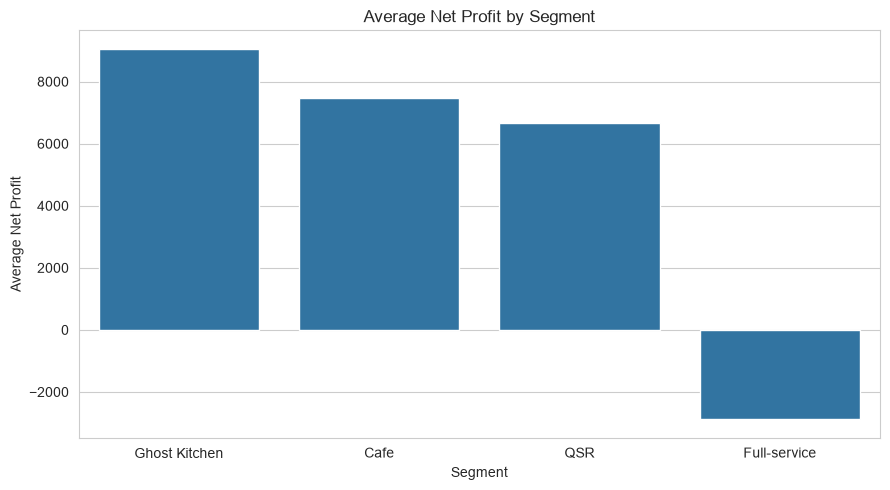

In [53]:
if 'Segment' in df.columns:

    segment_profit = (
        df.groupby('Segment')['TotalNetProfit']
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(9, 5))

    sns.barplot(
        x=segment_profit.index,
        y=segment_profit.values
    )

    plt.title('Average Net Profit by Segment')
    plt.xlabel('Segment')
    plt.ylabel('Average Net Profit')
    plt.tight_layout()
    plt.show()

## 12. Delivery Channel and Logistics Analysis

This section evaluates delivery channel usage, aggregator dependence,
self-delivery costs, and delivery radius.

The analysis helps identify opportunities and possible risks
associated with restaurant delivery operations.

In [55]:
order_columns = [
    'InStoreOrders',
    'UberEatsOrders',
    'DoorDashOrders',
    'SelfDeliveryOrders'
]

available_orders = [
    col for col in order_columns
    if col in df.columns
]

display(df[available_orders].describe().T)

,count,mean,std,min,25%,50%,75%,max
InStoreOrders,1696.0,218.980542,149.758619,13.0,101.00,178.0,307.00,819.0
UberEatsOrders,1696.0,471.906250,171.781981,142.0,331.00,456.0,602.00,937.0
DoorDashOrders,1696.0,257.155071,92.605301,81.0,179.75,249.0,326.25,466.0
SelfDeliveryOrders,1696.0,242.485259,129.950736,60.0,146.00,212.0,306.25,702.0


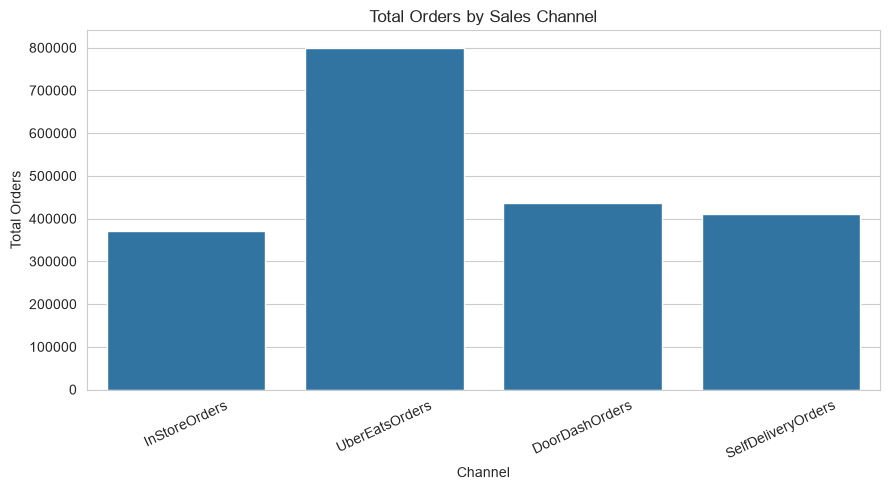

In [56]:
channel_orders = df[available_orders].sum()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=channel_orders.index,
    y=channel_orders.values
)

plt.title('Total Orders by Sales Channel')
plt.xlabel('Channel')
plt.ylabel('Total Orders')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

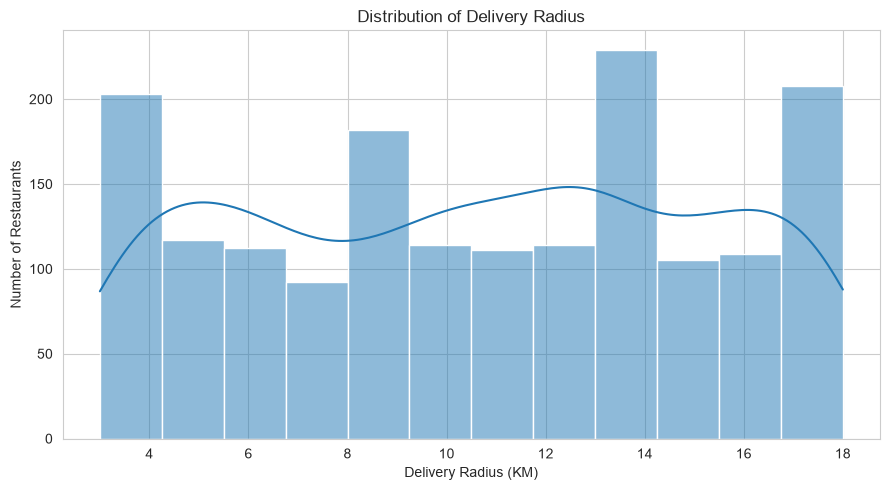

In [57]:
if 'DeliveryRadiusKM' in df.columns:

    plt.figure(figsize=(9, 5))

    sns.histplot(
        df['DeliveryRadiusKM'],
        kde=True
    )

    plt.title('Distribution of Delivery Radius')
    plt.xlabel('Delivery Radius (KM)')
    plt.ylabel('Number of Restaurants')
    plt.tight_layout()
    plt.show()

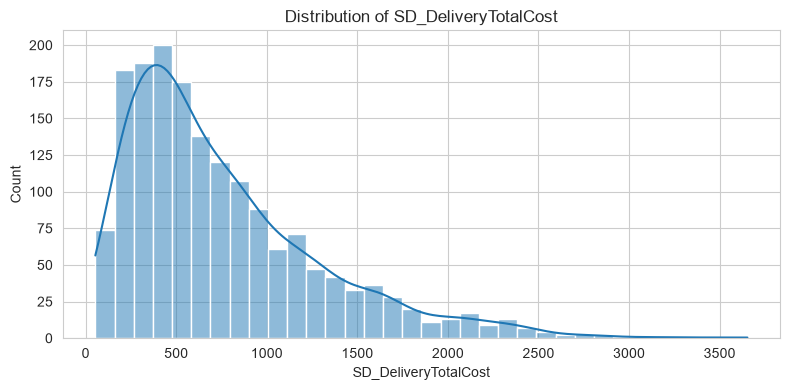

In [58]:
delivery_cost_columns = [
    'DeliveryCostOrder',
    'SD_DeliveryTotalCost'
]

available_delivery_costs = [
    col for col in delivery_cost_columns
    if col in df.columns
]

for col in available_delivery_costs:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        df[col],
        kde=True
    )

    plt.title(f'Distribution of {col}')
    plt.tight_layout()
    plt.show()

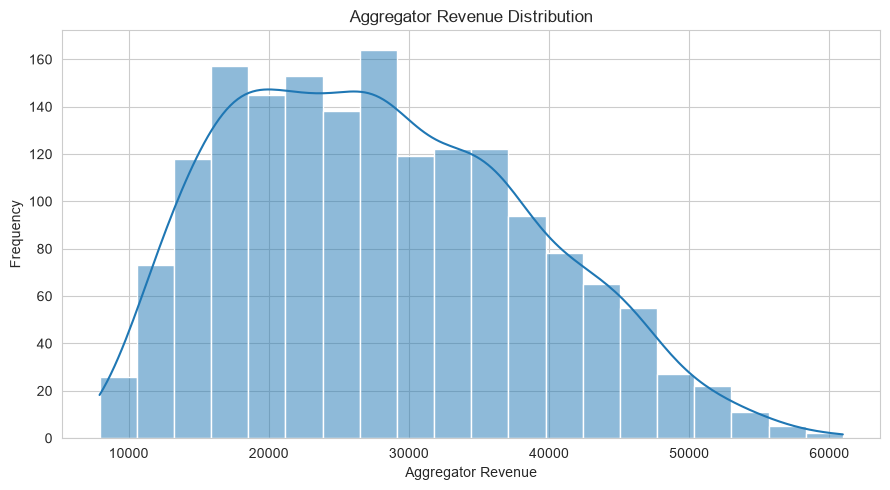

In [59]:
aggregator_revenue_columns = [
    'UberEatsRevenue',
    'DoorDashRevenue'
]

available_aggregator_revenue = [
    col for col in aggregator_revenue_columns
    if col in df.columns
]

df['AggregatorRevenue'] = df[
    available_aggregator_revenue
].sum(axis=1)

plt.figure(figsize=(9, 5))

sns.histplot(
    df['AggregatorRevenue'],
    kde=True
)

plt.title('Aggregator Revenue Distribution')
plt.xlabel('Aggregator Revenue')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

## 13. Correlation and Relationship Analysis

This section studies relationships between important business variables.

Correlation analysis helps identify variables that move together
and provides insights into potential drivers of restaurant performance.

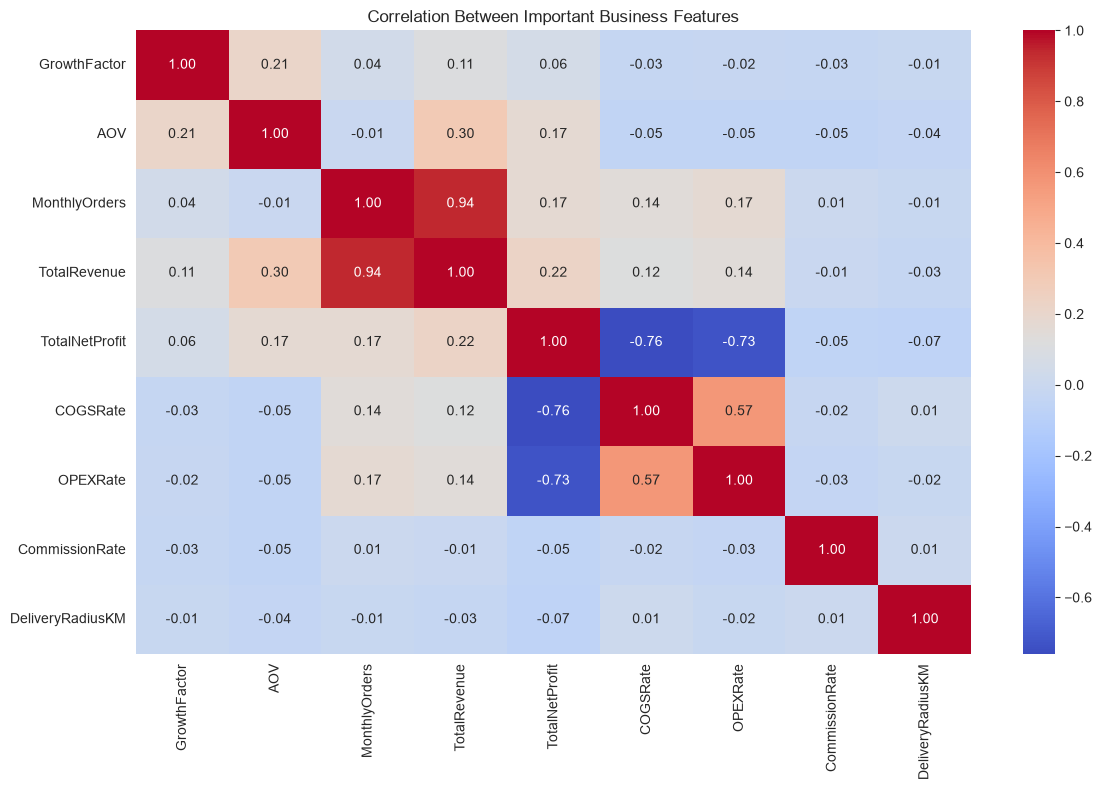

In [61]:
selected_features = [
    'GrowthFactor',
    'AOV',
    'MonthlyOrders',
    'TotalRevenue',
    'TotalNetProfit',
    'COGSRate',
    'OPEXRate',
    'CommissionRate',
    'DeliveryRadiusKM'
]

available_features = [
    col for col in selected_features
    if col in df.columns
]

correlation = df[available_features].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Important Business Features')
plt.tight_layout()
plt.show()

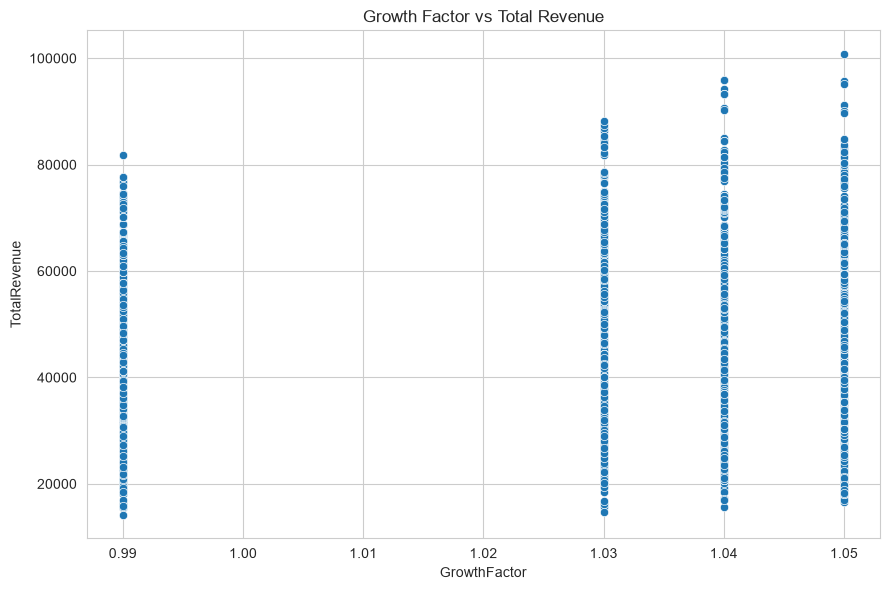

In [62]:
if 'GrowthFactor' in df.columns:

    plt.figure(figsize=(9, 6))

    sns.scatterplot(
        data=df,
        x='GrowthFactor',
        y='TotalRevenue'
    )

    plt.title('Growth Factor vs Total Revenue')
    plt.tight_layout()
    plt.show()

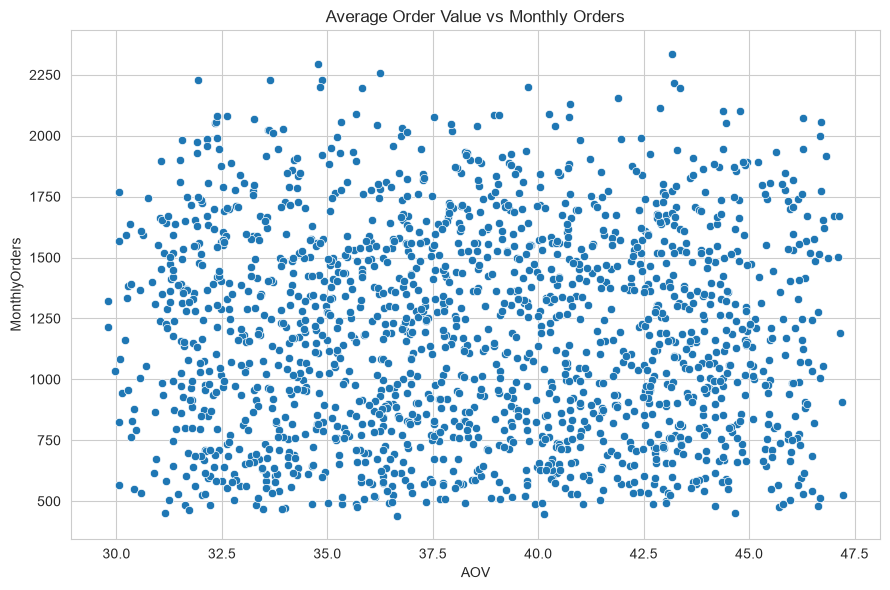

In [63]:
if {'AOV', 'MonthlyOrders'}.issubset(df.columns):

    plt.figure(figsize=(9, 6))

    sns.scatterplot(
        data=df,
        x='AOV',
        y='MonthlyOrders'
    )

    plt.title('Average Order Value vs Monthly Orders')
    plt.tight_layout()
    plt.show()

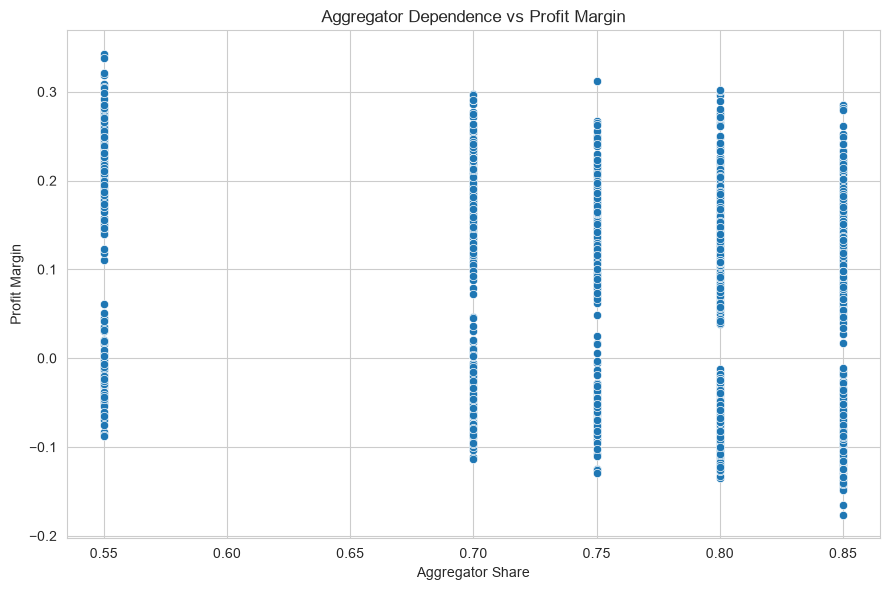

In [64]:
if {'UE_share', 'DD_share'}.issubset(df.columns):

    aggregator_share = (
        df['UE_share'] + df['DD_share']
    )

    plt.figure(figsize=(9, 6))

    sns.scatterplot(
        x=aggregator_share,
        y=df['ProfitMargin']
    )

    plt.title('Aggregator Dependence vs Profit Margin')
    plt.xlabel('Aggregator Share')
    plt.ylabel('Profit Margin')
    plt.tight_layout()
    plt.show()

## 14. Restaurant Performance Rankings

This section identifies restaurants with the highest revenue,
highest net profit, lowest net profit, and highest growth factor.

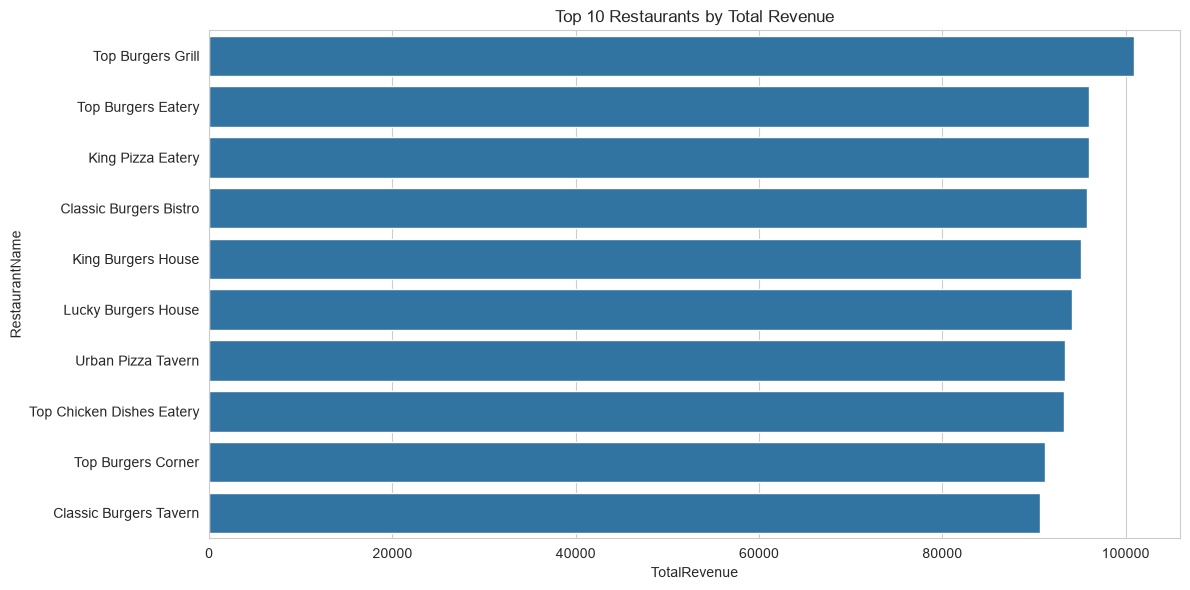

,RestaurantName,TotalRevenue
188,Top Burgers Grill,100888.29
131,Top Burgers Eatery,95968.50
1551,King Pizza Eatery,95963.98
168,Classic Burgers Bistro,95796.57
258,King Burgers House,95131.84
306,Lucky Burgers House,94193.37
1380,Urban Pizza Tavern,93352.17
497,Top Chicken Dishes Eatery,93266.64
34,Top Burgers Corner,91187.46
150,Classic Burgers Tavern,90605.44


In [66]:
top_revenue = df.nlargest(10, 'TotalRevenue')

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_revenue,
    x='TotalRevenue',
    y='RestaurantName'
)

plt.title('Top 10 Restaurants by Total Revenue')
plt.tight_layout()
plt.show()

display(
    top_revenue[
        ['RestaurantName', 'TotalRevenue']
    ]
)

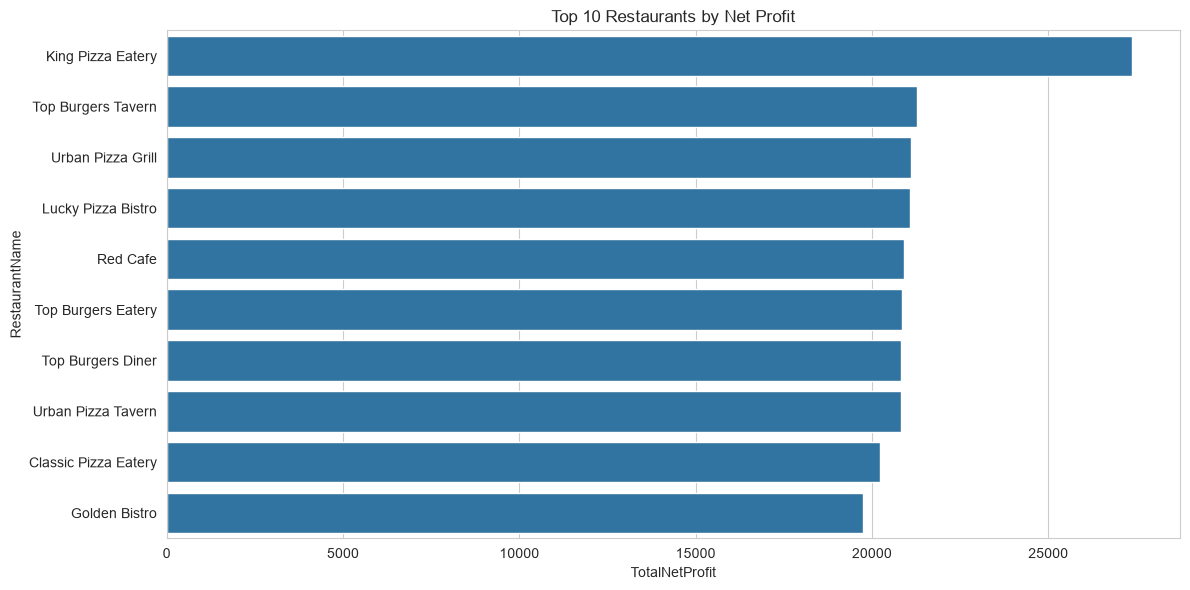

,RestaurantName,TotalNetProfit
1551,King Pizza Eatery,27368.36
113,Top Burgers Tavern,21269.54
1538,Urban Pizza Grill,21101.73
1567,Lucky Pizza Bistro,21091.11
1143,Red Cafe,20911.68
79,Top Burgers Eatery,20842.89
329,Top Burgers Diner,20828.26
1380,Urban Pizza Tavern,20827.71
1453,Classic Pizza Eatery,20217.63
722,Golden Bistro,19741.76


In [67]:
top_profit = df.nlargest(10, 'TotalNetProfit')

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_profit,
    x='TotalNetProfit',
    y='RestaurantName'
)

plt.title('Top 10 Restaurants by Net Profit')
plt.tight_layout()
plt.show()

display(
    top_profit[
        ['RestaurantName', 'TotalNetProfit']
    ]
)

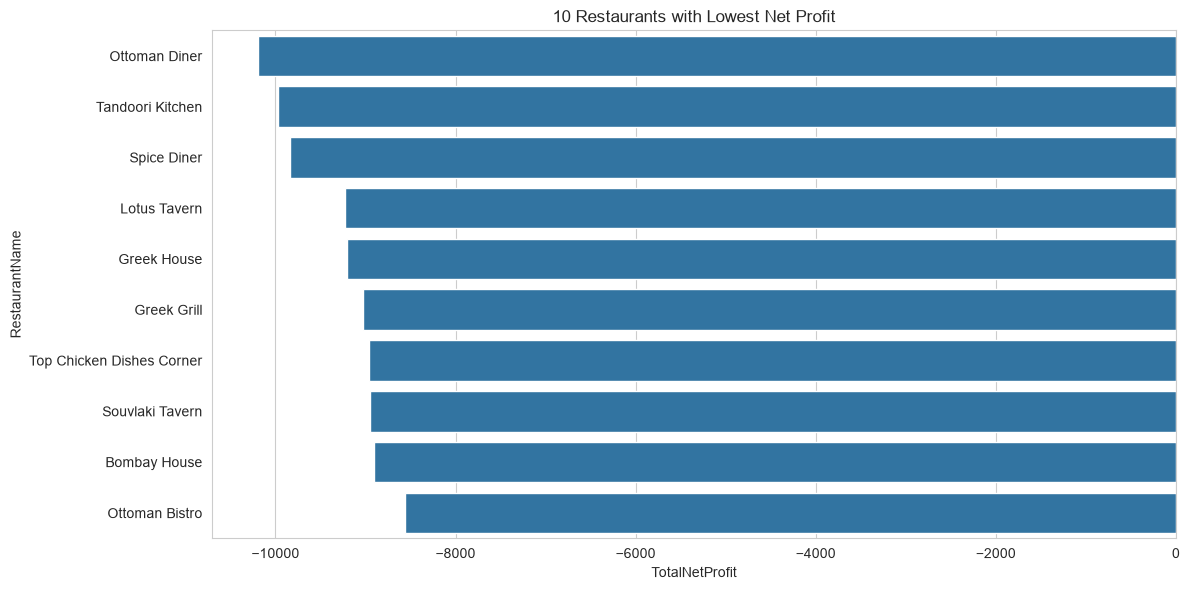

,RestaurantName,TotalNetProfit
1244,Ottoman Diner,-10192.83
885,Tandoori Kitchen,-9974.52
1067,Spice Diner,-9840.65
1649,Lotus Tavern,-9224.14
1269,Greek House,-9202.01
1331,Greek Grill,-9024.43
467,Top Chicken Dishes Corner,-8962.15
1315,Souvlaki Tavern,-8948.12
830,Bombay House,-8905.84
1284,Ottoman Bistro,-8562.72


In [68]:
lowest_profit = df.nsmallest(10, 'TotalNetProfit')

plt.figure(figsize=(12, 6))

sns.barplot(
    data=lowest_profit,
    x='TotalNetProfit',
    y='RestaurantName'
)

plt.title('10 Restaurants with Lowest Net Profit')
plt.tight_layout()
plt.show()

display(
    lowest_profit[
        ['RestaurantName', 'TotalNetProfit']
    ]
)

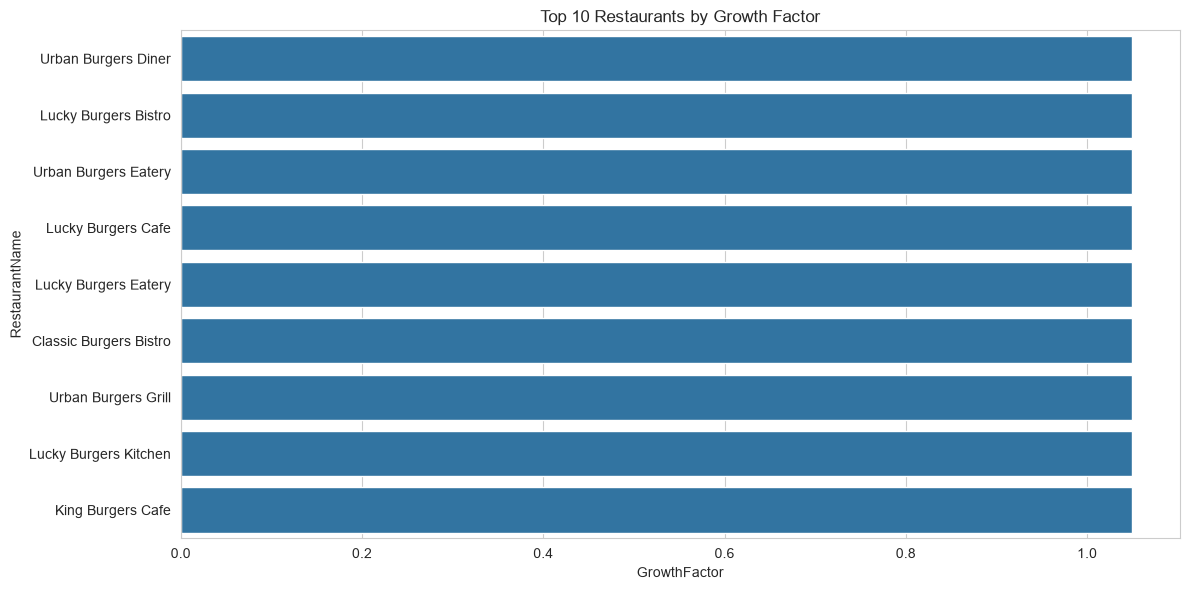

,RestaurantName,GrowthFactor
1,Urban Burgers Diner,1.05
4,Lucky Burgers Bistro,1.05
6,Urban Burgers Eatery,1.05
9,Lucky Burgers Cafe,1.05
10,Lucky Burgers Eatery,1.05
15,Classic Burgers Bistro,1.05
25,Urban Burgers Grill,1.05
27,Lucky Burgers Kitchen,1.05
28,King Burgers Cafe,1.05
30,Classic Burgers Bistro,1.05


In [69]:
if 'GrowthFactor' in df.columns:

    top_growth = df.nlargest(10, 'GrowthFactor')

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=top_growth,
        x='GrowthFactor',
        y='RestaurantName'
    )

    plt.title('Top 10 Restaurants by Growth Factor')
    plt.tight_layout()
    plt.show()

    display(
        top_growth[
            ['RestaurantName', 'GrowthFactor']
        ]
    )

## 15. Preliminary KPI Engineering

This section creates business indicators to evaluate restaurant
growth readiness.

The indicators include:

1. Scale Indicator
2. Cost Burden Rate
3. Aggregator Dependence
4. Delivery Orders Share
5. Revenue per Order
6. Profit Margin
7. Revenue Quality
8. Delivery Expansion Indicator

In [71]:
def normalize_rate(series):

    series = pd.to_numeric(
        series,
        errors='coerce'
    )

    if series.dropna().empty:
        return series

    # Convert percentage format to decimal format
    if series.max() > 1:
        series = series / 100

    return series


rate_columns = [
    'COGSRate',
    'OPEXRate',
    'CommissionRate',
    'InStoreShare',
    'UE_share',
    'DD_share',
    'SD_share'
]

for col in rate_columns:

    if col in df.columns:
        df[col] = normalize_rate(df[col])

print("Rate columns standardized.")

Rate columns standardized.


In [72]:
df['ScaleIndicator'] = (
    df['MonthlyOrders'] * df['GrowthFactor']
)

display(
    df[
        ['RestaurantName', 'MonthlyOrders',
         'GrowthFactor', 'ScaleIndicator']
    ].head()
)

,RestaurantName,MonthlyOrders,GrowthFactor,ScaleIndicator
0,Urban Burgers House,668,1.03,688.04
1,Urban Burgers Diner,1388,1.05,1457.40
2,King Burgers Eatery,1717,1.04,1785.68
3,Classic Burgers Tavern,1083,1.03,1115.49
4,Lucky Burgers Bistro,1230,1.05,1291.50


In [73]:
if {'COGSRate', 'OPEXRate'}.issubset(df.columns):

    df['CostBurdenRate'] = (
        df['COGSRate'] + df['OPEXRate']
    )

    display(
        df[
            ['RestaurantName', 'COGSRate',
             'OPEXRate', 'CostBurdenRate']
        ].head()
    )

,RestaurantName,COGSRate,OPEXRate,CostBurdenRate
0,Urban Burgers House,0.208741,0.366172,0.574913
1,Urban Burgers Diner,0.248217,0.407613,0.655830
2,King Burgers Eatery,0.219688,0.407932,0.627620
3,Classic Burgers Tavern,0.237291,0.437815,0.675106
4,Lucky Burgers Bistro,0.221438,0.433457,0.654894


In [74]:
if {'UE_share', 'DD_share'}.issubset(df.columns):

    df['AggregatorDependence'] = (
        df['UE_share'] + df['DD_share']
    )

    display(
        df[
            ['RestaurantName', 'UE_share',
             'DD_share', 'AggregatorDependence']
        ].head()
    )

,RestaurantName,UE_share,DD_share,AggregatorDependence
0,Urban Burgers House,0.45,0.25,0.7
1,Urban Burgers Diner,0.45,0.25,0.7
2,King Burgers Eatery,0.45,0.25,0.7
3,Classic Burgers Tavern,0.45,0.25,0.7
4,Lucky Burgers Bistro,0.45,0.25,0.7


In [75]:
delivery_share_columns = [
    'UE_share',
    'DD_share',
    'SD_share'
]

available_delivery_shares = [
    col for col in delivery_share_columns
    if col in df.columns
]

if available_delivery_shares:

    df['DeliveryOrdersShare'] = df[
        available_delivery_shares
    ].sum(axis=1)

    display(
        df[
            ['RestaurantName', 'DeliveryOrdersShare']
        ].head()
    )

,RestaurantName,DeliveryOrdersShare
0,Urban Burgers House,1.0
1,Urban Burgers Diner,1.0
2,King Burgers Eatery,1.0
3,Classic Burgers Tavern,1.0
4,Lucky Burgers Bistro,1.0


In [76]:
df['RevenuePerOrder'] = np.where(
    df['MonthlyOrders'] > 0,
    df['TotalRevenue'] / df['MonthlyOrders'],
    np.nan
)

display(
    df[
        ['RestaurantName', 'TotalRevenue',
         'MonthlyOrders', 'RevenuePerOrder']
    ].head()
)

,RestaurantName,TotalRevenue,MonthlyOrders,RevenuePerOrder
0,Urban Burgers House,29371.96,668,43.97
1,Urban Burgers Diner,56144.60,1388,40.45
2,King Burgers Eatery,68731.51,1717,40.03
3,Classic Burgers Tavern,39291.24,1083,36.28
4,Lucky Burgers Bistro,42238.20,1230,34.34


In [77]:
df['ProfitMargin'] = np.where(
    df['TotalRevenue'] > 0,
    df['TotalNetProfit'] / df['TotalRevenue'],
    np.nan
)

display(
    df[
        ['RestaurantName', 'TotalRevenue',
         'TotalNetProfit', 'ProfitMargin']
    ].head()
)

,RestaurantName,TotalRevenue,TotalNetProfit,ProfitMargin
0,Urban Burgers House,29371.96,7964.56,0.271162
1,Urban Burgers Diner,56144.60,8775.70,0.156305
2,King Burgers Eatery,68731.51,14403.26,0.209558
3,Classic Burgers Tavern,39291.24,5266.83,0.134046
4,Lucky Burgers Bistro,42238.20,6119.35,0.144877


In [78]:
df['RevenueQuality'] = (
    df['AOV'] * df['ProfitMargin']
)

display(
    df[
        ['RestaurantName', 'AOV',
         'ProfitMargin', 'RevenueQuality']
    ].head()
)

,RestaurantName,AOV,ProfitMargin,RevenueQuality
0,Urban Burgers House,43.97,0.271162,11.922994
1,Urban Burgers Diner,40.45,0.156305,6.322550
2,King Burgers Eatery,40.03,0.209558,8.388620
3,Classic Burgers Tavern,36.28,0.134046,4.863186
4,Lucky Burgers Bistro,34.34,0.144877,4.975081


In [79]:
if 'DeliveryRadiusKM' in df.columns:

    df['DeliveryExpansionIndicator'] = (
        df['DeliveryRadiusKM']
    )

    display(
        df[
            ['RestaurantName',
             'DeliveryExpansionIndicator']
        ].head()
    )

,RestaurantName,DeliveryExpansionIndicator
0,Urban Burgers House,11
1,Urban Burgers Diner,16
2,King Burgers Eatery,11
3,Classic Burgers Tavern,3
4,Lucky Burgers Bistro,9


In [80]:
kpi_columns = [
    'RestaurantName',
    'ScaleIndicator',
    'CostBurdenRate',
    'AggregatorDependence',
    'DeliveryOrdersShare',
    'RevenuePerOrder',
    'ProfitMargin',
    'RevenueQuality',
    'DeliveryExpansionIndicator'
]

available_kpi_columns = [
    col for col in kpi_columns
    if col in df.columns
]

display(df[available_kpi_columns].head(10))

,RestaurantName,ScaleIndicator,CostBurdenRate,AggregatorDependence,DeliveryOrdersShare,RevenuePerOrder,ProfitMargin,RevenueQuality,DeliveryExpansionIndicator
0,Urban Burgers House,688.04,0.574913,0.7,1.0,43.97,0.271162,11.922994,11
1,Urban Burgers Diner,1457.40,0.655830,0.7,1.0,40.45,0.156305,6.322550,16
2,King Burgers Eatery,1785.68,0.627620,0.7,1.0,40.03,0.209558,8.388620,11
3,Classic Burgers Tavern,1115.49,0.675106,0.7,1.0,36.28,0.134046,4.863186,3
4,Lucky Burgers Bistro,1291.50,0.654894,0.7,1.0,34.34,0.144877,4.975081,9
5,King Burgers Kitchen,851.81,0.660812,0.7,1.0,36.88,0.150247,5.541112,13
6,Urban Burgers Eatery,925.05,0.597092,0.7,1.0,46.32,0.235468,10.906890,7
7,Urban Burgers Tavern,792.00,0.578776,0.7,1.0,34.74,0.181947,6.320850,18
8,Classic Burgers Tavern,605.88,0.655183,0.7,1.0,32.79,0.170745,5.598725,8
9,Lucky Burgers Cafe,600.60,0.650579,0.7,1.0,36.07,0.181670,6.552832,11


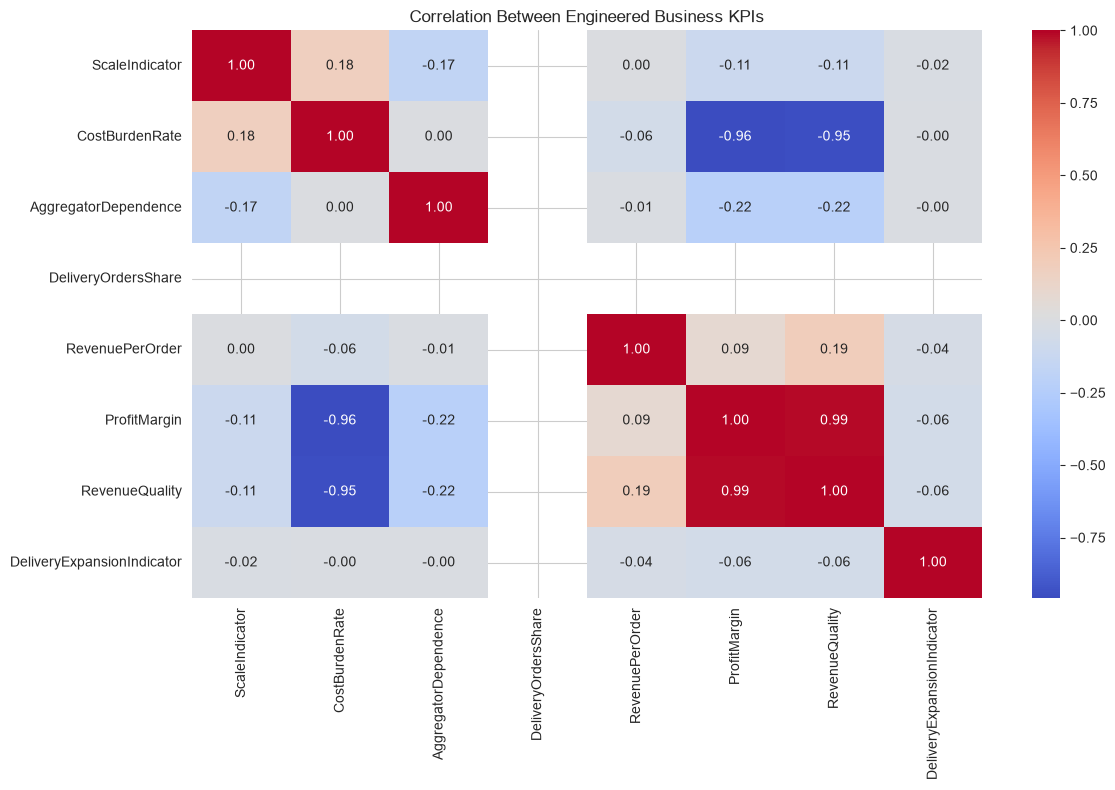

In [81]:
kpi_numeric_columns = [
    col for col in available_kpi_columns
    if col != 'RestaurantName'
]

plt.figure(figsize=(12, 8))

sns.heatmap(
    df[kpi_numeric_columns].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Engineered Business KPIs')
plt.tight_layout()
plt.show()

## 16. Growth Potential Index (GPI)

The Growth Potential Index is a preliminary composite score designed
to compare restaurants using selected business indicators.

It considers business scale, cost discipline, aggregator dependence,
revenue quality, and delivery reach.

The index is exploratory and its weights should be validated
before using it for final business decisions.

In [83]:
gpi_components = [
    'ScaleIndicator',
    'CostBurdenRate',
    'AggregatorDependence',
    'RevenueQuality',
    'DeliveryExpansionIndicator'
]

available_gpi_components = [
    col for col in gpi_components
    if col in df.columns
]

print("GPI Components:")
print(available_gpi_components)

GPI Components:
['ScaleIndicator', 'CostBurdenRate', 'AggregatorDependence', 'RevenueQuality', 'DeliveryExpansionIndicator']


In [84]:
from sklearn.preprocessing import MinMaxScaler

gpi_data = df[available_gpi_components].copy()

gpi_data = gpi_data.replace(
    [np.inf, -np.inf],
    np.nan
)

gpi_data = gpi_data.fillna(
    gpi_data.median()
)

scaler = MinMaxScaler()

gpi_scaled = pd.DataFrame(
    scaler.fit_transform(gpi_data),
    columns=available_gpi_components,
    index=df.index
)

display(gpi_scaled.head())

,ScaleIndicator,CostBurdenRate,AggregatorDependence,RevenueQuality,DeliveryExpansionIndicator
0,0.124649,0.238585,0.5,0.833807,0.533333
1,0.506038,0.404886,0.5,0.581592,0.866667
2,0.668773,0.346909,0.5,0.674637,0.533333
3,0.336546,0.444504,0.5,0.515870,0.000000
4,0.423798,0.402964,0.5,0.520910,0.400000


In [85]:
weights = {
    'ScaleIndicator': 0.25,
    'CostBurdenRate': 0.20,
    'AggregatorDependence': 0.20,
    'RevenueQuality': 0.20,
    'DeliveryExpansionIndicator': 0.15
}

active_weights = {
    col: weights[col]
    for col in available_gpi_components
}

weight_total = sum(active_weights.values())

active_weights = {
    col: weight / weight_total
    for col, weight in active_weights.items()
}

gpi_score = pd.Series(
    0.0,
    index=df.index
)

for col, weight in active_weights.items():

    component_score = gpi_scaled[col]

    # Lower cost burden is treated as favorable
    if col == 'CostBurdenRate':
        component_score = 1 - component_score

    # Aggregator dependence is not automatically bad.
    # It is retained as a diagnostic indicator rather
    # than being inverted in the final GPI.

    gpi_score += component_score * weight

df['GPI_Score'] = gpi_score * 100

print("GPI Score calculated successfully.")

display(
    df[
        ['RestaurantName', 'GPI_Score']
    ].sort_values(
        by='GPI_Score',
        ascending=False
    ).head(10)
)

GPI Score calculated successfully.


,RestaurantName,GPI_Score
419,Top Chicken Dishes Cafe,83.996234
510,Urban Chicken Dishes Cafe,80.660204
504,Top Chicken Dishes Bistro,80.369487
443,Classic Chicken Dishes Diner,79.142832
394,Urban Chicken Dishes Eatery,77.679952
432,Urban Chicken Dishes Cafe,76.574965
501,Top Chicken Dishes House,76.360358
242,Lucky Burgers House,75.519066
1203,Mediterranean Diner,75.438984
762,Tandoori Corner,74.475950


## 17. Growth Potential Classification

Restaurants are grouped into preliminary categories based on their
Growth Potential Index.

The categories are:

- High Growth Potential
- Moderate Growth Potential
- Low Growth Potential

These thresholds are initial exploratory assumptions and should
be reviewed after clustering and business validation.

In [87]:
def classify_growth(score):

    if score >= 70:
        return 'High Growth Potential'

    elif score >= 40:
        return 'Moderate Growth Potential'

    else:
        return 'Low Growth Potential'


df['GrowthClassification'] = (
    df['GPI_Score'].apply(classify_growth)
)

display(
    df[
        ['RestaurantName', 'GPI_Score',
         'GrowthClassification']
    ].head(10)
)

,RestaurantName,GPI_Score,GrowthClassification
0,Urban Burgers House,53.020658,Moderate Growth Potential
1,Urban Burgers Diner,59.185078,Moderate Growth Potential
2,King Burgers Eatery,61.273911,Moderate Growth Potential
3,Classic Burgers Tavern,39.840978,Low Growth Potential
4,Lucky Burgers Bistro,48.953859,Moderate Growth Potential
5,King Burgers Kitchen,47.771354,Moderate Growth Potential
6,Urban Burgers Eatery,50.131074,Moderate Growth Potential
7,Urban Burgers Tavern,56.104448,Moderate Growth Potential
8,Classic Burgers Tavern,40.006782,Moderate Growth Potential
9,Lucky Burgers Cafe,43.989962,Moderate Growth Potential


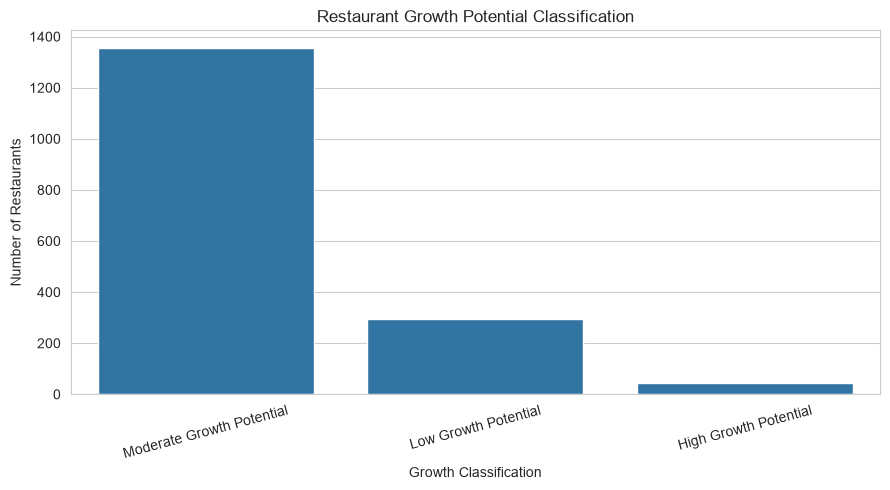

GrowthClassification
Moderate Growth Potential    1356
Low Growth Potential          294
High Growth Potential          46
Name: count, dtype: int64

In [88]:
classification_counts = (
    df['GrowthClassification'].value_counts()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=classification_counts.index,
    y=classification_counts.values
)

plt.title('Restaurant Growth Potential Classification')
plt.xlabel('Growth Classification')
plt.ylabel('Number of Restaurants')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

display(classification_counts)

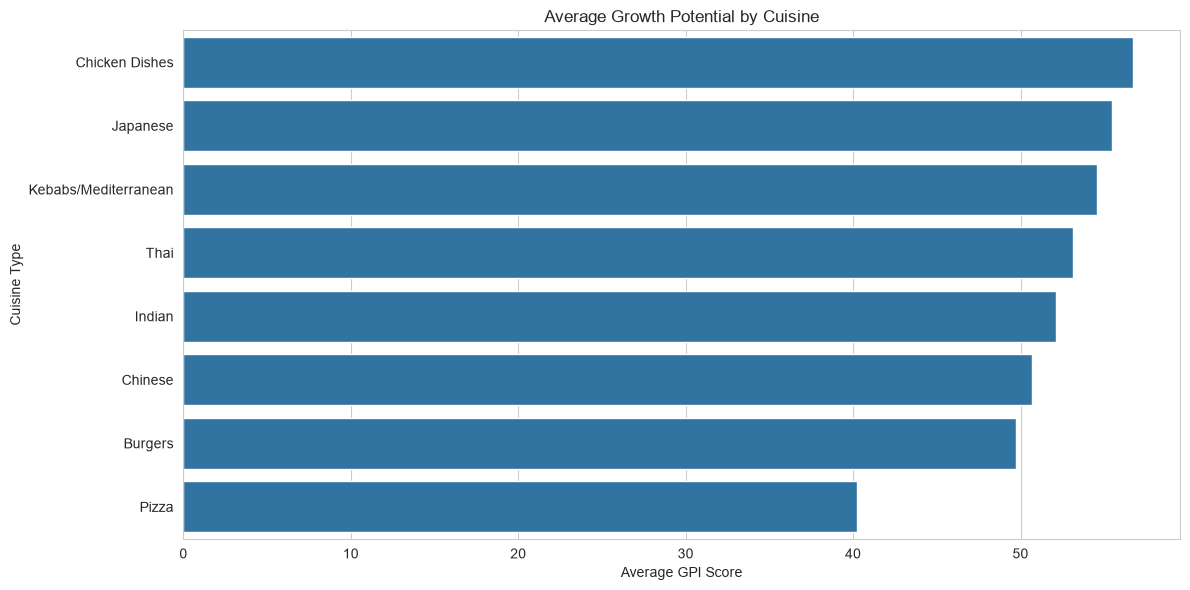

CuisineType
Chicken Dishes          56.691860
Japanese                55.446429
Kebabs/Mediterranean    54.577901
Thai                    53.164277
Indian                  52.125122
Chinese                 50.675824
Burgers                 49.706610
Pizza                   40.263320
Name: GPI_Score, dtype: float64

In [89]:
if 'CuisineType' in df.columns:

    cuisine_gpi = (
        df.groupby('CuisineType')['GPI_Score']
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(12, 6))

    sns.barplot(
        x=cuisine_gpi.values,
        y=cuisine_gpi.index
    )

    plt.title('Average Growth Potential by Cuisine')
    plt.xlabel('Average GPI Score')
    plt.ylabel('Cuisine Type')
    plt.tight_layout()
    plt.show()

    display(cuisine_gpi)

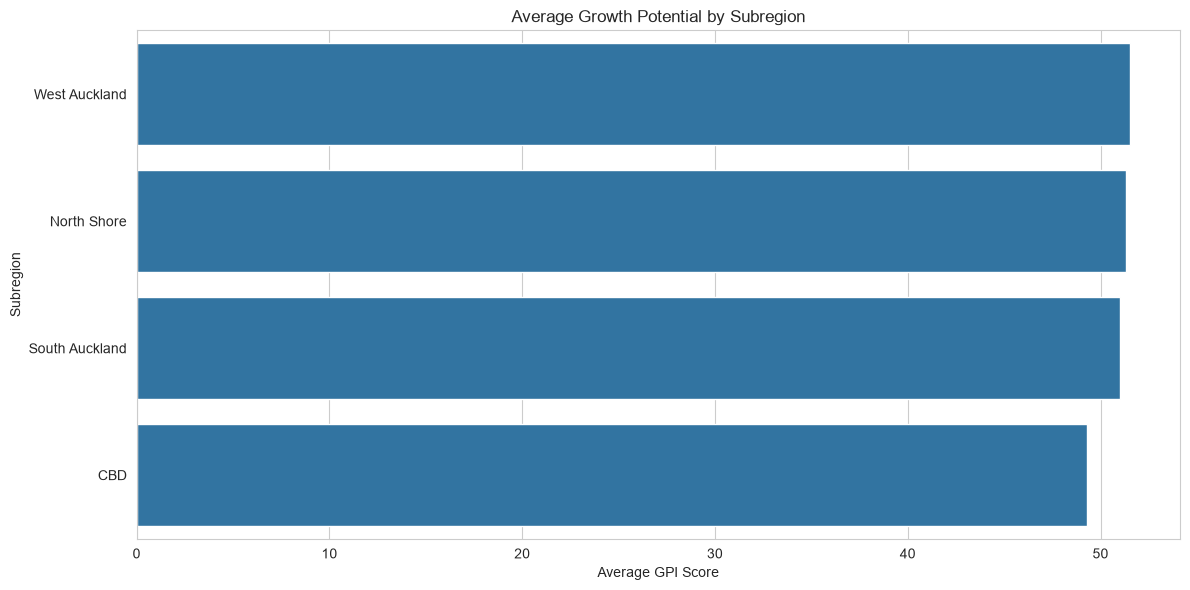

Subregion
West Auckland     51.544935
North Shore       51.326990
South Auckland    51.033861
CBD               49.303415
Name: GPI_Score, dtype: float64

In [90]:
if 'Subregion' in df.columns:

    subregion_gpi = (
        df.groupby('Subregion')['GPI_Score']
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(12, 6))

    sns.barplot(
        x=subregion_gpi.values,
        y=subregion_gpi.index
    )

    plt.title('Average Growth Potential by Subregion')
    plt.xlabel('Average GPI Score')
    plt.ylabel('Subregion')
    plt.tight_layout()
    plt.show()

    display(subregion_gpi)
    

## 18. Business Insights

This section summarizes important findings from restaurant performance,
revenue, profitability, and growth potential analysis.

In [92]:
print("========== RESTAURANT BUSINESS SUMMARY ==========")

print("Total Restaurants:", len(df))

print(
    "Total Revenue:",
    round(df['TotalRevenue'].sum(), 2)
)

print(
    "Total Net Profit:",
    round(df['TotalNetProfit'].sum(), 2)
)

print(
    "Average Profit Margin:",
    round(df['ProfitMargin'].mean() * 100, 2),
    "%"
)

print(
    "Average Growth Potential Score:",
    round(df['GPI_Score'].mean(), 2)
)

========== RESTAURANT BUSINESS SUMMARY ==========
Total Restaurants: 1696
Total Revenue: 77739306.8
Total Net Profit: 7866306.13
Average Profit Margin: 10.45 %
Average Growth Potential Score: 50.82


In [93]:
highest_revenue_restaurant = df.loc[
    df['TotalRevenue'].idxmax()
]

print(
    "Highest Revenue Restaurant:",
    highest_revenue_restaurant['RestaurantName']
)

print(
    "Revenue:",
    highest_revenue_restaurant['TotalRevenue']
)

Highest Revenue Restaurant: Top Burgers Grill
Revenue: 100888.29000000001


In [94]:
highest_profit_restaurant = df.loc[
    df['TotalNetProfit'].idxmax()
]

print(
    "Highest Profit Restaurant:",
    highest_profit_restaurant['RestaurantName']
)

print(
    "Net Profit:",
    highest_profit_restaurant['TotalNetProfit']
)

Highest Profit Restaurant: King Pizza Eatery
Net Profit: 27368.36


In [95]:
print("Growth Classification Summary:\n")

print(
    df['GrowthClassification'].value_counts()
)

Growth Classification Summary:

GrowthClassification
Moderate Growth Potential    1356
Low Growth Potential          294
High Growth Potential          46
Name: count, dtype: int64


In [96]:
print("========== STRATEGIC OBSERVATIONS ==========\n")

print("1. High Growth Potential Restaurants")

display(
    df[
        df['GrowthClassification'] ==
        'High Growth Potential'
    ][
        ['RestaurantName', 'GPI_Score', 'TotalRevenue']
    ].head(10)
)

print("\n2. Moderate Growth Potential Restaurants")

display(
    df[
        df['GrowthClassification'] ==
        'Moderate Growth Potential'
    ][
        ['RestaurantName', 'GPI_Score', 'TotalRevenue']
    ].head(10)
)

print("\n3. Low Growth Potential Restaurants")

display(
    df[
        df['GrowthClassification'] ==
        'Low Growth Potential'
    ][
        ['RestaurantName', 'GPI_Score', 'TotalRevenue']
    ].head(10)
)

========== STRATEGIC OBSERVATIONS ==========

1. High Growth Potential Restaurants


,RestaurantName,GPI_Score,TotalRevenue
242,Lucky Burgers House,75.519066,61602.79
293,Classic Burgers Corner,72.142407,90060.88
394,Urban Chicken Dishes Eatery,77.679952,80254.85
395,Classic Chicken Dishes Cafe,72.641018,87432.24
408,Lucky Chicken Dishes Diner,72.724151,35757.80
419,Top Chicken Dishes Cafe,83.996234,72449.58
426,Lucky Chicken Dishes Diner,70.186143,30754.57
430,Classic Chicken Dishes Diner,74.474109,65050.38
432,Urban Chicken Dishes Cafe,76.574965,66924.00
443,Classic Chicken Dishes Diner,79.142832,55996.35



2. Moderate Growth Potential Restaurants


,RestaurantName,GPI_Score,TotalRevenue
0,Urban Burgers House,53.020658,29371.96
1,Urban Burgers Diner,59.185078,56144.60
2,King Burgers Eatery,61.273911,68731.51
4,Lucky Burgers Bistro,48.953859,42238.20
5,King Burgers Kitchen,47.771354,30499.76
6,Urban Burgers Eatery,50.131074,40807.92
7,Urban Burgers Tavern,56.104448,27792.00
8,Classic Burgers Tavern,40.006782,20067.48
9,Lucky Burgers Cafe,43.989962,20632.04
10,Lucky Burgers Eatery,52.346554,46972.24



3. Low Growth Potential Restaurants


,RestaurantName,GPI_Score,TotalRevenue
3,Classic Burgers Tavern,39.840978,39291.24
16,Classic Burgers Tavern,26.650793,30852.46
25,Urban Burgers Grill,33.136289,24073.36
26,Classic Burgers Tavern,25.611653,32238.99
35,Lucky Burgers Bistro,30.757701,57641.22
43,Classic Burgers Diner,26.958107,21937.28
48,King Burgers Tavern,32.083818,19211.46
50,Classic Burgers Grill,39.601133,54458.67
57,Classic Burgers Corner,22.863155,25064.12
63,Top Burgers House,38.585426,61381.42


## 19. Automated EDA Summary

This section provides a consolidated overview of the dataset,
restaurant performance, and preliminary growth classification.

In [98]:
print("=" * 55)
print("RESTAURANT GROWTH POTENTIAL - EDA SUMMARY")
print("=" * 55)

print("\nDATASET INFORMATION")

print("Total Restaurants:", len(df))
print("Total Features:", df.shape[1])

if 'CuisineType' in df.columns:
    print("Cuisine Types:", df['CuisineType'].nunique())

if 'Segment' in df.columns:
    print("Restaurant Segments:", df['Segment'].nunique())

if 'Subregion' in df.columns:
    print("Subregions:", df['Subregion'].nunique())


print("\nBUSINESS PERFORMANCE")

print("Total Revenue:", round(df['TotalRevenue'].sum(), 2))
print("Total Net Profit:", round(df['TotalNetProfit'].sum(), 2))

print(
    "Average Profit Margin:",
    round(df['ProfitMargin'].mean() * 100, 2),
    "%"
)


print("\nGROWTH POTENTIAL")

print("Average GPI:", round(df['GPI_Score'].mean(), 2))

print("\nClassification Distribution:")

print(df['GrowthClassification'].value_counts())

print("\nEDA SUMMARY COMPLETED")

RESTAURANT GROWTH POTENTIAL - EDA SUMMARY

DATASET INFORMATION
Total Restaurants: 1696
Total Features: 43
Cuisine Types: 8
Restaurant Segments: 4
Subregions: 4

BUSINESS PERFORMANCE
Total Revenue: 77739306.8
Total Net Profit: 7866306.13
Average Profit Margin: 10.45 %

GROWTH POTENTIAL
Average GPI: 50.82

Classification Distribution:
GrowthClassification
Moderate Growth Potential    1356
Low Growth Potential          294
High Growth Potential          46
Name: count, dtype: int64

EDA SUMMARY COMPLETED


## 20. Export Processed Dataset

The final processed dataset contains the original restaurant data,
calculated business KPIs, and preliminary growth classifications.

This dataset will be used in the next stage of machine learning
and strategic restaurant classification.

In [100]:
# Create output folder
os.makedirs('Output', exist_ok=True)

# Export processed dataset
output_path = os.path.join(
    'Output',
    'restaurant_growth_eda_processed.csv'
)

df.to_csv(
    output_path,
    index=False
)

print("Processed dataset exported successfully.")
print("Saved at:", output_path)

Processed dataset exported successfully.
Saved at: Output\restaurant_growth_eda_processed.csv


## 21. EDA Conclusion

The Exploratory Data Analysis provided an overview of restaurant
business performance, revenue distribution, profitability,
operational costs, delivery channels, and growth-related factors.

The analysis identified differences in restaurant scale, monthly demand,
average order value, profitability, and delivery channel usage.

Business indicators such as Scale Indicator, Cost Burden Rate,
Aggregator Dependence, Revenue per Order, Profit Margin, and
Revenue Quality were created to evaluate different aspects
of restaurant performance.

A preliminary Growth Potential Index was developed to compare
restaurants using selected business indicators.

The findings provide a foundation for the next phase of the project.

The next stage will involve feature selection, data preprocessing,
dimensionality reduction, and clustering techniques such as
K-Means and Hierarchical Clustering.

The final objective is to develop a strategic classification system
that identifies restaurant growth opportunities and supports
data-driven business decisions.

# Phase 2: Machine Learning and Strategic Classification

## 22. Introduction

This phase applies unsupervised machine learning techniques to
identify groups of restaurants with similar business characteristics.

The model analyzes factors such as monthly orders, growth factor,
average order value, revenue, profitability, operating costs,
delivery channel dependence, and delivery reach.

The main objective is to discover meaningful restaurant segments
and understand their growth readiness.

## Algorithms Used

1. K-Means Clustering
2. Hierarchical Clustering
3. DBSCAN Clustering
4. Principal Component Analysis (PCA)

The clustering results will support strategic restaurant
classification and business recommendations.

## Machine Learning Workflow

Feature Selection
        ↓
Data Preprocessing
        ↓
Outlier Treatment
        ↓
Feature Scaling
        ↓
Dimensionality Reduction (PCA)
        ↓
Optimal Cluster Selection
        ↓
K-Means Clustering
        ↓
Hierarchical Clustering
        ↓
Cluster Evaluation
        ↓
Strategic Classification

## 23. Import Machine Learning Libraries

Import the required libraries for preprocessing, dimensionality
reduction, clustering, and model evaluation.

In [105]:
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.neighbors import NearestNeighbors

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

print("Machine learning libraries imported successfully.")

Machine learning libraries imported successfully.


## 24. Feature Selection

Feature selection identifies the most relevant business variables
for restaurant growth potential modeling.

The selected features represent:

- Business Scale
- Growth Performance
- Revenue Quality
- Cost Structure
- Delivery Channel Dependence
- Geographic Reach

Restaurant names and IDs are excluded because they are identifiers
rather than business performance indicators.

In [107]:
# Numerical business features
candidate_features = [
    'GrowthFactor',
    'AOV',
    'MonthlyOrders',

    'InStoreOrdersCount',
    'UberEatsOrdersCount',
    'DoorDashOrdersCount',
    'SelfDeliveryOrdersCount',

    'InStoreRevenue',
    'UberEatsRevenue',
    'DoorDashRevenue',
    'SelfDeliveryRevenue',

    'COGSRate',
    'OPEXRate',
    'CommissionRate',

    'DeliveryRadiusKM',
    'DeliveryCostOrder',
    'SD_DeliveryTotalCost',

    'InStoreShare',
    'UE_share',
    'DD_share',
    'SD_share',

    'ProfitMargin',
    'RevenuePerOrder',
    'CostBurdenRate',
    'AggregatorDependence',
    'DeliveryOrdersShare',
    'RevenueQuality'
]

# Keep only columns available in the dataset
numerical_features = [
    col for col in candidate_features
    if col in df.columns
]

print("Selected Numerical Features:")
print(numerical_features)

print("\nTotal Selected Features:", len(numerical_features))

Selected Numerical Features:
['GrowthFactor', 'AOV', 'MonthlyOrders', 'InStoreRevenue', 'UberEatsRevenue', 'DoorDashRevenue', 'SelfDeliveryRevenue', 'COGSRate', 'OPEXRate', 'CommissionRate', 'DeliveryRadiusKM', 'SD_DeliveryTotalCost', 'InStoreShare', 'UE_share', 'DD_share', 'SD_share', 'ProfitMargin', 'RevenuePerOrder', 'CostBurdenRate', 'AggregatorDependence', 'DeliveryOrdersShare', 'RevenueQuality']

Total Selected Features: 22


In [108]:
candidate_categorical = [
    'CuisineType',
    'Segment',
    'Subregion'
]

categorical_features = [
    col for col in candidate_categorical
    if col in df.columns
]

print("Selected Categorical Features:")
print(categorical_features)

Selected Categorical Features:
['CuisineType', 'Segment', 'Subregion']


In [109]:
model_df = df[
    numerical_features + categorical_features
].copy()

print("Modeling Dataset Shape:", model_df.shape)

display(model_df.head())

Modeling Dataset Shape: (1696, 25)


,GrowthFactor,AOV,MonthlyOrders,InStoreRevenue,UberEatsRevenue,DoorDashRevenue,SelfDeliveryRevenue,COGSRate,OPEXRate,CommissionRate,...,SD_share,ProfitMargin,RevenuePerOrder,CostBurdenRate,AggregatorDependence,DeliveryOrdersShare,RevenueQuality,CuisineType,Segment,Subregion
0,1.03,43.97,668,8662.09,9321.64,5188.46,6199.77,0.208741,0.366172,0.28,...,0.3,0.271162,43.97,0.574913,0.7,1.0,11.922994,Burgers,Cafe,North Shore
1,1.05,40.45,1388,10476.55,20548.60,11406.90,13712.55,0.248217,0.407613,0.28,...,0.3,0.156305,40.45,0.655830,0.7,1.0,6.322550,Burgers,QSR,South Auckland
2,1.04,40.03,1717,20975.72,21496.11,11928.94,14330.74,0.219688,0.407932,0.30,...,0.3,0.209558,40.03,0.627620,0.7,1.0,8.388620,Burgers,Cafe,West Auckland
3,1.03,36.28,1083,7836.48,14149.20,7872.76,9432.80,0.237291,0.437815,0.33,...,0.3,0.134046,36.28,0.675106,0.7,1.0,4.863186,Burgers,QSR,North Shore
4,1.05,34.34,1230,8962.74,14972.24,8310.28,9992.94,0.221438,0.433457,0.33,...,0.3,0.144877,34.34,0.654894,0.7,1.0,4.975081,Burgers,Cafe,South Auckland


In [110]:
print("Feature Data Types:\n")

display(model_df.dtypes.to_frame(name='Data Type'))

Feature Data Types:



,Data Type
GrowthFactor,float64
AOV,float64
MonthlyOrders,int64
InStoreRevenue,float64
UberEatsRevenue,float64
DoorDashRevenue,float64
SelfDeliveryRevenue,float64
COGSRate,float64
OPEXRate,float64
CommissionRate,float64


## 25. Data Preprocessing

Data preprocessing prepares the selected features for machine learning.

It includes handling missing values, checking infinite values,
and converting numerical and categorical variables into suitable formats.

In [112]:
# Replace infinite values
model_df = model_df.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Invalid infinite values handled.")

Invalid infinite values handled.


In [113]:
print("Missing Values in Modeling Dataset:\n")

display(
    model_df.isnull().sum().to_frame(
        name='Missing Values'
    )
)

Missing Values in Modeling Dataset:



,Missing Values
GrowthFactor,0
AOV,0
MonthlyOrders,0
InStoreRevenue,0
UberEatsRevenue,0
DoorDashRevenue,0
SelfDeliveryRevenue,0
COGSRate,0
OPEXRate,0
CommissionRate,0


In [114]:
# Numerical preprocessing
numerical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ]
)

# Categorical preprocessing
from sklearn.preprocessing import OneHotEncoder

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [115]:
X_processed = preprocessor.fit_transform(model_df)

# Convert sparse matrix to dense array when required
if hasattr(X_processed, 'toarray'):
    X_processed = X_processed.toarray()

print("Preprocessing completed.")
print("Processed Dataset Shape:", X_processed.shape)

Preprocessing completed.
Processed Dataset Shape: (1696, 38)


In [116]:
print("Missing Values:", np.isnan(X_processed).sum())
print("Infinite Values:", np.isinf(X_processed).sum())

print("\nProcessed Feature Matrix:")
display(pd.DataFrame(X_processed).head())

Missing Values: 0
Infinite Values: 0

Processed Feature Matrix:


,0,1,2,3,4,5,6,7,8,9,...,28,29,30,31,32,33,34,35,36,37
0,-0.5,0.730457,-0.736390,0.244645,-0.784209,-0.753154,-0.300060,-0.438040,-0.538958,-0.50,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.5,0.273759,0.295129,0.481941,0.285916,0.317020,0.907578,-0.108858,-0.049293,-0.50,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,0.0,0.219267,0.766476,1.855025,0.376230,0.406861,1.006948,-0.346758,-0.045525,0.00,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-0.5,-0.267272,-0.141834,0.136672,-0.324058,-0.291195,0.219632,-0.199966,0.307575,0.75,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4,0.5,-0.518975,0.068768,0.283965,-0.245608,-0.215899,0.309671,-0.332168,0.256076,0.75,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


## 26. Outlier Analysis

Outliers are observations that differ significantly from the
majority of the dataset.

This section examines important business variables to identify
extreme values that may influence clustering results.

Outliers will be investigated rather than automatically removed,
because unusually high restaurant performance may represent
genuine business opportunities.

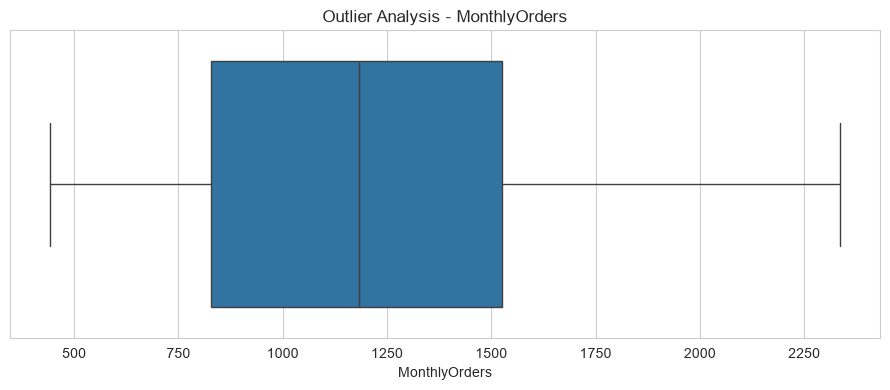

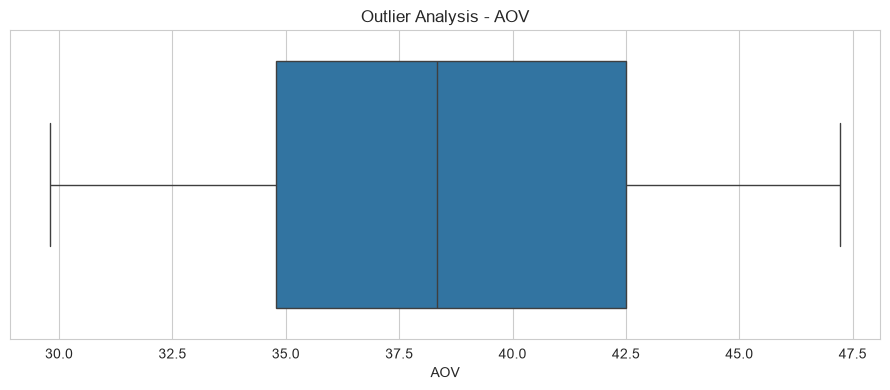

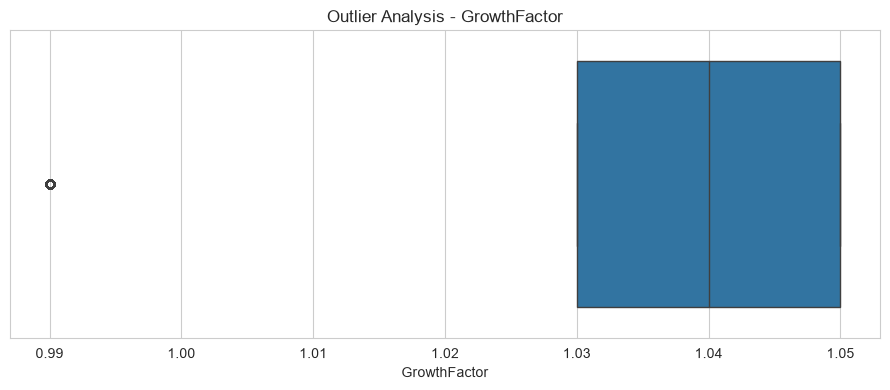

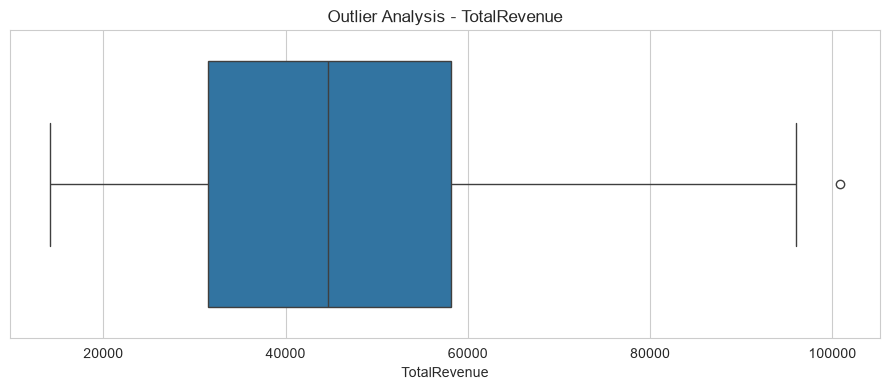

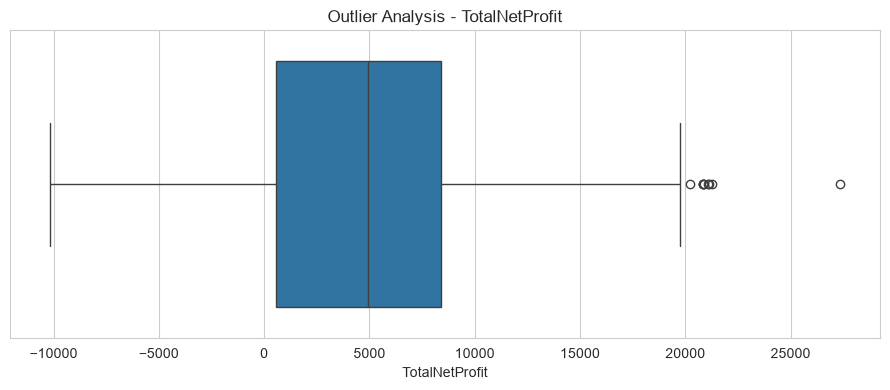

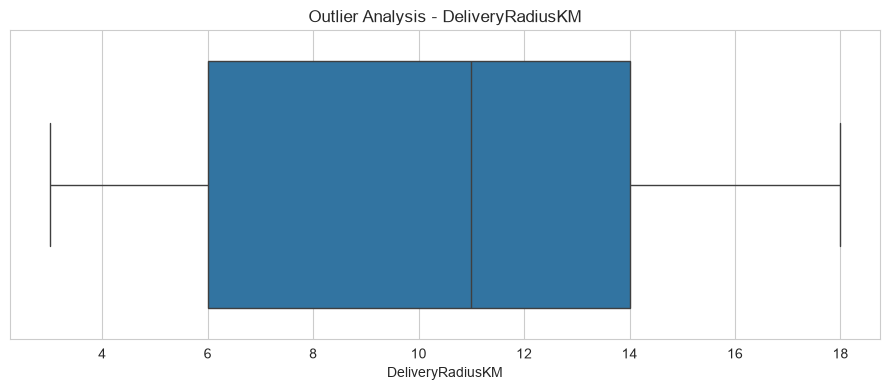

In [118]:
outlier_features = [
    col for col in [
        'MonthlyOrders',
        'AOV',
        'GrowthFactor',
        'TotalRevenue',
        'TotalNetProfit',
        'DeliveryRadiusKM'
    ]
    if col in df.columns
]

for col in outlier_features:

    plt.figure(figsize=(9, 4))

    sns.boxplot(x=df[col])

    plt.title(f'Outlier Analysis - {col}')
    plt.tight_layout()
    plt.show()

In [119]:
outlier_summary = []

for col in outlier_features:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    outlier_summary.append({
        'Feature': col,
        'Outlier Count': len(outliers),
        'Lower Limit': lower_limit,
        'Upper Limit': upper_limit
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary)

,Feature,Outlier Count,Lower Limit,Upper Limit
0,MonthlyOrders,0,-220.00000,2572.00000
1,AOV,0,23.22625,54.05625
2,GrowthFactor,410,1.00000,1.08000
3,TotalRevenue,1,-8418.94750,98137.55250
4,TotalNetProfit,9,-11237.40125,20213.30875
5,DeliveryRadiusKM,0,-6.00000,26.00000


## 27. Principal Component Analysis (PCA)

Principal Component Analysis is a dimensionality reduction technique.

It transforms a large set of correlated features into a smaller
number of principal components while preserving as much variation
in the data as possible.

PCA helps simplify the dataset and supports visualization
of restaurant clusters.

In [121]:
pca = PCA()

X_pca = pca.fit_transform(X_processed)

print("PCA Applied Successfully.")

print("Original Feature Count:", X_processed.shape[1])
print("Principal Components:", X_pca.shape[1])

PCA Applied Successfully.
Original Feature Count: 38
Principal Components: 38


In [122]:
explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(
    explained_variance
)

pca_summary = pd.DataFrame({
    'Principal Component': [
        f'PC{i+1}' for i in range(len(explained_variance))
    ],
    'Explained Variance': explained_variance,
    'Cumulative Variance': cumulative_variance
})

display(pca_summary.head(15))

,Principal Component,Explained Variance,Cumulative Variance
0,PC1,0.236901,0.236901
1,PC2,0.196989,0.433890
2,PC3,0.139404,0.573294
3,PC4,0.110355,0.683649
4,PC5,0.055722,0.739371
5,PC6,0.043049,0.782420
6,PC7,0.036147,0.818568
7,PC8,0.028067,0.846635
8,PC9,0.024079,0.870714
9,PC10,0.021964,0.892677


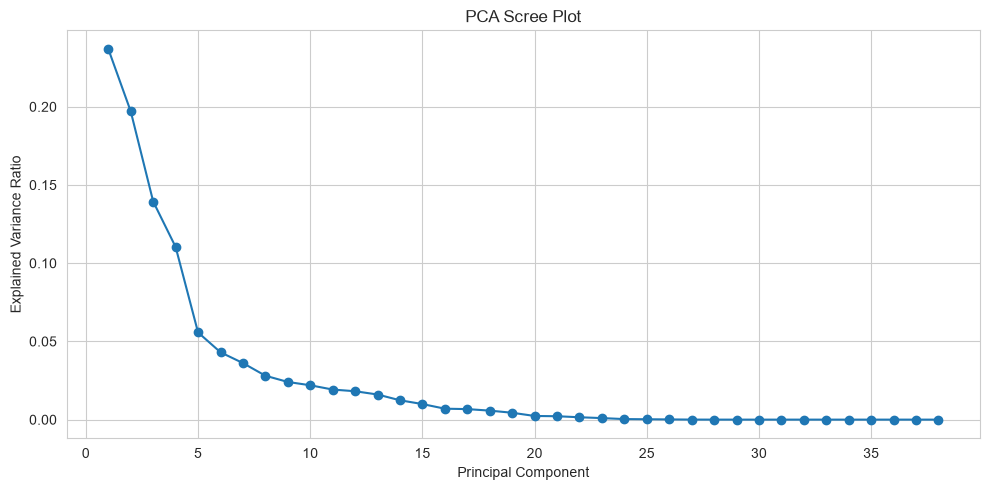

In [123]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker='o'
)

plt.title('PCA Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.tight_layout()
plt.show()

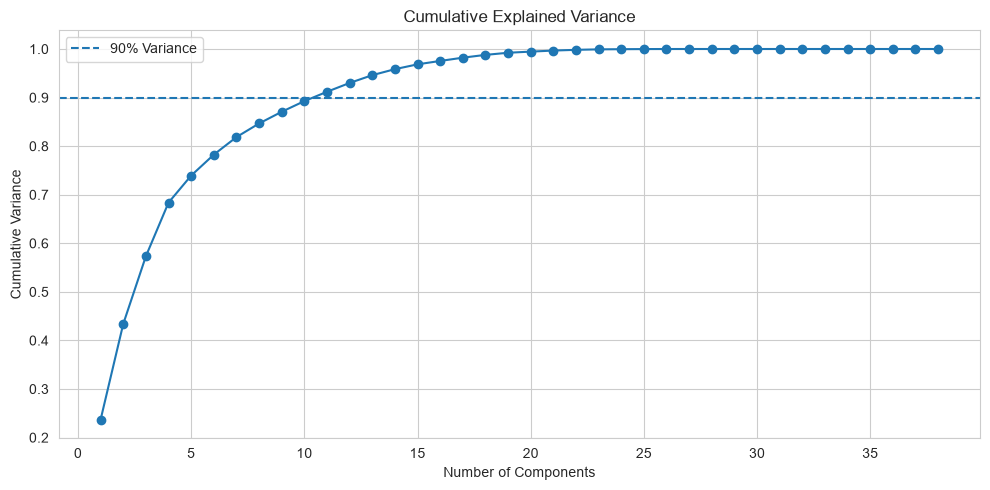

In [124]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.axhline(
    y=0.90,
    linestyle='--',
    label='90% Variance'
)

plt.title('Cumulative Explained Variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Variance')
plt.legend()
plt.tight_layout()
plt.show()

In [125]:
# Select enough components to explain at least 90% variance
n_components = np.argmax(
    cumulative_variance >= 0.90
) + 1

print("Components Required for 90% Variance:", n_components)

pca_reduced = PCA(
    n_components=n_components
)

X_reduced = pca_reduced.fit_transform(
    X_processed
)

print("Reduced Dataset Shape:", X_reduced.shape)

Components Required for 90% Variance: 11
Reduced Dataset Shape: (1696, 11)


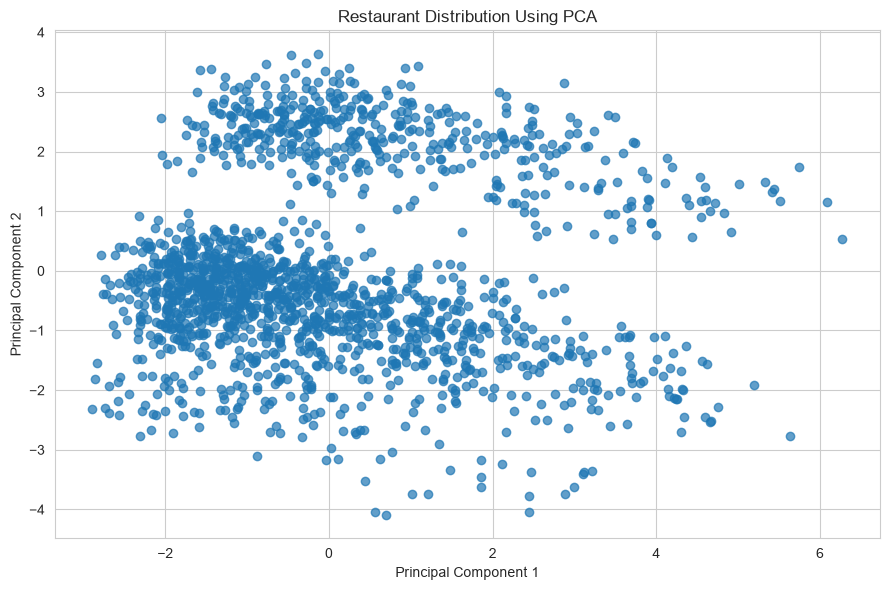

In [126]:
if X_reduced.shape[1] >= 2:

    plt.figure(figsize=(9, 6))

    plt.scatter(
        X_reduced[:, 0],
        X_reduced[:, 1],
        alpha=0.7
    )

    plt.title('Restaurant Distribution Using PCA')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.tight_layout()
    plt.show()

else:
    print("Only one component was selected. Use the first two components from X_pca for visualization.")

## 28. Optimal Cluster Selection

K-Means requires the number of clusters to be specified in advance.

This section uses the Elbow Method and Silhouette Score to
identify a suitable number of clusters.

The Elbow Method examines the within-cluster sum of squares,
while the Silhouette Score measures cluster separation.

  File "C:\Users\Shrushti\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Shrushti\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Shrushti\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Shrushti\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


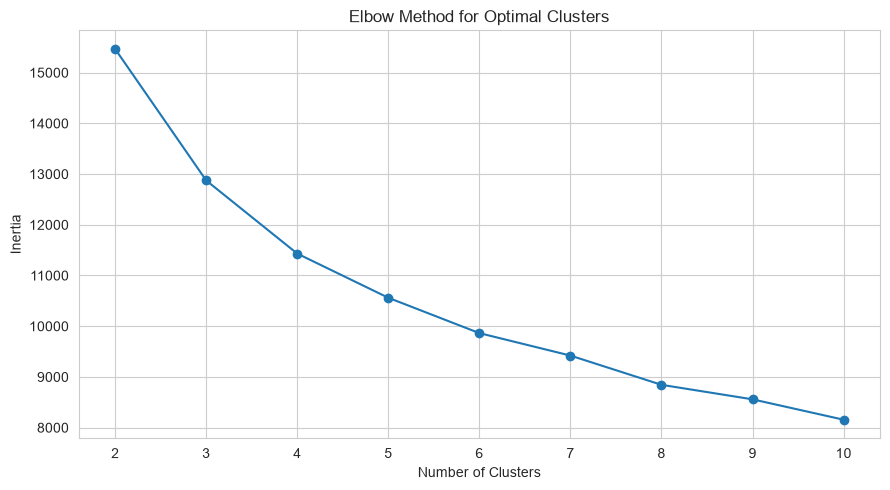

In [128]:
inertia_values = []

max_clusters = min(10, len(X_reduced) - 1)

for k in range(2, max_clusters + 1):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_reduced)

    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(
    range(2, max_clusters + 1),
    inertia_values,
    marker='o'
)

plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.tight_layout()
plt.show()

In [129]:
silhouette_values = []

for k in range(2, max_clusters + 1):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_reduced)

    score = silhouette_score(
        X_reduced,
        labels
    )

    silhouette_values.append(score)

silhouette_results = pd.DataFrame({
    'Number of Clusters': range(2, max_clusters + 1),
    'Silhouette Score': silhouette_values
})

display(silhouette_results)

,Number of Clusters,Silhouette Score
0,2,0.202679
1,3,0.210279
2,4,0.201419
3,5,0.176752
4,6,0.184361
5,7,0.181910
6,8,0.179276
7,9,0.168651
8,10,0.174532


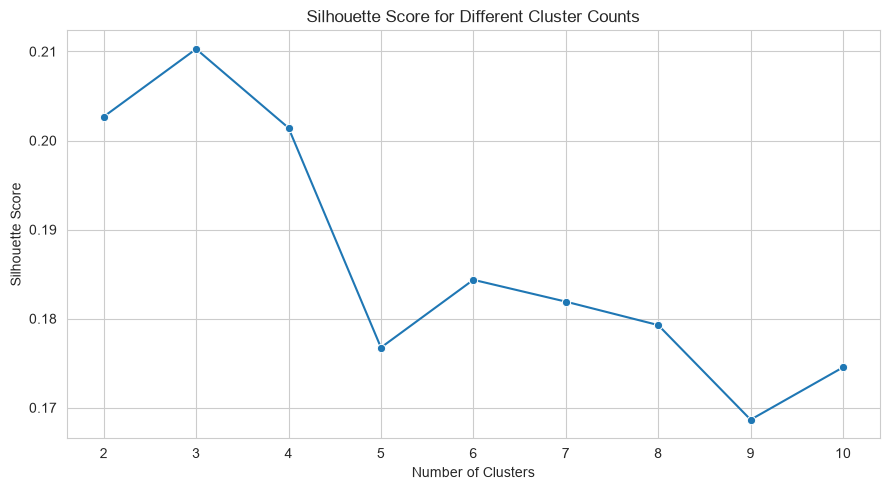

In [130]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=silhouette_results,
    x='Number of Clusters',
    y='Silhouette Score',
    marker='o'
)

plt.title('Silhouette Score for Different Cluster Counts')
plt.tight_layout()
plt.show()

In [131]:
best_k = int(
    silhouette_results.loc[
        silhouette_results['Silhouette Score'].idxmax(),
        'Number of Clusters'
    ]
)

print("Best Cluster Count Based on Silhouette Score:", best_k)

Best Cluster Count Based on Silhouette Score: 3


## 29. K-Means Clustering

K-Means is an unsupervised machine learning algorithm that groups
similar observations into clusters.

The algorithm assigns restaurants to clusters based on similarities
in their business performance and operational characteristics.

The resulting clusters will be analyzed to understand different
restaurant growth profiles.

In [133]:
kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(
    X_reduced
)

df['KMeans_Cluster'] = kmeans_labels

print("K-Means clustering completed successfully.")

display(
    df[
        ['RestaurantName', 'KMeans_Cluster']
    ].head(10)
)

K-Means clustering completed successfully.


,RestaurantName,KMeans_Cluster
0,Urban Burgers House,1
1,Urban Burgers Diner,0
2,King Burgers Eatery,0
3,Classic Burgers Tavern,1
4,Lucky Burgers Bistro,1
5,King Burgers Kitchen,1
6,Urban Burgers Eatery,1
7,Urban Burgers Tavern,1
8,Classic Burgers Tavern,1
9,Lucky Burgers Cafe,1


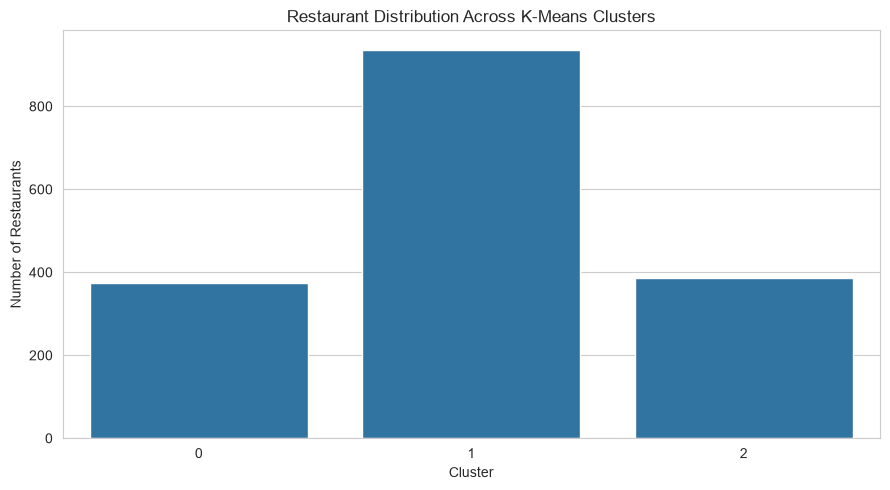

KMeans_Cluster
0    375
1    936
2    385
Name: count, dtype: int64

In [134]:
cluster_counts = df['KMeans_Cluster'].value_counts().sort_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

plt.title('Restaurant Distribution Across K-Means Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Restaurants')
plt.tight_layout()
plt.show()

display(cluster_counts)

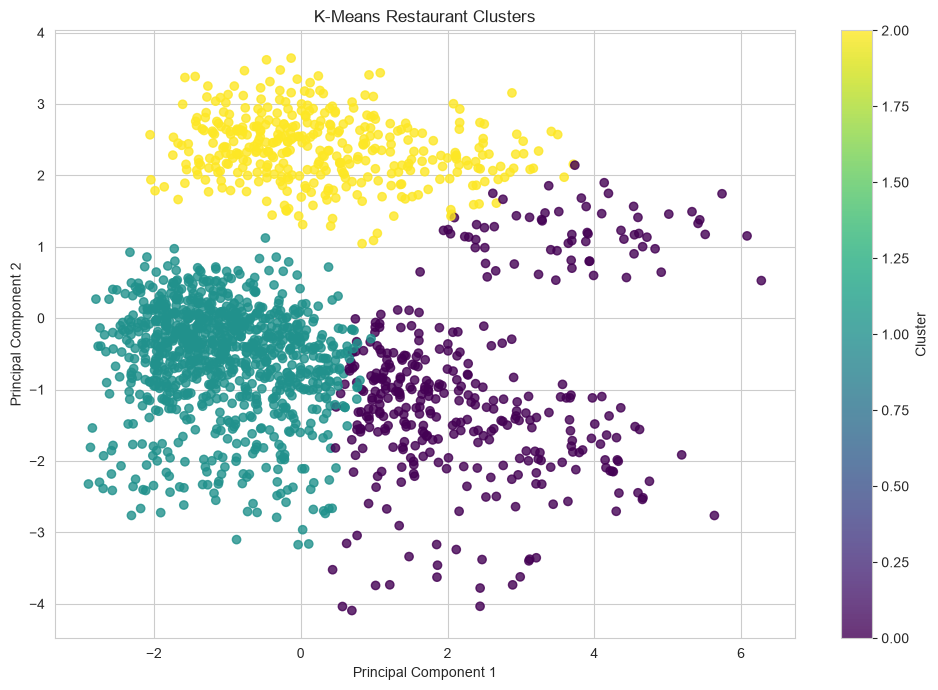

In [135]:
if X_reduced.shape[1] >= 2:

    plt.figure(figsize=(10, 7))

    scatter = plt.scatter(
        X_reduced[:, 0],
        X_reduced[:, 1],
        c=kmeans_labels,
        cmap='viridis',
        alpha=0.8
    )

    plt.title('K-Means Restaurant Clusters')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')

    plt.colorbar(
        scatter,
        label='Cluster'
    )

    plt.tight_layout()
    plt.show()

In [136]:
kmeans_silhouette = silhouette_score(
    X_reduced,
    kmeans_labels
)

kmeans_davies = davies_bouldin_score(
    X_reduced,
    kmeans_labels
)

print("K-Means Evaluation")

print("Silhouette Score:", round(kmeans_silhouette, 4))

print("Davies-Bouldin Score:", round(kmeans_davies, 4))

K-Means Evaluation
Silhouette Score: 0.2103
Davies-Bouldin Score: 1.6195


## 30. Hierarchical Clustering

Hierarchical clustering groups restaurants based on their similarity
and represents the relationships through a tree-like structure.

A dendrogram helps visualize how restaurants or groups merge
at different similarity levels.

This technique provides another perspective for identifying
restaurant segments.

In [138]:
# Limit the number of observations for readable dendrograms
sample_size = min(100, len(X_reduced))

hierarchy_sample = X_reduced[:sample_size]

linkage_matrix = linkage(
    hierarchy_sample,
    method='ward'
)

print("Hierarchical linkage matrix created.")

Hierarchical linkage matrix created.


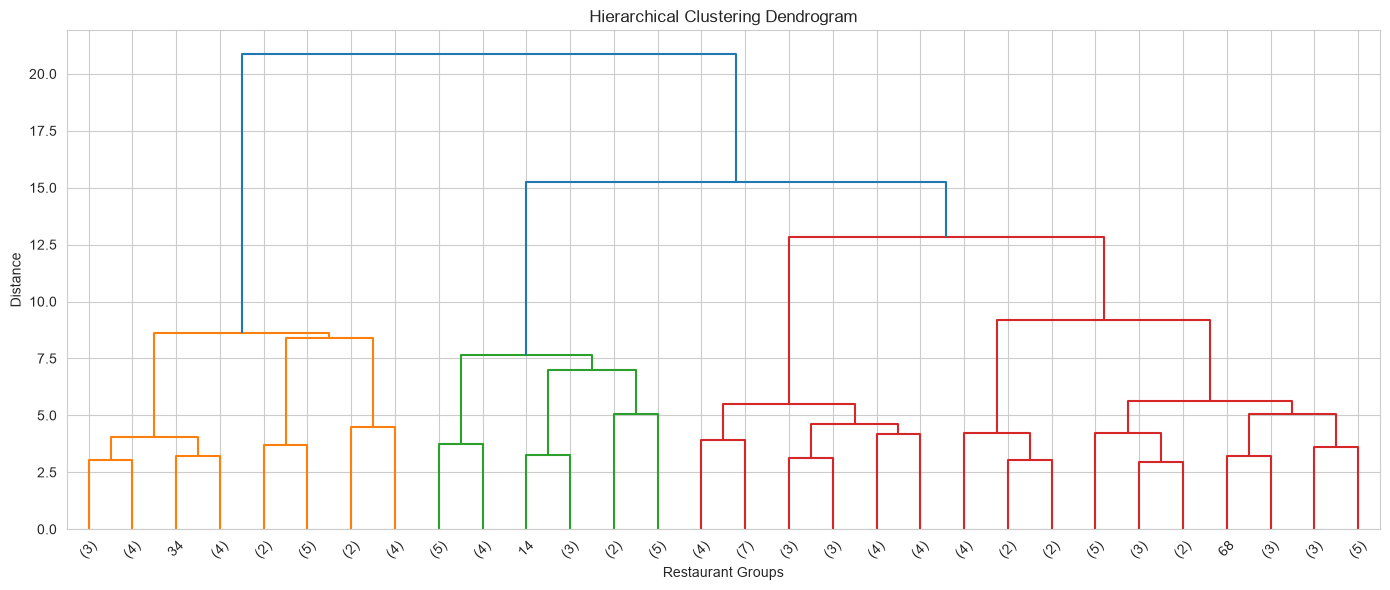

In [139]:
plt.figure(figsize=(14, 6))

dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30
)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Restaurant Groups')
plt.ylabel('Distance')
plt.tight_layout()
plt.show()

In [140]:
hierarchical_model = AgglomerativeClustering(
    n_clusters=best_k,
    linkage='ward'
)

hierarchical_labels = hierarchical_model.fit_predict(
    X_reduced
)

df['Hierarchical_Cluster'] = hierarchical_labels

print("Hierarchical clustering completed.")

display(
    df[
        ['RestaurantName', 'Hierarchical_Cluster']
    ].head(10)
)

Hierarchical clustering completed.


,RestaurantName,Hierarchical_Cluster
0,Urban Burgers House,2
1,Urban Burgers Diner,2
2,King Burgers Eatery,2
3,Classic Burgers Tavern,2
4,Lucky Burgers Bistro,2
5,King Burgers Kitchen,2
6,Urban Burgers Eatery,2
7,Urban Burgers Tavern,0
8,Classic Burgers Tavern,0
9,Lucky Burgers Cafe,0


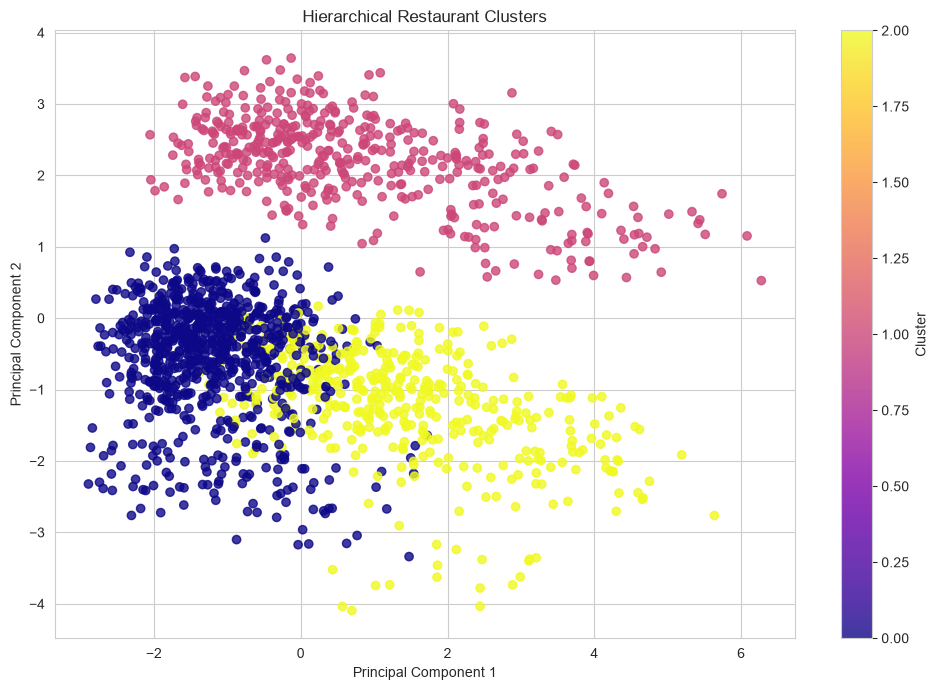

In [141]:
if X_reduced.shape[1] >= 2:

    plt.figure(figsize=(10, 7))

    scatter = plt.scatter(
        X_reduced[:, 0],
        X_reduced[:, 1],
        c=hierarchical_labels,
        cmap='plasma',
        alpha=0.8
    )

    plt.title('Hierarchical Restaurant Clusters')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')

    plt.colorbar(
        scatter,
        label='Cluster'
    )

    plt.tight_layout()
    plt.show()

In [142]:
hierarchical_silhouette = silhouette_score(
    X_reduced,
    hierarchical_labels
)

hierarchical_davies = davies_bouldin_score(
    X_reduced,
    hierarchical_labels
)

print("Hierarchical Clustering Evaluation")

print(
    "Silhouette Score:",
    round(hierarchical_silhouette, 4)
)

print(
    "Davies-Bouldin Score:",
    round(hierarchical_davies, 4)
)

Hierarchical Clustering Evaluation
Silhouette Score: 0.1758
Davies-Bouldin Score: 1.8502


## 31. DBSCAN Clustering

DBSCAN is a density-based clustering algorithm.

It groups closely located observations and identifies observations
that do not belong to dense groups as noise.

Unlike K-Means, DBSCAN does not require the number of clusters
to be specified in advance.

In [144]:
dbscan_model = DBSCAN(
    eps=1.5,
    min_samples=3
)

dbscan_labels = dbscan_model.fit_predict(
    X_reduced
)

df['DBSCAN_Cluster'] = dbscan_labels

print("DBSCAN clustering completed.")

display(
    df['DBSCAN_Cluster'].value_counts()
)

DBSCAN clustering completed.


DBSCAN_Cluster
 0     615
 2     256
 1     232
-1     178
 4      83
 38     31
 26     18
 34     18
 8      15
 5      15
 37     14
 3      14
 14     12
 30     12
 35     11
 42     11
 44      9
 23      8
 25      8
 20      7
 36      6
 48      6
 17      6
 45      6
 13      5
 7       5
 24      5
 18      5
 15      4
 39      4
 19      4
 11      4
 16      4
 22      4
 49      4
 51      3
 47      3
 46      3
 50      3
 43      3
 41      3
 40      3
 12      3
 21      3
 27      3
 6       3
 9       3
 10      3
 33      3
 31      3
 32      3
 28      3
 29      3
 52      3
Name: count, dtype: int64

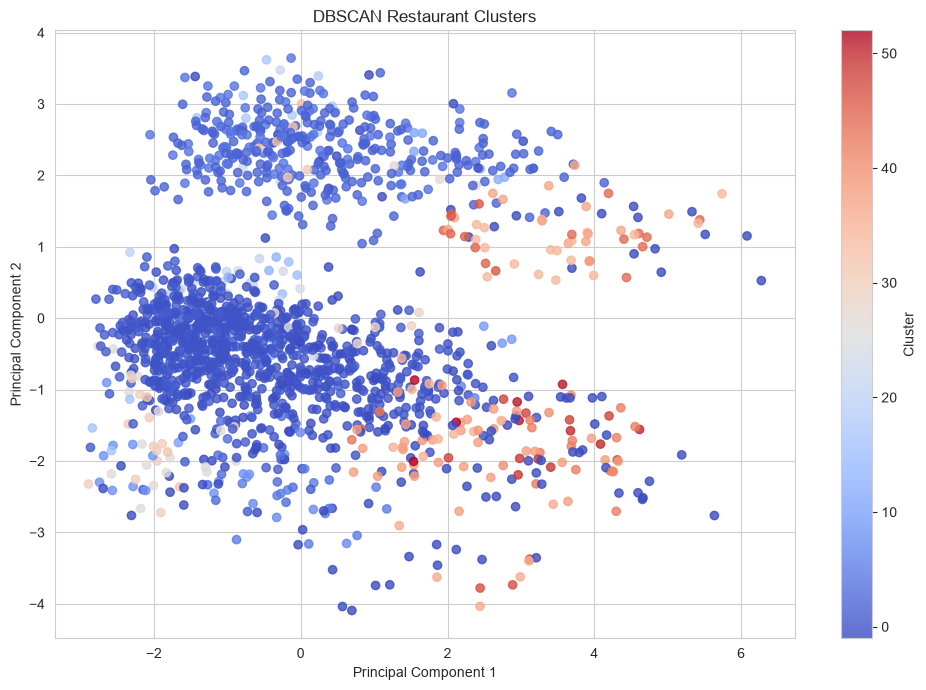

In [145]:
if X_reduced.shape[1] >= 2:

    plt.figure(figsize=(10, 7))

    scatter = plt.scatter(
        X_reduced[:, 0],
        X_reduced[:, 1],
        c=dbscan_labels,
        cmap='coolwarm',
        alpha=0.8
    )

    plt.title('DBSCAN Restaurant Clusters')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')

    plt.colorbar(
        scatter,
        label='Cluster'
    )

    plt.tight_layout()
    plt.show()

In [146]:
dbscan_cluster_count = len(
    set(dbscan_labels) - {-1}
)

if 2 <= dbscan_cluster_count < len(df):

    dbscan_silhouette = silhouette_score(
        X_reduced,
        dbscan_labels
    )

    print(
        "DBSCAN Silhouette Score:",
        round(dbscan_silhouette, 4)
    )

else:
    print(
        "DBSCAN did not produce enough distinct clusters "
        "for silhouette evaluation."
    )

DBSCAN Silhouette Score: -0.1148


## 32. Clustering Algorithm Comparison

This section compares K-Means, Hierarchical Clustering,
and DBSCAN based on their clustering performance.

The comparison helps identify a suitable clustering approach
for the final restaurant strategic classification system.

In [148]:
comparison_results = []

comparison_results.append({
    'Algorithm': 'K-Means',
    'Silhouette Score': kmeans_silhouette,
    'Davies-Bouldin Score': kmeans_davies
})

comparison_results.append({
    'Algorithm': 'Hierarchical',
    'Silhouette Score': hierarchical_silhouette,
    'Davies-Bouldin Score': hierarchical_davies
})

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,Algorithm,Silhouette Score,Davies-Bouldin Score
0,K-Means,0.210279,1.619480
1,Hierarchical,0.175831,1.850178


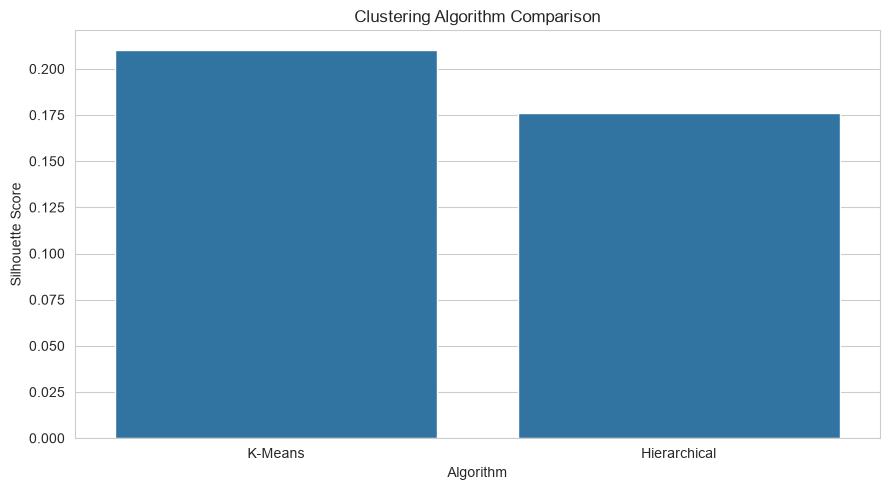

In [149]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_df,
    x='Algorithm',
    y='Silhouette Score'
)

plt.title('Clustering Algorithm Comparison')
plt.ylabel('Silhouette Score')
plt.tight_layout()
plt.show()

## 33. Cluster Profiling

Cluster profiling examines the average business characteristics
of restaurants belonging to each cluster.

It helps understand differences in scale, growth, profitability,
cost structure, and delivery channel dependence.

In [151]:
profile_features = [
    'GrowthFactor',
    'AOV',
    'MonthlyOrders',
    'TotalRevenue',
    'TotalNetProfit',
    'ProfitMargin',
    'CostBurdenRate',
    'AggregatorDependence',
    'DeliveryRadiusKM'
]

available_profile_features = [
    col for col in profile_features
    if col in df.columns
]

cluster_profile = (
    df.groupby('KMeans_Cluster')[available_profile_features]
    .mean()
    .round(2)
)

display(cluster_profile)

,GrowthFactor,AOV,MonthlyOrders,TotalRevenue,TotalNetProfit,ProfitMargin,CostBurdenRate,AggregatorDependence,DeliveryRadiusKM
KMeans_Cluster,,,,,,,,,
0,1.03,39.13,1421.86,55717.86,8872.68,0.16,0.67,0.62,11.24
1,1.03,38.43,1059.10,40641.04,6183.03,0.15,0.63,0.79,10.32
2,1.03,38.14,1284.71,48844.41,-3242.24,-0.07,0.88,0.78,10.50


In [152]:
cluster_size = (
    df['KMeans_Cluster']
    .value_counts()
    .sort_index()
)

cluster_size_df = cluster_size.reset_index()

cluster_size_df.columns = [
    'Cluster',
    'Restaurant Count'
]

display(cluster_size_df)

,Cluster,Restaurant Count
0,0,375
1,1,936
2,2,385


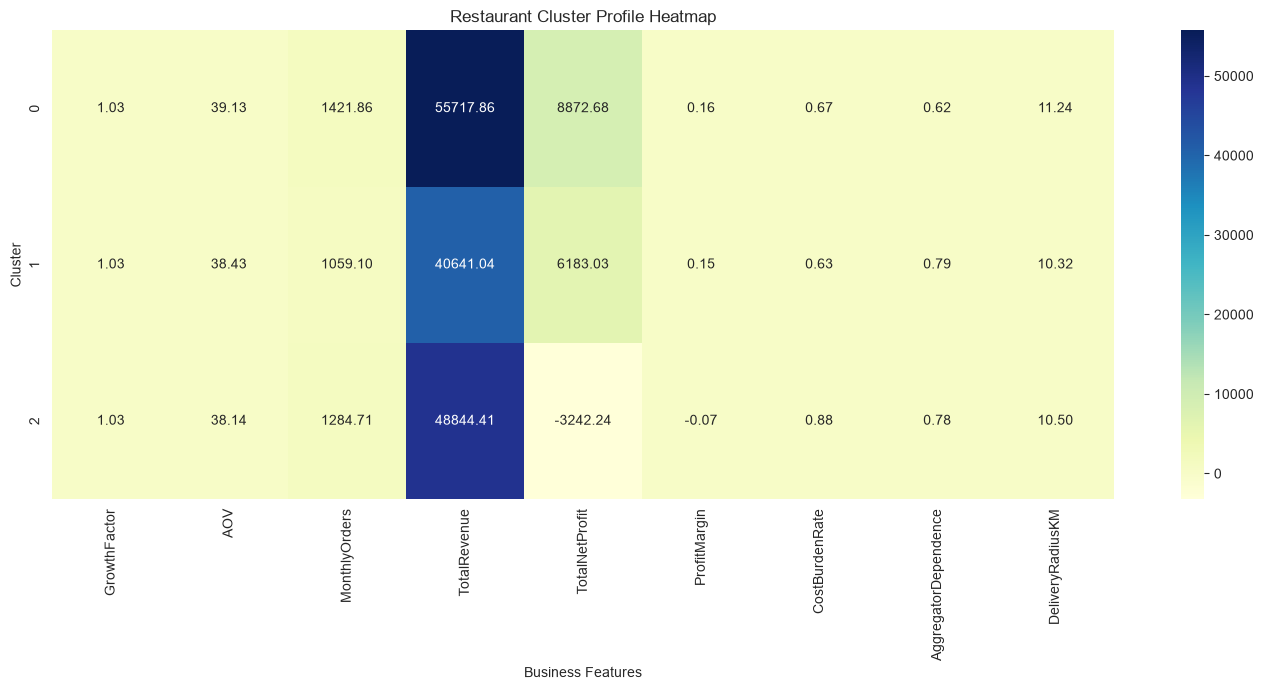

In [153]:
plt.figure(figsize=(14, 7))

sns.heatmap(
    cluster_profile,
    annot=True,
    cmap='YlGnBu',
    fmt='.2f'
)

plt.title('Restaurant Cluster Profile Heatmap')
plt.xlabel('Business Features')
plt.ylabel('Cluster')
plt.tight_layout()
plt.show()

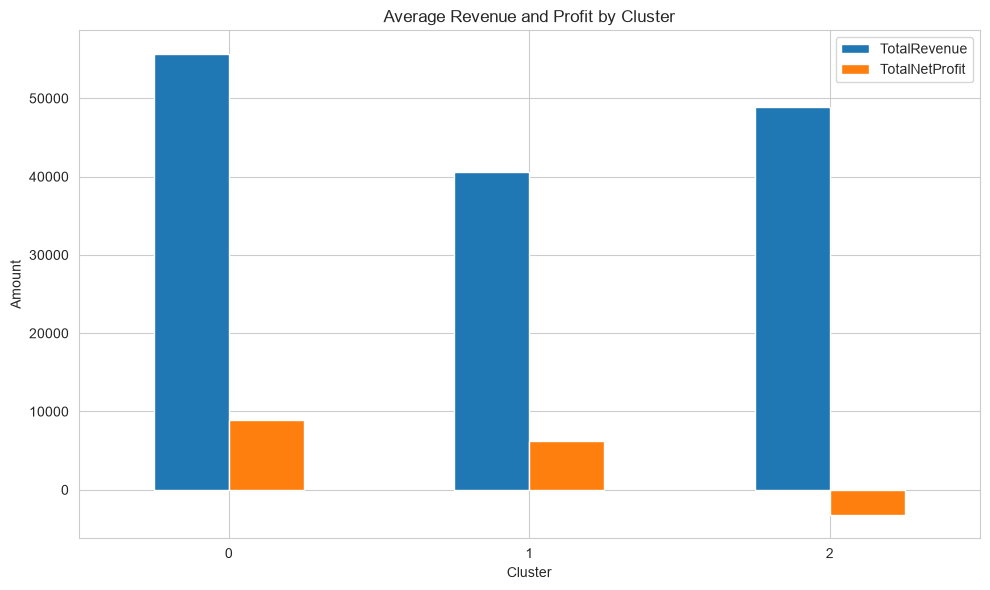

In [154]:
cluster_financials = (
    df.groupby('KMeans_Cluster')[
        ['TotalRevenue', 'TotalNetProfit']
    ]
    .mean()
)

cluster_financials.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Average Revenue and Profit by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 34. Strategic Restaurant Classification

The clusters are interpreted using their business characteristics.

The purpose is to move beyond numerical cluster labels and
identify meaningful restaurant growth profiles.

Possible strategic categories include:

1. Expansion Ready
2. Operationally Strong but Under-Scaled
3. Aggregator Dependent and Margin Fragile
4. Profit Strong but Growth Constrained
5. Stabilize and Optimize

The final categories depend on the actual cluster profiles
and should be assigned using observed business performance.

In [156]:
cluster_means = df.groupby('KMeans_Cluster').agg(
    AverageGrowth=('GrowthFactor', 'mean'),
    AverageOrders=('MonthlyOrders', 'mean'),
    AverageRevenue=('TotalRevenue', 'mean'),
    AverageProfit=('TotalNetProfit', 'mean'),
    AverageMargin=('ProfitMargin', 'mean'),
    AverageCostBurden=('CostBurdenRate', 'mean'),
    AverageAggregatorDependence=('AggregatorDependence', 'mean')
)

display(cluster_means.round(2))

,AverageGrowth,AverageOrders,AverageRevenue,AverageProfit,AverageMargin,AverageCostBurden,AverageAggregatorDependence
KMeans_Cluster,,,,,,,
0,1.03,1421.86,55717.86,8872.68,0.16,0.67,0.62
1,1.03,1059.10,40641.04,6183.03,0.15,0.63,0.79
2,1.03,1284.71,48844.41,-3242.24,-0.07,0.88,0.78


In [157]:
# Calculate dataset-level benchmarks
growth_median = df['GrowthFactor'].median()
orders_median = df['MonthlyOrders'].median()
profit_median = df['TotalNetProfit'].median()
margin_median = df['ProfitMargin'].median()

aggregator_median = (
    df['AggregatorDependence'].median()
    if 'AggregatorDependence' in df.columns
    else 0
)

# Assign a strategic profile to each cluster
def assign_strategy(row):

    if (
        row['AverageGrowth'] >= growth_median
        and row['AverageOrders'] >= orders_median
        and row['AverageProfit'] >= profit_median
        and row['AverageMargin'] >= margin_median
    ):
        return 'Expansion Ready'

    elif (
        row['AverageProfit'] >= profit_median
        and row['AverageGrowth'] < growth_median
        and row['AverageOrders'] < orders_median
    ):
        return 'Operationally Strong but Under-Scaled'

    elif (
        row['AverageAggregatorDependence'] >= aggregator_median
        and row['AverageMargin'] < margin_median
    ):
        return 'Aggregator Dependent and Margin Fragile'

    elif (
        row['AverageProfit'] >= profit_median
        and row['AverageGrowth'] < growth_median
    ):
        return 'Profit Strong but Growth Constrained'

    else:
        return 'Stabilize and Optimize'


cluster_means['StrategicCategory'] = (
    cluster_means.apply(assign_strategy, axis=1)
)

display(cluster_means)

,AverageGrowth,AverageOrders,AverageRevenue,AverageProfit,AverageMargin,AverageCostBurden,AverageAggregatorDependence,StrategicCategory
KMeans_Cluster,,,,,,,,
0,1.030613,1421.858667,55717.858400,8872.682240,0.161699,0.669622,0.615067,Profit Strong but Growth Constrained
1,1.027885,1059.104701,40641.039615,6183.028323,0.152130,0.625117,0.794284,Operationally Strong but Under-Scaled
2,1.026857,1284.714286,48844.407325,-3242.244727,-0.067198,0.875515,0.782597,Stabilize and Optimize


In [158]:
strategy_mapping = cluster_means[
    'StrategicCategory'
].to_dict()

df['StrategicCategory'] = (
    df['KMeans_Cluster'].map(strategy_mapping)
)

display(
    df[
        [
            'RestaurantName',
            'KMeans_Cluster',
            'StrategicCategory',
            'GPI_Score'
        ]
    ].head(15)
)

,RestaurantName,KMeans_Cluster,StrategicCategory,GPI_Score
0,Urban Burgers House,1,Operationally Strong but Under-Scaled,53.020658
1,Urban Burgers Diner,0,Profit Strong but Growth Constrained,59.185078
2,King Burgers Eatery,0,Profit Strong but Growth Constrained,61.273911
3,Classic Burgers Tavern,1,Operationally Strong but Under-Scaled,39.840978
4,Lucky Burgers Bistro,1,Operationally Strong but Under-Scaled,48.953859
5,King Burgers Kitchen,1,Operationally Strong but Under-Scaled,47.771354
6,Urban Burgers Eatery,1,Operationally Strong but Under-Scaled,50.131074
7,Urban Burgers Tavern,1,Operationally Strong but Under-Scaled,56.104448
8,Classic Burgers Tavern,1,Operationally Strong but Under-Scaled,40.006782
9,Lucky Burgers Cafe,1,Operationally Strong but Under-Scaled,43.989962


## 35. Strategic Recommendations

This section creates recommendations for each strategic restaurant
category.

Recommendations focus on sustainable growth, operational improvement,
channel balancing, and profitability.

In [160]:
recommendation_mapping = {

    'Expansion Ready':
        'Consider carefully planned expansion, additional delivery coverage, and market opportunities.',

    'Operationally Strong but Under-Scaled':
        'Increase customer reach, improve marketing, and explore suitable growth channels.',

    'Aggregator Dependent and Margin Fragile':
        'Review aggregator commissions, improve channel mix, and evaluate direct ordering opportunities.',

    'Profit Strong but Growth Constrained':
        'Investigate geographic limitations, demand potential, and selective expansion opportunities.',

    'Stabilize and Optimize':
        'Review operating costs, improve demand generation, and strengthen profitability before expansion.'
}

df['StrategicRecommendation'] = (
    df['StrategicCategory'].map(recommendation_mapping)
)

display(
    df[
        [
            'RestaurantName',
            'StrategicCategory',
            'StrategicRecommendation'
        ]
    ].head(15)
)

,RestaurantName,StrategicCategory,StrategicRecommendation
0,Urban Burgers House,Operationally Strong but Under-Scaled,"Increase customer reach, improve marketing, an..."
1,Urban Burgers Diner,Profit Strong but Growth Constrained,"Investigate geographic limitations, demand pot..."
2,King Burgers Eatery,Profit Strong but Growth Constrained,"Investigate geographic limitations, demand pot..."
3,Classic Burgers Tavern,Operationally Strong but Under-Scaled,"Increase customer reach, improve marketing, an..."
4,Lucky Burgers Bistro,Operationally Strong but Under-Scaled,"Increase customer reach, improve marketing, an..."
5,King Burgers Kitchen,Operationally Strong but Under-Scaled,"Increase customer reach, improve marketing, an..."
6,Urban Burgers Eatery,Operationally Strong but Under-Scaled,"Increase customer reach, improve marketing, an..."
7,Urban Burgers Tavern,Operationally Strong but Under-Scaled,"Increase customer reach, improve marketing, an..."
8,Classic Burgers Tavern,Operationally Strong but Under-Scaled,"Increase customer reach, improve marketing, an..."
9,Lucky Burgers Cafe,Operationally Strong but Under-Scaled,"Increase customer reach, improve marketing, an..."


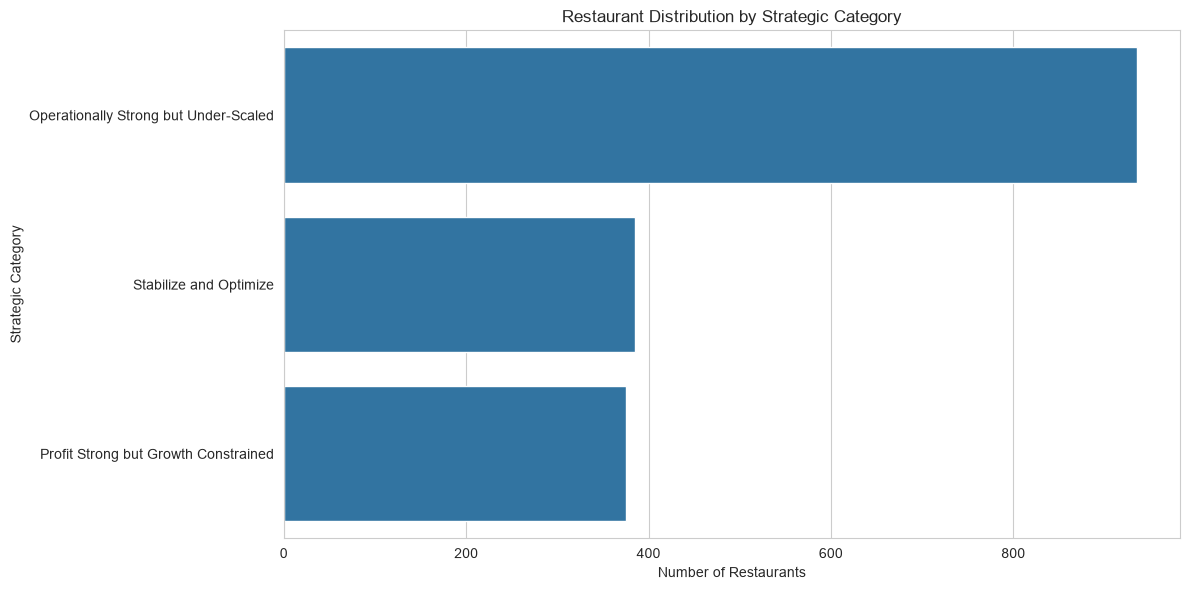

In [161]:
strategy_counts = (
    df['StrategicCategory'].value_counts()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=strategy_counts.values,
    y=strategy_counts.index
)

plt.title('Restaurant Distribution by Strategic Category')
plt.xlabel('Number of Restaurants')
plt.ylabel('Strategic Category')
plt.tight_layout()
plt.show()

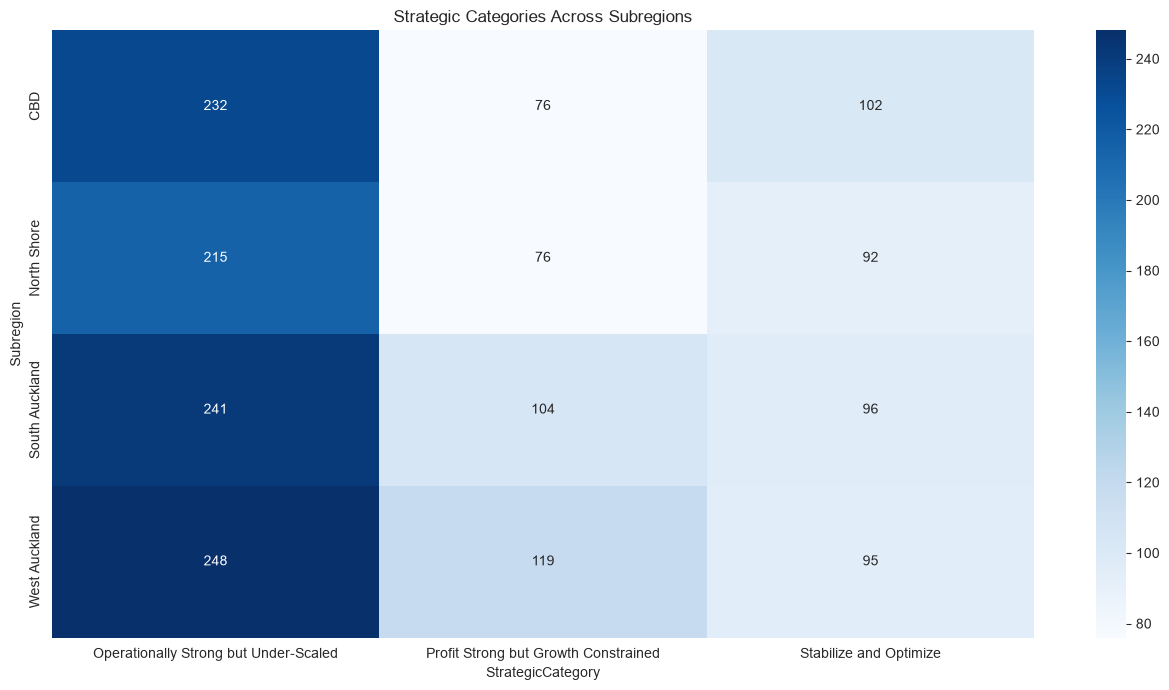

In [162]:
if 'Subregion' in df.columns:

    strategy_region = pd.crosstab(
        df['Subregion'],
        df['StrategicCategory']
    )

    plt.figure(figsize=(13, 7))

    sns.heatmap(
        strategy_region,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.title('Strategic Categories Across Subregions')
    plt.tight_layout()
    plt.show()

## 36. Final Model Evaluation

This section summarizes the selected clustering model,
its evaluation metrics, and the strategic classification results.

In [164]:
print("=" * 55)
print("FINAL RESTAURANT CLUSTERING RESULTS")
print("=" * 55)

print("\nSelected Clustering Model: K-Means")

print(
    "Number of Clusters:",
    best_k
)

print(
    "Silhouette Score:",
    round(kmeans_silhouette, 4)
)

print(
    "Davies-Bouldin Score:",
    round(kmeans_davies, 4)
)

print("\nStrategic Classification Distribution:")

print(
    df['StrategicCategory'].value_counts()
)

print("\nAverage Growth Potential Index:")

print(
    round(df['GPI_Score'].mean(), 2)
)

FINAL RESTAURANT CLUSTERING RESULTS

Selected Clustering Model: K-Means
Number of Clusters: 3
Silhouette Score: 0.2103
Davies-Bouldin Score: 1.6195

Strategic Classification Distribution:
StrategicCategory
Operationally Strong but Under-Scaled    936
Stabilize and Optimize                   385
Profit Strong but Growth Constrained     375
Name: count, dtype: int64

Average Growth Potential Index:
50.82


## 37. Export Final Machine Learning Results

The final dataset includes the original restaurant information,
engineered KPIs, growth potential scores, clustering labels,
strategic categories, and recommendations.

This dataset will be used to develop the final Streamlit dashboard.

In [297]:
import os

os.makedirs('Output', exist_ok=True)

final_output_path = os.path.join(
    'Output',
    'restaurant_growth_final_classification.csv'
)

df.to_csv(
    final_output_path,
    index=False
)

print("Final classification dataset exported successfully.")

print("File:", final_output_path)
if X_reduced.shape[1] >= 2:
    df["PCA_1"] = X_reduced[:, 0]
    df["PCA_2"] = X_reduced[:, 1]

df.to_csv(
    "Output/restaurant_growth_final_classification.csv",
    index=False
)

Final classification dataset exported successfully.
File: Output\restaurant_growth_final_classification.csv


In [299]:
final_columns = [
    'RestaurantName',
    'TotalRevenue',
    'TotalNetProfit',
    'GPI_Score',
    'KMeans_Cluster',
    'StrategicCategory',
    'StrategicRecommendation'
]

available_final_columns = [
    col for col in final_columns
    if col in df.columns
]

display(
    df[available_final_columns].head(20)
)

,RestaurantName,TotalRevenue,TotalNetProfit,GPI_Score,KMeans_Cluster,StrategicCategory,StrategicRecommendation
0,Urban Burgers House,29371.96,7964.56,53.020658,1,Operationally Strong but Under-Scaled,"Increase customer reach, improve marketing, an..."
1,Urban Burgers Diner,56144.60,8775.70,59.185078,0,Profit Strong but Growth Constrained,"Investigate geographic limitations, demand pot..."
2,King Burgers Eatery,68731.51,14403.26,61.273911,0,Profit Strong but Growth Constrained,"Investigate geographic limitations, demand pot..."
3,Classic Burgers Tavern,39291.24,5266.83,39.840978,1,Operationally Strong but Under-Scaled,"Increase customer reach, improve marketing, an..."
4,Lucky Burgers Bistro,42238.20,6119.35,48.953859,1,Operationally Strong but Under-Scaled,"Increase customer reach, improve marketing, an..."
5,King Burgers Kitchen,30499.76,4582.50,47.771354,1,Operationally Strong but Under-Scaled,"Increase customer reach, improve marketing, an..."
6,Urban Burgers Eatery,40807.92,9608.97,50.131074,1,Operationally Strong but Under-Scaled,"Increase customer reach, improve marketing, an..."
7,Urban Burgers Tavern,27792.00,5056.68,56.104448,1,Operationally Strong but Under-Scaled,"Increase customer reach, improve marketing, an..."
8,Classic Burgers Tavern,20067.48,3426.42,40.006782,1,Operationally Strong but Under-Scaled,"Increase customer reach, improve marketing, an..."
9,Lucky Burgers Cafe,20632.04,3748.22,43.989962,1,Operationally Strong but Under-Scaled,"Increase customer reach, improve marketing, an..."


## 38. Machine Learning Conclusion

The machine learning phase applied unsupervised learning techniques
to identify restaurants with similar business characteristics.

Data preprocessing and feature scaling prepared the business
variables for clustering.

Principal Component Analysis was used to reduce the dimensionality
of the dataset and support visualization.

K-Means and Hierarchical Clustering were applied to identify
restaurant groups, while DBSCAN was explored as an additional
density-based clustering technique.

The resulting clusters were profiled using business indicators
such as revenue, profitability, growth factor, monthly orders,
cost burden, and aggregator dependence.

Based on these characteristics, preliminary strategic categories
and recommendations were developed.

The results provide a foundation for a restaurant growth
potential dashboard that can support strategic analysis
and data-driven decision-making.

The final classifications should be validated against business
knowledge and actual restaurant outcomes before being used
for expansion or investment decisions.